# RAG Assignment: Baseline vs. Cross-Encoder Re-Ranking

This notebook is the complete implementation of the assignment. Every step, from reading the PDF to the final tables and figures, is written and explained in the cells below; there are no other code files.

**What it does**

| § | Step |
|---|---|
| 0 | Setup and configuration (all parameters and run flags in one place) |
| 1 | PDF extraction with PyMuPDF (tables kept as rows, check that no text is lost) |
| 2 | Chunking with `RecursiveCharacterTextSplitter` (1000 characters, 200 overlap) |
| 3 | Bi-Encoder embeddings and a FAISS vector index |
| 4 | **Pipeline 1:** top-10 by cosine similarity → top-3 → Gemini **Answer 1** |
| 5 | **Pipeline 2:** Cross-Encoder re-ranks the *same* top-10 → new top-3 → Gemini **Answer 2** |
| 6 | Stress-test question set (33 questions, verified against the PDF), negation screen, retrieval metrics |
| 7 | Rank-shift analysis, Gemini answers (5 runs per case), manual review, Answer 1 vs Answer 2 |
| 8 | Latency profiling and the scaling question |
| 9 | Validation, result tables, figures and the results summary |

**Knowledge source:** `data/document.pdf`, the IIT Madras *Ordinances and Regulations, B.Tech / B.Tech (Honours)*, 2010-2014 batches (25 pages).

**Cheap steps run every time; slow or paid steps are optional.** Extraction, chunking, indexing, the question set, all retrieval metrics and the figures are recomputed on every run. Three steps take a long time or cost API calls: the 60 repeated Gemini answers (§7), the full latency benchmark (§8) and the 30 Gemini timing calls (§8). By default their saved raw measurements are loaded from `results/`; the `RERUN_*` flags in the first code cell redo them from scratch. Every recomputed step is compared with the saved files (the `assert` statements and the "identical ..." lines), and `WRITE_RESULTS = True` rewrites every output file from this run.

**How to run:** open the notebook from the project folder (`rag-assignment/`) with the project's virtual environment. Gemini credentials go in a local `.env` file: either `GEMINI_API_KEY`, or Vertex AI via `GOOGLE_GENAI_USE_VERTEXAI=true` and `GOOGLE_CLOUD_PROJECT`. Without credentials the live LLM cells print a message, and the saved answers are still shown in §7.

## 0. Setup and configuration

In [1]:
# ---- run flags ---------------------------------------------------------------------------
# The default run recomputes everything that is cheap, loads the saved raw measurements of the
# slow / paid steps, and checks that both agree. Turn a RERUN flag on to redo that step from
# scratch; it then saves its new raw measurements (replacing the old ones) so API calls are not wasted.
RUN_LIVE_LLM = True               # 2 Gemini calls: the live Answer 1 / Answer 2 demo in sections 4-5
RERUN_STRESS_GENERATION = False   # 60 Gemini calls: 6 stress cases x 5 runs x 2 answers (section 7)
RERUN_LATENCY_BENCHMARK = False   # ~4 min, no API: 33 questions x 5 timed queries + scaling runs (section 8)
RERUN_LATENCY_GENERATION = False  # 30 Gemini calls: 3 questions x 5 paired answers, end-to-end latency (section 8)
WRITE_RESULTS = False             # (re)write every derived output file in data/ and results/ from this run

# ---- imports -----------------------------------------------------------------------------
import csv, hashlib, json, os, platform, random, re, statistics, time, unicodedata, warnings
from collections import Counter
from datetime import datetime, timezone
from pathlib import Path

import faiss                                     # vector index for the Bi-Encoder search
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pymupdf                                   # PyMuPDF, for reading the PDF
import torch
from dotenv import load_dotenv                   # reads the Gemini credentials from .env
from IPython.display import Markdown, display
from langchain_text_splitters import RecursiveCharacterTextSplitter
from sentence_transformers import CrossEncoder, SentenceTransformer

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 220)

# ---- configuration (one place for every parameter) ----------------------------------------
ROOT = Path(".")
assert (ROOT / "data/document.pdf").exists(), "open this notebook from the project root"
load_dotenv(ROOT / ".env")                       # Gemini credentials; never hard-coded

# input / output locations
SOURCE_PDF = ROOT / "data/document.pdf"
CHUNKS_JSON, PAGES_JSON = ROOT / "data/processed/chunks.json", ROOT / "data/processed/pages.json"
INDEX_DIR = ROOT / "data/index"                  # cached embeddings + FAISS index
EVAL_DIR = ROOT / "data/evaluation"              # the stress-test questions
RESULTS = ROOT / "results"
STRESS_DIR, LAT_DIR = RESULTS / "stress_test", RESULTS / "latency"
TABLES_DIR, FIGURES_DIR = RESULTS / "tables", RESULTS / "figures"

# chunking
CHUNK_SIZE, CHUNK_OVERLAP = 1000, 200            # characters
SEPARATORS = ["\n\n", "\n", ". ", " ", ""]       # paragraph -> line -> sentence -> word -> char

# models
BI_ENCODER_NAME = "sentence-transformers/all-MiniLM-L6-v2"     # first stage: fast dense retrieval
CROSS_ENCODER_NAME = "cross-encoder/ms-marco-MiniLM-L-6-v2"    # second stage: re-ranking
TOP_K_RETRIEVE, TOP_K_CONTEXT = 10, 3            # 10 candidates retrieved, 3 chunks sent to the LLM
GEMINI_MODEL = os.environ.get("GEMINI_MODEL", "gemini-2.5-flash")
SEED = 42

def set_seed(seed):
    # Fix every random number generator so that runs are reproducible.
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

# ---- small file helpers -------------------------------------------------------------------
def now_utc():
    return datetime.now(timezone.utc).isoformat(timespec="seconds")

def read_json(path):
    return json.loads(Path(path).read_text())

def write_json(path, obj):
    # save a result file, creating its folder if needed
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(obj, indent=2, ensure_ascii=False))

def write_rows(path, rows):
    # save a list of dicts as CSV (columns in first-seen order)
    if not rows:
        return
    Path(path).parent.mkdir(parents=True, exist_ok=True)
    fields = list(dict.fromkeys(k for r in rows for k in r))
    with open(path, "w", newline="", encoding="utf-8") as f:
        w = csv.DictWriter(f, fieldnames=fields)
        w.writeheader()
        w.writerows(rows)

set_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"   # use a GPU if there is one
print("device:", DEVICE, "| torch threads:", torch.get_num_threads(), "| LLM:", GEMINI_MODEL)

/home/popos/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


device: cpu | torch threads: 10 | LLM: gemini-2.5-flash


## 1. PDF extraction

This PDF was exported from Word, which creates several extraction problems:

- bullets are private-use "Wingdings" glyphs;
- a Greek question mark stands in for `;`;
- headings are letter-spaced;
- printed page numbers sit inside the text;
- six pages contain tables, which plain text extraction would flatten into one cell per line.

The functions below:

- **Tables:** detect tables and write them as Markdown rows, so each value stays in its column.
- **Normalisation:** clean up the text without dropping words.
- **Paragraphs:** use a blank line only at real paragraph ends. A blank line is the splitter's preferred cut point, and a table caption must stay attached to its table.
- **Flags:** mark suspicious pages instead of dropping them.
- **Word coverage:** compare the cleaned text with PyMuPDF's raw text, so lost content is detected.

In [2]:
# ---- text normalisation ---------------------------------------------------------------------
# Word exports bullets as private-use glyphs; map them (and real bullets) to "- ".
BULLET_GLYPHS = "•●▪"
QUOTE_MAP = str.maketrans({"“": '"', "”": '"', "„": '"', "‟": '"',
                           "‘": "'", "’": "'", "­": None})   # curly quotes, soft hyphen
# A line starting like this begins a new list item / clause and must not be glued to the previous line
NEW_ITEM_RE = re.compile(r"^(- |\(?[a-z]\)|\(?[ivx]+\)|\d+\.\s|[RO]\.\d)")

def clean_text(text):
    # Normalise one text block while keeping every word.
    text = unicodedata.normalize("NFKC", text).translate(QUOTE_MAP)   # NFKC also fixes the Greek ';'
    text = re.sub(f"[{BULLET_GLYPHS}]\\s*", "- ", text)                 # bullets -> "- "
    text = re.sub(r"\b(?:[A-Z] ){3,}[A-Z]\b", lambda m: m.group(0).replace(" ", ""), text)  # C O N T E N T S
    text = re.sub(r"(?<=[a-z])-\n(?=[a-z])", "", text)                  # re-join hyphenated words
    out = []
    for line in text.split("\n"):
        line = re.sub(r"\s+", " ", line).strip()
        if not line:
            continue
        if out and not NEW_ITEM_RE.match(line):
            out[-1] += " " + line          # wrapped line -> same paragraph
        else:
            out.append(line)               # list item / clause number -> new line
    return "\n".join(out)

# ---- tables -------------------------------------------------------------------------------
def table_to_markdown(table):
    # Write a detected table as Markdown rows, so every value stays in its column.
    # Built from the raw cells (not table.to_markdown(), whose '**' bold markers would clash with
    # this document's '**' footnote = B.Tech Honours). Empty cells are kept so columns stay aligned.
    rows = table.extract()
    if table.header.external:                  # header row found above the table body
        rows = [table.header.names] + rows
    cell = lambda c: re.sub(r"\s+", " ", unicodedata.normalize("NFKC", c or "")).strip()
    lines = []
    for i, row in enumerate(rows):
        lines.append("| " + " | ".join(cell(c) for c in row) + " |")
        if i == 0:
            lines.append("|" + " --- |" * len(row))   # Markdown header separator
    return "\n".join(lines).translate(QUOTE_MAP)

def inside(rect, table_rects, min_frac=0.5):
    # True if at least half of a text line's box lies inside one of the detected tables.
    area = rect.get_area() or 1.0
    return any((rect & t).get_area() / area >= min_frac for t in table_rects)

# ---- joining text blocks ------------------------------------------------------------------
def join_separator(prev, nxt):
    # Choose what goes between two pieces of text:
    # ' ' mid-sentence, '\n' after an unterminated line, '\n\n' after a sentence or a table/footnote.
    # '\n\n' is the splitter's preferred cut point, so it is only used at real paragraph ends.
    if re.match(r"[|*]", prev.rsplit("\n", 1)[-1]):
        return "\n\n"
    if re.search(r"[a-z,]$", prev) and re.match(r"[a-z]", nxt):
        return " "
    if not re.search(r"[.:;?!]$", prev):
        return "\n"
    return "\n\n"

# ---- one page -----------------------------------------------------------------------------
def extract_page(page):
    # Return (cleaned_text, n_tables, printed_page_number) for one page.
    tables = page.find_tables().tables
    table_rects = [pymupdf.Rect(t.bbox) for t in tables]
    items = []                                           # (y, x, kind, text) in reading order
    for block in page.get_text("dict", sort=True)["blocks"]:
        if block["type"] != 0:                           # skip image blocks
            continue
        # filter per LINE: PyMuPDF sometimes puts a table and the footnote below it in one block
        lines = ["".join(s["text"] for s in line["spans"]) for line in block["lines"]
                 if not (table_rects and inside(pymupdf.Rect(line["bbox"]), table_rects))]
        text = clean_text("\n".join(lines))
        if text:
            items.append((block["bbox"][1], block["bbox"][0], "text", text))
    # add each table as one item at its position on the page
    for t, r in zip(tables, table_rects):
        items.append((r.y0, r.x0, "table", table_to_markdown(t)))
    items.sort(key=lambda it: (round(it[0]), it[1]))     # top-to-bottom, then left-to-right

    # The printed page number (= PDF page - 1, the cover is unnumbered) sits alone at the top or
    # bottom. Move it out of the text into metadata so it does not pollute the chunks.
    printed = None
    for idx in (0, -1):
        if items and re.fullmatch(r"\d{1,3}", items[idx][3]) and int(items[idx][3]) == page.number:
            printed = int(items.pop(idx)[3])
            break

    # glue the items together with the right separator
    text = ""
    for i, (_, _, kind, item) in enumerate(items):
        if i:
            prev_kind = items[i - 1][2]
            if prev_kind == "text" and kind == "table":
                text += "\n"                             # caption stays glued to its table
            elif prev_kind == "table" and item.startswith("*"):
                text += "\n"                             # '*' footnote stays with its table
            elif prev_kind == kind == "text":
                text += join_separator(text, item)
            else:
                text += "\n\n"
        text += item
    return text, len(tables), printed

# ---- quality check ------------------------------------------------------------------------
def word_coverage(raw, cleaned):
    # Share of the raw page's alphanumeric tokens that survive cleaning (detects silent text loss).
    tok = lambda s: Counter(re.findall(r"[A-Za-z0-9]+", unicodedata.normalize("NFKC", s)))
    r, c = tok(raw), tok(cleaned)
    total = sum(r.values())
    return 1.0 if total == 0 else sum(min(n, c[w]) for w, n in r.items()) / total

# ---- whole document -----------------------------------------------------------------------
def extract_pages(pdf_path, min_chars=200):
    # Extract every page. No page is dropped; suspicious pages are only flagged.
    doc = pymupdf.open(pdf_path)
    pages = []
    for page in doc:
        raw = page.get_text("text")                      # PyMuPDF's plain text, used as a reference
        text, n_tables, printed = extract_page(page)
        n_images = len(page.get_images())
        flags = []
        if not text:
            flags.append("empty")
        elif len(text) < min_chars:
            flags.append("low_text")
        if n_images and len(text) < min_chars:
            flags.append("image_low_text")               # probably needs OCR
        if n_tables:
            flags.append("has_tables")
        odd = sum(1 for ch in text if ch == "�" or "" <= ch <= "")  # unmapped glyphs
        if text and odd / len(text) > 0.01:
            flags.append("garbled")
        cov = word_coverage(clean_text(raw), f"{text} {printed or ''}")
        if cov < 0.98:
            flags.append("content_loss")
        pages.append({"page": page.number + 1, "printed_page": printed, "text": text, "char_count": len(text),
                      "n_tables": n_tables, "n_images": n_images, "word_coverage": round(cov, 4), "flags": flags})
    doc.close()
    assert any(p["text"] for p in pages), "no text layer: the PDF would need OCR"
    return pages

In [3]:
# Run the extraction and compare it with the saved copy.
t0 = time.perf_counter()
pages = extract_pages(SOURCE_PDF)
page_df = pd.DataFrame(pages)
print(f"{len(pages)} pages extracted in {time.perf_counter() - t0:.1f} s | with text: {(page_df.char_count > 0).sum()} "
      f"| with tables: {page_df.loc[page_df.n_tables > 0, 'page'].tolist()} | min word coverage: {page_df.word_coverage.min()}")
saved_pages = json.loads(PAGES_JSON.read_text())["pages"]
print("identical to saved data/processed/pages.json:", [p["text"] for p in pages] == [p["text"] for p in saved_pages])

# show only the suspicious pages (anything flagged apart from "has_tables")
display(page_df[page_df["flags"].map(lambda f: bool(set(f) - {"has_tables"}))]
        [["page", "char_count", "n_images", "word_coverage", "flags"]])

# example: the grade table on PDF page 21, with its rows preserved
p21 = pages[20]["text"]
print(p21[p21.index("| Grade"):][:330])

Consider using the pymupdf_layout package for a greatly improved page layout analysis.


25 pages extracted in 1.2 s | with text: 25 | with tables: [10, 11, 12, 18, 20, 21] | min word coverage: 1.0
identical to saved data/processed/pages.json: True


,page,char_count,n_images,word_coverage,flags
0,1,150,1,1.0,"[low_text, image_low_text]"


| Grade | Grade Points | Remarks |
| --- | --- | --- |
| S | 10 |  |
| A | 9 |  |
| B | 8 |  |
| C | 7 |  |
| D | 6 |  |
| E | 4 |  |
| U | 0 |  |
| P | - | Pass |
| F | 0 | Fail |
| W | 0 | Failure due to insufficient attendance in course |
| I | 0 | Incomplete (subsequently to be changed into pass (E to S) or U grade in the sa


## 2. Chunking

**Splitter:** LangChain `RecursiveCharacterTextSplitter` with `chunk_size=1000` and `chunk_overlap=200` characters.

**Whole-document split:** pages are joined with the same separator rule used between paragraphs, so a clause that continues onto the next page can stay in one chunk. Each chunk's character offsets are mapped back to the page(s) it covers.

**Chunk IDs:** `chunk_id` is the chunk's position in document order. It is deterministic, and it equals the chunk's row in the FAISS index.

In [4]:
def chunk_document(pages, source):
    # Split the whole document into overlapping chunks and remember which page(s) each chunk covers.
    # 1) join all pages into one text; spans records where each page starts and ends in it
    full_text, spans, pos = "", [], 0                  # spans: (page, start, end) in full_text
    for p in pages:
        if full_text and p["text"]:
            sep = join_separator(full_text, p["text"])
            full_text += sep
            pos += len(sep)
        full_text += p["text"]
        spans.append((p["page"], pos, pos + len(p["text"])))
        pos += len(p["text"])
    # 2) split with LangChain: tries paragraph breaks first, then lines, sentences, words
    splitter = RecursiveCharacterTextSplitter(chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP,
                                              separators=SEPARATORS, keep_separator="end",
                                              add_start_index=True, strip_whitespace=True)
    # 3) map each chunk's character offsets back to page numbers
    chunks = []
    for d in splitter.create_documents([full_text]):
        text, start = d.page_content, d.metadata["start_index"]
        end = start + len(text)
        pg = [p for p, s, e in spans if s < end and e > start and e > s]
        chunks.append({"chunk_id": len(chunks), "source": source, "page_start": pg[0], "page_end": pg[-1],
                       "pages": pg, "text": text, "char_count": len(text), "start_index": start, "end_index": end,
                       "chunk_hash": hashlib.sha1(text.encode()).hexdigest()[:12]})   # detects changed chunks
    return chunks, full_text

def validate_chunks(chunks, full_text, n_pages):
    # Structural checks; returns a list of problems (empty list = everything is fine).
    problems = []
    for i, c in enumerate(chunks):
        if c["chunk_id"] != i:
            problems.append(f"{i}: id")
        if not c["text"].strip() or c["char_count"] != len(c["text"]) or c["char_count"] > CHUNK_SIZE:
            problems.append(f"{i}: text/length")
        if not 1 <= c["page_start"] <= c["page_end"] <= n_pages:
            problems.append(f"{i}: pages")
        if full_text[c["start_index"]:c["end_index"]] != c["text"]:
            problems.append(f"{i}: offsets")
    # every non-whitespace character of the document must end up in at least one chunk
    covered = bytearray(len(full_text))
    for c in chunks:
        covered[c["start_index"]:c["end_index"]] = b"\x01" * c["char_count"]
    lost = sum(1 for ch, cv in zip(full_text, covered) if not cv and not ch.isspace())
    if lost:
        problems.append(f"{lost} characters not in any chunk")
    return problems

def page_label(c):
    # "p. 4" or "pp. 4-5" (PDF page numbers), used in the prompt and in tables
    return f"p. {c['page_start']}" if c["page_start"] == c["page_end"] else f"pp. {c['page_start']}-{c['page_end']}"

chunks, full_text = chunk_document(pages, SOURCE_PDF.name)
assert not validate_chunks(chunks, full_text, len(pages))
saved_chunks = json.loads(CHUNKS_JSON.read_text())["chunks"]
print(f"{len(chunks)} chunks | identical to saved chunks.json: "
      f"{[c['chunk_hash'] for c in chunks] == [c['chunk_hash'] for c in saved_chunks]}")
# metadata stored with the corpus files (also used by the question set and the results summary)
CHUNK_META = {"source_pdf": SOURCE_PDF.name, "source_sha256": hashlib.sha256(SOURCE_PDF.read_bytes()).hexdigest(),
              "n_pages": len(pages), "n_chunks": len(chunks), "chunk_size": CHUNK_SIZE, "chunk_overlap": CHUNK_OVERLAP,
              "separators": SEPARATORS, "splitter": "langchain_text_splitters.RecursiveCharacterTextSplitter",
              "extract_tables": True, "page_numbering": "1-based PDF page index (printed page number = PDF page - 1)",
              "created_utc": now_utc()}
if WRITE_RESULTS:
    write_json(PAGES_JSON, {"metadata": CHUNK_META, "pages": pages})
    write_json(CHUNKS_JSON, {"metadata": CHUNK_META, "chunks": chunks})

# chunk statistics and one example chunk
L = pd.Series([c["char_count"] for c in chunks])
print(f"length (chars): mean {L.mean():.0f}, median {L.median():.0f}, min {L.min()}, max {L.max()} | "
      f"spanning 2 pages: {sum(len(c['pages']) > 1 for c in chunks)}")
chunks_by_id = {c["chunk_id"]: c for c in chunks}      # fast lookup by id, used everywhere below
print(f"\nchunk 42 ({page_label(chunks[42])}):\n{chunks[42]['text'][:420]} ...")

85 chunks | identical to saved chunks.json: True
length (chars): mean 699, median 761, min 109, max 994 | spanning 2 pages: 14

chunk 42 (pp. 14-15):
- Should have a minimum of 8.0 CGPA from 2011 batch at the end of 5th semester
- Should not have any backlog courses
R.5.8 Dual degree students are not eligible for branch/ programme change to 4-year B.Tech programme. However, they are eligible for change of discipline within the same Department, in case the Department offers more than one discipline under their dual degree programme. From 2012 batch, Applied Mechani ...


## 3. Bi-Encoder embeddings and FAISS index

**Encoding:** the Bi-Encoder encodes every chunk **independently**, once, before any query arrives. Vectors are L2-normalised, so inner product = cosine similarity, and `IndexFlatIP` performs exact cosine search.

**Cache:** embeddings, the index and the row → `chunk_id` map are saved in `data/index/`. The cache is keyed by a fingerprint of the chunk texts and the model name, so it is rebuilt automatically when the chunks change.

In [5]:
# Load the Bi-Encoder (all-MiniLM-L6-v2, 384-dimensional sentence embeddings).
bi_encoder = SentenceTransformer(BI_ENCODER_NAME, device=DEVICE)

def embed(texts):
    # unit-length float32 vectors -> inner product == cosine similarity
    return bi_encoder.encode(texts, batch_size=32, convert_to_numpy=True,
                             normalize_embeddings=True, show_progress_bar=False).astype("float32")

def fingerprint(chunks):
    # Identifies the exact chunk texts + model an index was built from (used to validate the cache).
    h = hashlib.sha256(BI_ENCODER_NAME.encode())
    for c in chunks:
        h.update(f"{c['chunk_id']}:{c['chunk_hash']}".encode())
    return h.hexdigest()

def load_or_build_index(chunks):
    # Reuse the cached index if it was built from these exact chunks; otherwise build and save it.
    meta_p, idx_p, emb_p = INDEX_DIR / "index_meta.json", INDEX_DIR / "faiss.index", INDEX_DIR / "embeddings.npy"
    fp = fingerprint(chunks)
    if meta_p.exists() and json.loads(meta_p.read_text()).get("fingerprint") == fp:
        meta = json.loads(meta_p.read_text())
        return faiss.read_index(str(idx_p)), meta["id_map"], np.load(emb_p), False
    emb = embed([c["text"] for c in chunks])                # offline cost, paid once
    index = faiss.IndexFlatIP(emb.shape[1])                  # exact inner-product search
    index.add(emb)
    id_map = [c["chunk_id"] for c in chunks]                 # FAISS row -> chunk_id
    INDEX_DIR.mkdir(parents=True, exist_ok=True)
    np.save(emb_p, emb)
    faiss.write_index(index, str(idx_p))
    meta_p.write_text(json.dumps({"fingerprint": fp, "model": BI_ENCODER_NAME, "id_map": id_map}))
    return index, id_map, emb, True

t0 = time.perf_counter()
index, id_map, chunk_emb, built = load_or_build_index(chunks)
print(f"index {'built' if built else 'loaded from cache'} in {time.perf_counter() - t0:.2f} s: "
      f"{index.ntotal} vectors x {index.d} dims | unit norm: {np.allclose(np.linalg.norm(chunk_emb, axis=1), 1, atol=1e-4)}")
CORPUS_FP = fingerprint(chunks)          # identifies this corpus + model in the saved results

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

index loaded from cache in 0.00 s: 85 vectors x 384 dims | unit norm: True


## 4. Pipeline 1: baseline top-10 → top-3 → Answer 1

**Demo query:** stress-test question **KT-02**, a *keyword trap*.

- The answer is R.1.12 on p. 8: CGPA 8.5 at the end of the 3rd semester, opting during the 4th.
- R.30.1 on p. 25 shares the words "B.Tech (Honours)" and "CGPA 8.5", but it is about *keeping* 8.5 to be *awarded* the degree.

In [6]:
def baseline_retrieve(query, k=TOP_K_RETRIEVE):
    # Pipeline 1, step (b): encode the query with the same Bi-Encoder and take the k nearest chunks
    # by cosine similarity. Each result keeps its baseline rank and cosine score.
    scores, rows = index.search(embed([query]), k)
    return [dict(chunks_by_id[id_map[int(r)]], baseline_rank=i + 1, cosine_score=float(s))
            for i, (r, s) in enumerate(zip(rows[0], scores[0]))]

QUERY = "What CGPA does a student need in order to opt for the B.Tech (Honours) programme, and when can they opt?"
candidates = baseline_retrieve(QUERY)                     # the top-10, shared by BOTH pipelines
baseline_top3 = candidates[:TOP_K_CONTEXT]                # Pipeline 1, step (c): ranks 1-3, unchanged

# show the top-10 with the chunks that go to the LLM marked
pd.DataFrame([{"rank": c["baseline_rank"], "chunk": c["chunk_id"], "pages": page_label(c),
               "cosine": round(c["cosine_score"], 4), "to LLM": c["baseline_rank"] <= 3,
               "text": c["text"][:85].replace("\n", " ")} for c in candidates])

,rank,chunk,pages,cosine,to LLM,text
0,1,78,p. 23,0.7502,True,"For the cumulative grade point average (CGPA), a similar formula is used where the su"
1,2,84,p. 25,0.7229,True,The CGPA calculation based on credits earned/completed at IIT Madras alone is to be c
2,3,33,p. 12,0.7062,True,The minimum number of credits to be earned for the award of the B.Tech. Degree is 180
3,4,21,p. 8,0.6728,False,R.1.10 A student can have only two attempts to write JEE / JEE (Advanced) from 2013.
4,5,45,p. 15,0.6644,False,R.6.4 The B.Tech students are also eligible to take extra courses apart from the cour
5,6,53,p. 17,0.6619,False,"Thereafter, he/she must maintain an average of 15 credits per semester, including the"
6,7,82,p. 24,0.6583,False,The Dean of Academic Courses will lay down the administrative procedures to be follow
7,8,12,pp. 5-6,0.6377,False,In addition; candidates who are eligible to seek admission as foreign nationals or un
8,9,34,p. 12,0.6373,False,B.Tech (Honours) students can register for a maximum of 2 additional PMT courses in a
9,10,76,pp. 22-23,0.6233,False,"A student securing a U or W grade in an elective course, may repeat it if he/she so d"


In [7]:
# ONE prompt template, used unchanged by both pipelines; only {context} differs.
PROMPT_TEMPLATE = '''You are answering a question about the IIT Madras B.Tech / B.Tech (Honours) Ordinances and Regulations, using excerpts retrieved from that document.

Rules:
- Use only the provided context. Do not use outside knowledge and do not invent facts, numbers or rules.
- Cite the supporting chunk and page for every claim, e.g. [Chunk 12, p. 5].
- Pay attention to conditions, exceptions and batch-specific variations stated in the context.
- If the context does not contain enough evidence to answer fully, say so explicitly and state what is missing.

Context:
{context}

Question:
{query}

Answer:'''
# Same generation settings for both answers; temperature 0 keeps the output as stable as possible.
# max_output_tokens is generous because Gemini 2.5 "thinking" tokens count towards it.
GENERATION_SETTINGS = {"temperature": 0.0, "top_p": 1.0, "max_output_tokens": 8192, "seed": 42}  # identical for both

def format_context(ctx):
    # Each chunk is labelled with its id and page so the model can cite it.
    return "\n\n".join(f"[Chunk {c['chunk_id']} | {page_label(c)}]\n{c['text']}" for c in ctx)

def build_prompt(query, ctx):
    assert len(ctx) == TOP_K_CONTEXT              # both pipelines always pass exactly 3 chunks
    return PROMPT_TEMPLATE.format(context=format_context(ctx), query=query)

def use_vertex():
    return os.environ.get("GOOGLE_GENAI_USE_VERTEXAI", "").lower() in ("1", "true", "yes")

def describe_backend():
    # One-line description of the Gemini backend; it is stored with every generated answer.
    if use_vertex():
        return (f"Vertex AI (project={os.environ.get('GOOGLE_CLOUD_PROJECT')}, "
                f"location={os.environ.get('GOOGLE_CLOUD_LOCATION', 'global')})")
    return "Gemini Developer API (API key)" if os.environ.get("GEMINI_API_KEY") else "no credentials configured"

def get_client():
    # Vertex AI (GOOGLE_GENAI_USE_VERTEXAI=true + GOOGLE_CLOUD_PROJECT) or a Gemini API key; None if neither
    from google import genai
    if use_vertex():
        project = os.environ.get("GOOGLE_CLOUD_PROJECT")
        return genai.Client(vertexai=True, project=project,
                            location=os.environ.get("GOOGLE_CLOUD_LOCATION", "global")) if project else None
    key = os.environ.get("GEMINI_API_KEY")
    return genai.Client(api_key=key) if key else None

# a client is only created when some cell is going to call Gemini
NEED_LLM = RUN_LIVE_LLM or RERUN_STRESS_GENERATION or RERUN_LATENCY_GENERATION
client = get_client() if NEED_LLM else None
LLM_BACKEND = describe_backend()
print("LLM client:", LLM_BACKEND if client else "none (live calls off or no credentials)")

def generate(query, ctx, retries=4):
    # One Gemini answer. Returns (answer, seconds) or, on failure, (None, error message).
    # Never fabricates an answer. Rate limits / overloads are retried with exponential back-off.
    if client is None:
        return None, "no Gemini client"
    from google.genai import types
    cfg = types.GenerateContentConfig(**GENERATION_SETTINGS, http_options=types.HttpOptions(timeout=60_000))
    for attempt in range(retries + 1):
        try:
            t0 = time.perf_counter()
            r = client.models.generate_content(model=GEMINI_MODEL, contents=build_prompt(query, ctx), config=cfg)
            if (r.text or "").strip():
                return r.text.strip(), time.perf_counter() - t0      # (answer, seconds)
            raise RuntimeError(f"empty response (finish reason: {r.candidates[0].finish_reason})")
        except Exception as exc:
            # client errors other than rate limits (bad key, bad request) will not succeed on retry
            code = getattr(exc, "code", None)
            if attempt == retries or (isinstance(code, int) and 400 <= code < 500 and code != 429):
                return None, f"{type(exc).__name__}: {str(exc)[:200]}"
            wait = 2 ** attempt * 5
            hinted = re.search(r"retry in ([\d.]+)s", str(exc))     # on 429 the API says how long to wait
            if hinted:
                wait = max(wait, float(hinted.group(1)) + 2)
            print(f"[gemini] attempt {attempt + 1} failed ({str(exc)[:100]}); retrying in {wait:.0f}s")
            time.sleep(wait)

# Answer 1: generated from the baseline top-3
answer_1, info_1 = generate(QUERY, baseline_top3) if RUN_LIVE_LLM else (None, "RUN_LIVE_LLM is off")
print(f"ANSWER 1 (baseline top-3 {[c['chunk_id'] for c in baseline_top3]})",
      f"[{info_1:.1f} s]" if answer_1 else f"[not generated: {info_1}]")
print(answer_1 or "")

LLM client: Vertex AI (project=lma-ass1, location=global)


ANSWER 1 (baseline top-3 [78, 84, 33]) [4.9 s]
To be awarded the B.Tech (Honours) degree, students must maintain an average CGPA of 8.5 [Chunk 84, p. 25]. If this CGPA is not maintained, they will be awarded only the B.Tech Degree [Chunk 84, p. 25].

The provided context does not specify a CGPA required to *opt* for the B.Tech (Honours) programme, nor does it state when a student can opt for it. It only details the CGPA requirement for the *award* of the degree to students who are already B.Tech (Honours) students.


## 5. Pipeline 2: Cross-Encoder re-ranking → new top-3 → Answer 2

**How it scores:** the Cross-Encoder reads the query and a chunk **together** as one input, so self-attention runs across the tokens of both. It scores exactly the 10 candidates from §4. There is no second search.

**Scores are not comparable:** its output is an unbounded relevance **logit**, on a different scale from cosine similarity. The two scores are shown in separate columns, and only rank orders are compared.

In [8]:
# Load the Cross-Encoder (trained on MS MARCO passage ranking).
cross_encoder = CrossEncoder(CROSS_ENCODER_NAME, device=DEVICE)

def rerank(query, candidates):
    # Pipeline 2, steps (a)-(c): score all 10 (query, chunk) pairs jointly, then sort by that score.
    ce = cross_encoder.predict([(query, c["text"]) for c in candidates], show_progress_bar=False)
    # sorted() is stable, so ties keep the original baseline order
    out = sorted([dict(c, ce_score=float(s)) for c, s in zip(candidates, ce)], key=lambda c: -c["ce_score"])
    for new_rank, c in enumerate(out, 1):
        c["reranked_rank"], c["rank_change"] = new_rank, c["baseline_rank"] - new_rank   # + = promoted
    assert sorted(c["chunk_id"] for c in out) == sorted(c["chunk_id"] for c in candidates)  # reorder only
    return out

reranked = rerank(QUERY, candidates)                      # same 10 candidates, no second search
reranked_top3 = reranked[:TOP_K_CONTEXT]

# both scores side by side; cosine and CE logit are on different scales, so only the ranks are compared
pd.DataFrame([{"new rank": c["reranked_rank"], "baseline rank": c["baseline_rank"], "change": f"{c['rank_change']:+d}",
               "chunk": c["chunk_id"], "pages": page_label(c), "cosine": round(c["cosine_score"], 4),
               "CE logit": round(c["ce_score"], 3), "text": c["text"][:70].replace("\n", " ")} for c in reranked])

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

,new rank,baseline rank,change,chunk,pages,cosine,CE logit,text
0,1,4,+3,21,p. 8,0.6728,4.333,R.1.10 A student can have only two attempts to write JEE / JEE (Advanc
1,2,8,+6,12,pp. 5-6,0.6377,4.138,In addition; candidates who are eligible to seek admission as foreign
2,3,1,-2,78,p. 23,0.7502,2.365,"For the cumulative grade point average (CGPA), a similar formula is us"
3,4,9,+5,34,p. 12,0.6373,2.012,B.Tech (Honours) students can register for a maximum of 2 additional P
4,5,2,-3,84,p. 25,0.7229,1.959,The CGPA calculation based on credits earned/completed at IIT Madras a
5,6,3,-3,33,p. 12,0.7062,1.826,The minimum number of credits to be earned for the award of the B.Tech
6,7,5,-2,45,p. 15,0.6644,1.101,R.6.4 The B.Tech students are also eligible to take extra courses apar
7,8,6,-2,53,p. 17,0.6619,0.556,"Thereafter, he/she must maintain an average of 15 credits per semester"
8,9,7,-2,82,p. 24,0.6583,-0.768,The Dean of Academic Courses will lay down the administrative procedur
9,10,10,+0,76,pp. 22-23,0.6233,-3.791,"A student securing a U or W grade in an elective course, may repeat it"


In [9]:
# Pipeline 2, step (d): Answer 2 from the re-ranked top-3, same prompt and settings as Answer 1.
answer_2, info_2 = generate(QUERY, reranked_top3) if RUN_LIVE_LLM else (None, "RUN_LIVE_LLM is off")
print("baseline top-3 :", [c["chunk_id"] for c in baseline_top3], "| re-ranked top-3:", [c["chunk_id"] for c in reranked_top3])
print("\nANSWER 2 (re-ranked top-3)", f"[{info_2:.1f} s]" if answer_2 else f"[not generated: {info_2}]")
print(answer_2 or "")

# Controls: the prompt is identical outside the context block; same model + settings; 3 chunks each.
strip = lambda q, ctx: build_prompt(q, ctx).replace(format_context(ctx), "<CONTEXT>")
assert strip(QUERY, baseline_top3) == strip(QUERY, reranked_top3)
print("\ncontrols OK: identical prompt template, model and settings; only the 3 context chunks differ")

baseline top-3 : [78, 84, 33] | re-ranked top-3: [21, 12, 78]

ANSWER 2 (re-ranked top-3) [3.8 s]
To opt for the B.Tech (Honours) programme, a student must have a CGPA of 8.5 and above at the end of their third semester [Chunk 21, p. 8].

Students can opt for the B.Tech (Honours) programme during the fourth semester [Chunk 21, p. 8]. This option is available at the end of the fourth semester of the B.Tech programme, subject to conditions prescribed by the Senate [Chunk 12, p. 5]. In addition to the CGPA requirement, students must have cleared all courses as prescribed in the curriculum in the first attempt and should not have obtained a "U" or "W" grade in any course to be eligible [Chunk 21, p. 8].

controls OK: identical prompt template, model and settings; only the 3 context chunks differ


In [10]:
def compare_pipelines(query):
    # Both pipelines for one question, as used for the stress-test answers in section 7.
    # The vector search runs ONCE and both pipelines get the identical top-10; the prompt, model and
    # settings are shared, so the choice of the 3 context chunks is the only difference.
    cands = baseline_retrieve(query)
    reranked_ = rerank(query, cands)
    top1, top2 = cands[:TOP_K_CONTEXT], reranked_[:TOP_K_CONTEXT]
    a1, info1 = generate(query, top1)
    a2, info2 = generate(query, top2)

    # experimental controls (stored with every answer pair)
    strip_ctx = lambda ctx: build_prompt(query, ctx).replace(format_context(ctx), "<CONTEXT>")
    ids = [c["chunk_id"] for c in cands]
    checks = {
        "same_source_pdf": all(chunks_by_id[i]["source"] == SOURCE_PDF.name for i in ids),
        "same_top10_ids_and_order": True,              # one shared search, by construction
        "same_top10_scores": True,
        "reranked_set_equals_top10": sorted(c["chunk_id"] for c in reranked_) == sorted(ids),
        "reranked_top3_from_top10": {c["chunk_id"] for c in top2} <= set(ids),
        "both_use_3_chunks": len(top1) == len(top2) == TOP_K_CONTEXT,
        "same_llm_model": True,
        "same_prompt_outside_context": strip_ctx(top1) == strip_ctx(top2)
                                       == PROMPT_TEMPLATE.format(context="<CONTEXT>", query=query),
        "generation_settings": dict(GENERATION_SETTINGS),
    }
    return {
        "baseline_top3": [c["chunk_id"] for c in top1],
        "reranked_top3": [c["chunk_id"] for c in top2],
        "rank_changes": [{"chunk_id": c["chunk_id"], "baseline_rank": c["baseline_rank"],
                          "reranked_rank": c["reranked_rank"], "rank_change": c["rank_change"],
                          "cosine_score": c["cosine_score"], "ce_score": c["ce_score"],
                          "pages": [c["page_start"], c["page_end"]]}
                         for c in sorted(reranked_, key=lambda c: c["baseline_rank"])],
        "answer_1": a1, "answer_1_error": None if a1 else info1,
        "answer_2": a2, "answer_2_error": None if a2 else info2,
        "prompt_1": build_prompt(query, top1), "prompt_2": build_prompt(query, top2),
        "llm_model": GEMINI_MODEL, "checks": checks,
    }

Gemini 2.5 Flash is not fully deterministic, even at `temperature=0` with a seed, so the live answers above can be worded differently from the saved, reviewed answers in §7.

## 6. Stress tests: 33 verified, document-specific questions

The question set has 33 questions in six categories:

| Category | n | What makes it hard |
|---|---|---|
| keyword trap | 6 | high word overlap with a different (wrong) passage |
| exception | 6 | a general rule plus an "except / however / unless" condition |
| negation / constraint | 6 | prohibitions, "not allowed", role or count limits |
| synonym mismatch | 6 | the question uses different words than the document |
| document-specific | 5 | batch-specific variants and near-identical tables |
| control | 4 | easy, direct lookups (sanity check) |

Each question has a reference answer and **evidence quotes** copied verbatim from the PDF. The page numbers and relevant chunk IDs are **not typed by hand**: the cell after the data derives them from the quotes, and the build fails if a quote cannot be found

- in the cleaned page text,
- in PyMuPDF's raw text of that page (as a word sequence), and
- inside at least one chunk.

`distractor` quotes mark passages that are likely to attract retrieval for the wrong reason; they are verified the same way.

These are *candidate* stress tests: whether the baseline actually fails, and whether re-ranking actually rescues a question, is measured afterwards.

In [11]:
# ---- the 33 stress-test questions -------------------------------------------------------------
# For each question: the reference answer, the evidence quotes copied verbatim from the PDF, quotes of
# known distractor passages, and why the question may be hard. Pages and chunk IDs are derived below.
CATEGORIES = {
    "keyword_trap": "High lexical overlap with a different (wrong) passage",
    "exception": "General rule plus an 'except / however / unless' condition",
    "negation_constraint": "Prohibitions, 'not allowed', role or count limits",
    "synonym_mismatch": "Query wording differs from the document's terminology",
    "document_specific": "Batch-specific variants and near-identical tables",
    "control": "Easy, direct lookup (sanity check)",
}

QUESTIONS = [
    # ------------------------------------------------------------ keyword traps
    {
        "id": "KT-01", "category": "keyword_trap",
        "question": "If a student's absence from NCC classes is unauthorized, how must the attendance deficiency be made up?",
        "reference_answer": "It has to be made up during the following year, and an NCC deficiency is made up in NSO/NSS programmes at four times the deficiency (each NCC/NSS class missed is made up by four NSO classes). (If the absence is on valid grounds, it is instead made up in the extra NCC/NSO/NSS programmes offered in May of the same year.)",
        "evidence": [
            "If the absence is unauthorized, the deficiency will have to be made up during the following year.",
            "The deficiency in NCC will have to be made up in NSO / NSS programmes at the rate of four times the deficiency",
            "If the absence is on valid grounds, the deficiency will be made up in the extra NCC / NSO / NSS programmes to be offered during May of the same year.",
        ],
        "distractor": ["whatever may be the reason for the shortfall in attendance"],
        "difficulty": "Shares 'attendance', 'deficiency/shortfall' and 'absence' with the much larger academic-attendance section (R.14), which may outrank the short NCC sub-clause R.27.5.",
    },
    {
        "id": "KT-02", "category": "keyword_trap",
        "question": "What CGPA does a student need in order to opt for the B.Tech (Honours) programme, and when can they opt?",
        "reference_answer": "A CGPA of 8.5 and above at the end of the third semester; the option is exercised during the fourth semester. The student must also have cleared all prescribed courses in the first attempt; students with a 'U' or 'W' grade in any course are not eligible.",
        "evidence": [
            "Students admitted to B.Tech Programme can opt for B.Tech (Honours) programme during the fourth semester.",
            "The student should have a CGPA of 8.5 and above at the end of their third semester and should have cleared all the courses as prescribed in the curriculum in the first attempt.",
        ],
        "distractor": ["the B.Tech (Honours) students must maintain an average CGPA of 8.5"],
        "difficulty": "R.30.1 (p. 25) contains the same keywords ('B.Tech (Honours)', 'CGPA of 8.5') but is about keeping 8.5 to be awarded the degree, not about eligibility to opt in (R.1.12, p. 8).",
    },
    {
        "id": "KT-03", "category": "keyword_trap",
        "question": "What minimum CGPA must a student keep to avoid being relieved from the programme, and what happens if it drops below that?",
        "reference_answer": "5.0, calculated over successfully completed courses at the end of each semester. If it is below 5.0 (or the student earns less than the average 22 credits), a warning is issued with intimation to the parent; if in the following semester the CGPA is still below 5.0 or the student cannot earn an average of 15 credits (R.10.1), he/she is relieved from the programme at the end of that semester.",
        "evidence": [
            "A student should have a minimum CGPA of 5.0 (see R.26.2), calculated for the courses successfully completed at the end of each semester.",
            "the student will be issued a warning under intimation to the parent.",
            "In the following semester, if the CGPA is less than 5.0 or the student could not earn an average of 15 credits, as per R.10.1, he/she will be relieved from the programme at the end of the semester.",
        ],
        "distractor": ["secured a CGPA of 5.0 in passed subjects only."],
        "difficulty": "'CGPA of 5.0' also appears in degree eligibility (R.29.1e) and in the 2014-15 course-repetition rule (R.25.1); only R.10.3 describes the warning-then-relieve procedure.",
    },
    {
        "id": "KT-04", "category": "keyword_trap",
        "question": "How many credits must a student admitted in the 2013 batch earn for the award of the B.Tech degree?",
        "reference_answer": "184 credits. The 180-credit figure applies to batches before 2013.",
        "evidence": [
            "designed to have a total of 180 credits (184 credits from 2013) for the award of the B.Tech degree.",
            "The minimum number of credits to be earned for the award of the B.Tech. Degree is 180 (184 from 2013)",
        ],
        "distractor": [],
        "difficulty": "The wrong value (180) is printed right next to the right one; the answer depends on the parenthetical batch qualifier, which retrieval scores cannot distinguish.",
    },
    {
        "id": "KT-05", "category": "keyword_trap",
        "question": "How many times can a student take the supplementary examination in a course?",
        "reference_answer": "Only once; no second chance is given. If the student fails the supplementary examination, the course has to be repeated in a regular semester when it is offered.",
        "evidence": [
            "A student is eligible for only one Supplementary Examination in any course. No second chance is given.",
            "In case a student fails in the Supplementary Examination he/she has to repeat the course in a regular semester, as and when it is offered.",
        ],
        "distractor": ["may permit the student to appear for a second make-up examination."],
        "difficulty": "The make-up examination rules (R.20) use near-identical vocabulary ('examination', 'missed', 'second') and DO allow a second make-up in exceptional cases; mixing them up flips the answer.",
    },
    {
        "id": "KT-06", "category": "keyword_trap",
        "question": "Who acts as Chairman of the Class Committee for a department's own courses, and who nominates them?",
        "reference_answer": "One professor of the department concerned, preferably not associated with teaching the class, nominated by the Head of the Department concerned. (For the common courses of the first three semesters, the Chairman is instead a professor not associated with teaching the class, nominated by the Dean of Academic Courses.)",
        "evidence": [
            "one professor of the Department concerned, preferably not associated with teaching of the class, to be nominated by the Head of the Department concerned, to act as the Chairman of the Class Committee.",
        ],
        "distractor": ["One professor-not associated with teaching the particular class to be nominated by the Dean of Academic Courses to act as the Chairman of the Class Committee."],
        "difficulty": "R.4.2 (common courses) and R.4.3 (department courses) contain almost the same sentence; only the nominating authority differs (Dean vs Head of Department).",
    },
    # ------------------------------------------------------------ exceptions
    {
        "id": "EX-01", "category": "exception",
        "question": "Which students who have completed their first semester are not eligible to be considered for a change of branch?",
        "reference_answer": "Engineering Design Dual Degree students. All other students who have successfully completed the first semester are eligible for consideration, subject to the availability of vacancies.",
        "evidence": [
            "All students who have successfully completed the first semester of the course, except Engineering Design Dual Degree students, will be eligible for consideration for change of branch, subject to the availability of vacancies.",
        ],
        "distractor": ["Such change will be considered only at the end of the first semester."],
        "difficulty": "The exception is a mid-sentence clause in R.5.3; other change-of-branch clauses (R.5.2, R.5.4-5.6) match the query just as well lexically.",
    },
    {
        "id": "EX-02", "category": "exception",
        "question": "Can a dual degree student change to a different discipline or branch?",
        "reference_answer": "They are not eligible for a branch/programme change to the 4-year B.Tech programme. However, they are eligible for a change of discipline within the same Department if it offers more than one discipline under their dual degree programme (from 2012, Applied Mechanics is treated as a discipline for AE/CE/EE/NA). Dual degree students other than Engineering Design students are also eligible for change of branch at the end of the first semester as per the Dual Degree Regulations.",
        "evidence": [
            "Dual degree students are not eligible for branch/ programme change to 4-year B.Tech programme.",
            "However, they are eligible for change of discipline within the same Department, in case the Department offers more than one discipline under their dual degree programme.",
            "From 2012 batch, Applied Mechanics will be treated as one of the discipline in the case of AE/CE/EE/NA Departments.",
            "The Dual Degree students except Engineering Design students are also eligible for change of branch at the end of the first semester as per the Dual Degree Regulations.",
        ],
        "distractor": ["Change over from 4-year B.Tech programme to 5-year dual degree programme is permitted within the same Department"],
        "difficulty": "A prohibition followed by two exceptions. In the Task 3 runs, both pipelines answered a related question with only the prohibition, although this chunk was in the context.",
    },
    {
        "id": "EX-03", "category": "exception",
        "question": "Must a student earn at least 15 credits in every semester, including the final one?",
        "reference_answer": "A student must maintain an average of 15 credits per semester (including the first two semesters) to continue. However, in the final semester a student may earn less than 15 credits if that is sufficient to fulfil the requirements for the award of the degree.",
        "evidence": [
            "Thereafter, he/she must maintain an average of 15 credits per semester, including the first two semesters, to continue his/ her studies.",
            "However, in the final semester, a student may earn less than 15 credits if it is sufficient for him/ her to fulfill the requirements for the award of the degree.",
        ],
        "distractor": ["The curriculum for any semester, except for the final semester will normally carry credits between 21 and 29."],
        "difficulty": "The relaxation is a 'However' sentence after the general rule; R.7.1 (21-29 credits, also excepting the final semester) is a lexically similar distractor.",
    },
    {
        "id": "EX-04", "category": "exception",
        "question": "Can a student repeat a course they have already passed in order to improve their CGPA?",
        "reference_answer": "Generally no: a successfully completed course cannot be repeated. Exception: from academic year 2014-15, students who have taken all core and elective courses but still fail to get the minimum CGPA of 5 (and so are not eligible for the degree) are permitted to repeat core or elective courses to earn the minimum CGPA.",
        "evidence": [
            "A course successfully completed cannot be repeated.",
            "However from academic year 2014-15 where students have taken all core and elective courses but still fail to get a minimum CGPA of 5",
        ],
        "distractor": ["A student who earns a U or W grade in a core course has to repeat it compulsorily when the course is offered next."],
        "difficulty": "The general course-repetition rule (U/W grades, p. 22) is the obvious match; the passed-course prohibition and its 2014-15 exception continue on p. 23.",
    },
    {
        "id": "EX-05", "category": "exception",
        "question": "Can attendance below 85% be condoned for a student who was hospitalised?",
        "reference_answer": "Yes, for prolonged illness and/or hospitalisation with a medical certificate: the student must have more than 40% actual attendance, and the notional attendance (classes attended x 100 / (classes held in the semester minus classes held during the prolonged illness/hospitalisation)) must be at least 85%. Casual absenteeism and minor illnesses are not condoned.",
        "evidence": [
            "For calculation of attendance in case of prolonged illness and/or hospitalization with medical certificate:",
            "A student should have more than 40% attendance calculated as per (a) above to be eligible for condonation.",
            "which should be ≥ 85% for condonation",
            "(Total no. of classes held in the semester) - (No. of classes held during the days of prolonged illness and or hospitalization)",
            "Such cases will not come under the purview of condonation of attendance.",
        ],
        "distractor": ["whatever may be the reason for the shortfall in attendance, will not be permitted to appear in the end-semester examination"],
        "difficulty": "R.14.2 says students below 85% are barred 'whatever may be the reason', which contradicts the condonation route in R.14.4(b); the general rule is more likely to rank first.",
    },
    {
        "id": "EX-06", "category": "exception",
        "question": "Can a student who missed the make-up examination be given another one?",
        "reference_answer": "Not normally. However, in exceptional cases of prolonged illness that make the student miss the make-up examination, the Chairman of the Senate, in consultation with the Dean of Academic Courses or with the approval of the Senate, may permit a second make-up examination.",
        "evidence": [
            "A student who misses this make-up examination will not normally be given another make-up examination.",
            "However, in exceptional cases of prolonged illness resulting in the student missing a make-up examination, the Chairman of the Senate, in consultation with the Dean of Academic Courses or with approval of the Senate may permit the student to appear for a second make-up examination.",
        ],
        "distractor": ["A student is eligible for only one Supplementary Examination in any course. No second chance is given."],
        "difficulty": "Mirror of KT-05: the supplementary-exam rule ('No second chance') is a strong lexical match with the opposite answer.",
    },
    # ------------------------------------------------------------ negation / constraints
    {
        "id": "NG-01", "category": "negation_constraint",
        "question": "Which students are not allowed to take the NCC programme?",
        "reference_answer": "Foreign nationals and women students; the NCC programme is not available to them. (All students must take either NCC or NSO/NSS.)",
        "evidence": [
            "All students admitted to the B.Tech programme will have to take either NCC or NSO / NSS",
            "NCC programme is not available for Foreign nationals and women students.",
        ],
        "distractor": [],
        "difficulty": "Negative restriction phrased as 'not available for'; many chunks mention NCC/NSO/NSS (attendance, grades X/Y, continuation rule R.10.2).",
    },
    {
        "id": "NG-02", "category": "negation_constraint",
        "question": "Can a student who joined an IIT through JEE appear for JEE again the following year?",
        "reference_answer": "No. Candidates who join any of the IITs, IT-BHU Varanasi or ISMU Dhanbad through JEE/JEE (Advanced) are NOT permitted to appear in subsequent JEE/JEE (Advanced) from the following year.",
        "evidence": [
            "will NOT be permitted to appear in subsequent JEE(s) / JEE (Advanced) from 2013 from the following year",
        ],
        "distractor": ["A student can have only two attempts to write JEE / JEE (Advanced) from 2013."],
        "difficulty": "The two-attempts rule in the same chunk suggests a second attempt is allowed; the answer hinges on the capitalised NOT in R.1.11.",
    },
    {
        "id": "NG-03", "category": "negation_constraint",
        "question": "Is a student allowed to withdraw from a contact course?",
        "reference_answer": "No. Withdrawal from a contact course is not permitted.",
        "evidence": ["Withdrawal from a contact course is not permitted."],
        "distractor": ["he/she may drop courses if the student maintains a minimum attendance grade G"],
        "difficulty": "One-line prohibition (R.9.6) at the top of p. 17; R.7.1 allows dropping ordinary courses, so a context without R.9.6 suggests 'yes'.",
    },
    {
        "id": "NG-04", "category": "negation_constraint",
        "question": "Can a third-semester student register for an M.Tech course?",
        "reference_answer": "No. Only students in the V or higher semesters are eligible to register for M.Tech/M.Sc. courses, and they must obtain the consent of the teacher offering the course.",
        "evidence": [
            "only students belonging to the V or higher semesters are eligible to register for M.Tech/M.Sc. courses, and every such student desiring to register for such a course must obtain the consent of the teacher offering the course.",
        ],
        "distractor": [],
        "difficulty": "Constraint expressed positively ('only ... V or higher'); the query's 'third semester' must be compared with a Roman numeral. The sentence sits at the end of a chunk that leads into Table-1.",
    },
    {
        "id": "NG-05", "category": "negation_constraint",
        "question": "Is an attendance shortage caused by casual absenteeism condoned?",
        "reference_answer": "No. For casual absenteeism no condonation of attendance is permissible; a student with less than 85% attendance is assigned a 'W' grade in that subject with 'P' as the attendance code.",
        "evidence": [
            "For cases of casual absenteeism, no condonation of attendance is permissible.",
            "If a student has less than 85% attendance, he/she should be assigned \"W\" grade in that subject along with \"P\" as the attendance code.",
        ],
        "distractor": ["A student should have more than 40% attendance calculated as per (a) above to be eligible for condonation."],
        "difficulty": "Condonation passages (which allow condonation for prolonged illness) are semantically close; Bi-Encoder embeddings may not separate 'no condonation' from 'eligible for condonation'.",
    },
    {
        # Added after a screen of 24 negation phrasings (see results/stress_test/negation_screen.json).
        "id": "NG-06", "category": "negation_constraint",
        "question": "Which courses is a student not allowed to repeat?",
        "reference_answer": "A course that has been successfully completed cannot be repeated. Exception: from academic year 2014-15, students who have taken all core and elective courses but still fail to reach the minimum CGPA of 5 (and so are not eligible for the degree) may repeat core or elective courses to earn the minimum CGPA.",
        "evidence": [
            "A course successfully completed cannot be repeated.",
            "However from academic year 2014-15 where students have taken all core and elective courses but still fail to get a minimum CGPA of 5 and they are not eligible to get degree, these students are permitted to repeat the core or elective courses to earn the minimum CGPA.",
        ],
        "distractor": ["No withdrawal from any of the courses for which a student has registered will be allowed, except as per regulation 7.1."],
        "difficulty": "The prohibition is one short sentence; R.25.1 (U/W courses must or may be repeated) and the 'No withdrawal ... will be allowed' registration clause share the words 'repeat', 'course' and 'not allowed' and look like answers.",
    },
    # ------------------------------------------------------------ synonym mismatch
    {
        "id": "SY-01", "category": "synonym_mismatch",
        "question": "What happens to a student found guilty of harassing or bullying junior students?",
        "reference_answer": "This is ragging: once a student's involvement in ragging is established, the student is dismissed from the Institution and will not be admitted into any other Institution. Ragging is a criminal, non-bailable offence, and collective punishment is possible if individuals cannot be identified.",
        "evidence": [
            "Ragging of any dimension is a criminal and non-bailable offence in our country.",
            "Once the involvement of a student is established in ragging, the offending student will be dismissed from the Institution and will not be admitted into any other Institution.",
            "Avenues also exist for collective punishment, if individuals can not be identified in this inhuman act.",
        ],
        "distractor": ["Any act of indiscipline of a student reported to the Dean, Academic Courses, will be referred to a Discipline and Welfare Committee"],
        "difficulty": "The query never uses the document's term 'ragging'; the general discipline clause R.13.2 is a plausible but incomplete match.",
    },
    {
        "id": "SY-02", "category": "synonym_mismatch",
        "question": "For how long can a student take a break from studies for health reasons?",
        "reference_answer": "The Dean of Academic Courses may permit a student to withdraw for a semester or longer for ill health or other valid reasons, but normally only for a maximum continuous period of two semesters. Semesters withdrawn on medical grounds are excluded from the 12-semester maximum duration.",
        "evidence": [
            "A student may be permitted by the Dean of Academic Courses to withdraw from the programme for a semester or longer for reasons of ill health or other valid reasons.",
            "Normally, a student will be permitted to withdraw from the programme only for a maximum continuous period of two semesters.",
            "excluding semesters withdrawn on medical grounds",
        ],
        "distractor": [],
        "difficulty": "'Take a break' vs the document's 'temporary withdrawal'; 'health' vs 'ill health / medical grounds'.",
    },
    {
        "id": "SY-03", "category": "synonym_mismatch",
        "question": "How much time does a student have to dispute a grade they think is unfair?",
        "reference_answer": "The student can contact the teacher concerned within three weeks from the commencement of the semester immediately following the announcement of results; if the teacher finds the case genuine, he/she may re-examine and forward a revised grade to the Dean of Academic Courses through the Chairman of the Class Committee.",
        "evidence": [
            "In case any student feels aggrieved, he/she can contact the teacher concerned within three weeks from the commencement of the semester immediately following the announcement of the results.",
            "If the teacher feels that the case is genuine, he/she may re-examine the case and forward a revised grade, if any, to the Dean of Academic Courses through the Chairman of the Class Committee",
        ],
        "distractor": [],
        "difficulty": "'Dispute a grade' vs 'feels aggrieved' / 're-examination of answer papers'; many grade-related chunks (grade table, grade card, awarding grades) compete.",
    },
    {
        "id": "SY-04", "category": "synonym_mismatch",
        "question": "What share of students receive a need-based scholarship, and do they have to pay tuition fees?",
        "reference_answer": "25% of the students admitted or 25% of the sanctioned strength, whichever is less, receive the Merit-Cum-Means (MCM) scholarship for the entire programme, and they are exempted from tuition fees. In addition, 10% of the students admitted or 10% of the sanctioned strength, whichever is less, are exempted from tuition fees.",
        "evidence": [
            "25% of the students admitted or 25% of the sanctioned strength, whichever is less, will be awarded Merit-Cum-Means (MCM) scholarship",
            "These students are exempted from paying tuition fees.",
            "In addition, 10% of the students admitted or 10% of the sanctioned strength, whichever is less, are exempted from payment of tuition fees",
        ],
        "distractor": ["The award of merit scholarships to the B.Tech/ B.Tech (Honours) students will be governed by the regulations framed by the Senate"],
        "difficulty": "'Need-based' corresponds only loosely to 'Merit-Cum-Means'; ordinance O.4 on merit scholarships is a keyword distractor without the numbers.",
    },
    {
        "id": "SY-05", "category": "synonym_mismatch",
        "question": "If I spend a semester abroad on an exchange programme, do those credits and grades count at IIT Madras?",
        "reference_answer": "The credits earned abroad count towards the minimum credits required for the degree. The IIT Madras transcript shows only the courses, credits and grades completed at IITM plus the total number of credits (without grades) earned at the other university, and the CGPA based on IITM credits alone is used for the award of prizes. (The document does not say anything further about how foreign grades affect the regular CGPA.)",
        "evidence": [
            "IIT Madras transcripts will only indicate the courses, credits and grades completed at IITM and the total no. of credits (without grades) earned in other Universities in a particular semester.",
            "The CGPA calculation based on credits earned/completed at IIT Madras alone is to be considered for award of prizes.",
            "The credits earned at Universities abroad will be taken into account for calculation of minimum required credits for the award of the degree.",
        ],
        "distractor": [],
        "difficulty": "'Exchange programme' / 'abroad' vs 'credit transfer'; the passage is an un-numbered section between R.29 and R.30, and a faithful answer must not overstate what the document says about CGPA.",
    },
    {
        "id": "SY-06", "category": "synonym_mismatch",
        "question": "Can I sign up for the next semester if I still owe money to the hostel?",
        "reference_answer": "No. A student is permitted to enroll only if he/she has cleared all dues to the Institute, Hostel, Library and NCC Unit up to the end of the previous semester (and is not debarred on disciplinary grounds).",
        "evidence": [
            "will be permitted to enroll only if he/she has cleared all dues to the Institute, Hostel, Library and the NCC Unit up to the end of the previous semester",
            "provided he / she is not debarred from enrolment, on disciplinary grounds.",
        ],
        "distractor": ["no dues to the Institute, Hostels, Libraries, NCC / NSS / NSO etc."],
        "difficulty": "'Sign up' / 'owe money' vs 'enrolment' / 'cleared all dues'; the degree-eligibility clause R.29.1(f) also mentions dues.",
    },
    # ------------------------------------------------------------ document-specific
    {
        "id": "DS-01", "category": "document_specific",
        "question": "For the 2011-2012 batches, how many CGPA credits are prescribed for free electives?",
        "reference_answer": "0-9 CGPA credits, with a course-wise minimum credit requirement of 9 (Table-1 for 2011-2012 batches). For comparison, the 2010 table gives 6 (minimum 6) and the 2013-onwards table gives 6-9 (minimum 6).",
        "evidence": [
            "(for 2011-2012 batches)",
            "| 6. | FREE ELECTIVES |  | 0-9 |  | 9 |",
        ],
        "distractor": ["| 6. | FREE ELECTIVES |  | 6 |  | 6 |", "| 6. | FREE ELECTIVES |  | 6-9 |  | 6 |"],
        "difficulty": "Three near-identical tables (pp. 10-12). The FREE ELECTIVES row falls in the second half of each split table, a chunk that does not contain the batch caption.",
    },
    {
        "id": "DS-02", "category": "document_specific",
        "question": "From the 2013 batch onwards, how many Humanities Pass/Fail (HPF) credits are required?",
        "reference_answer": "4 non-CGPA credits under the Humanities Pass/Fail option (HPF) in the table for the 2013 batch onwards (the 2010 and 2011-2012 tables specify 2).",
        "evidence": [
            "(for 2013 batch onwards)",
            "|  | Pass/Fail Option | HPF |  | 4 |  |",
        ],
        "distractor": ["|  | Pass/Fail Option | HPF |  | 2 |  |"],
        "difficulty": "The three tables differ in a single cell; retrieval must pick the 2013 table out of three almost identical chunks.",
    },
    {
        "id": "DS-03", "category": "document_specific",
        "question": "For a student of the 2010 batch, does an E grade make them ineligible for the B.Tech (Honours) degree?",
        "reference_answer": "Yes. For the 2010 batch, students with an 'E', 'U' or 'W' grade in any course are not eligible for the B.Tech (Honours) degree; from the 2011 batch onwards only 'U' or 'W' grades disqualify.",
        "evidence": [
            "Students who have obtained \"E\" or \"U\" or \"W\" grade in any course are not eligible for B.Tech (Honours) degree.",
            "From 2011 batch onwards In addition to B.Tech regulations specified above, the B.Tech (Honours) students must earn minimum of 12 additional PMT credits.",
        ],
        "distractor": ["Students who have obtained \"U\" or \"W\" grade in any course are not eligible for B.Tech (Honours) degree."],
        "difficulty": "The 2010 and 2011+ variants are adjacent and nearly identical; R.1.12 also lists only U/W, so a model may answer 'no'.",
    },
    {
        "id": "DS-04", "category": "document_specific",
        "question": "How are marks split between quizzes and the end-semester examination in the common courses of the first three semesters?",
        "reference_answer": "Two quizzes of 20 marks each (40%) and the end-semester examination (60%).",
        "evidence": [
            # table row as extracted, plus the same cells in the PDF's raw reading order
            {"quote": "For common courses of first three semesters: 2 Quizzes – 20 marks each End Semester Examination | 40% 60% |",
             "raw": "For common courses of first three semesters: 2 Quizzes – 20 marks each 40% End Semester Examination 60%"},
        ],
        "distractor": ["The weightage for theory courses of higher semesters of the B.Tech programme should not be below 40% each for both sessional assessment and end semester examination."],
        "difficulty": "The values live in a table cell; the adjacent higher-semester rule also contains '40%' and 'end semester examination'.",
    },
    {
        "id": "DS-05", "category": "document_specific",
        "question": "What attendance code does a student with 90% attendance in a course receive?",
        "reference_answer": "'G' (Good), which covers attendance of 85 to 94%.",
        "evidence": ["| 85 to 94% | Good | G |"],
        "distractor": [],
        "difficulty": "Requires reading a small table and mapping 90% into the 85-94% band; the many '85%' attendance chunks compete.",
    },
    # ------------------------------------------------------------ controls
    {
        "id": "C-01", "category": "control",
        "question": "How long is the end-semester examination in a lecture-based subject?",
        "reference_answer": "Three hours; there is one end-semester examination of three hours in each lecture-based subject.",
        "evidence": ["There will be one end-semester examination of three hours duration in each lecture based subject."],
        "distractor": [],
        "difficulty": "Control: direct paraphrase of R.17.1.",
    },
    {
        "id": "C-02", "category": "control",
        "question": "What is the medium of instruction for the B.Tech programme?",
        "reference_answer": "English (for instruction, examinations and project reports).",
        "evidence": ["The medium of instruction, examination and project reports will be English."],
        "distractor": [],
        "difficulty": "Control: single-sentence rule R.2.9.",
    },
    {
        "id": "C-03", "category": "control",
        "question": "How many grade points does an S grade carry?",
        "reference_answer": "10 grade points.",
        "evidence": ["| S | 10 |  |"],
        "distractor": [],
        "difficulty": "Control: direct table lookup (grade table R.21.1).",
    },
    {
        "id": "C-04", "category": "control",
        "question": "How many credits must a student earn in the first semester to continue in the programme?",
        "reference_answer": "Not less than 12 credits in the first semester (and 28 credits by the end of the second semester).",
        "evidence": ["A student should earn not less than 12 credits in the first semester, and 28 credits at the end of the second semester."],
        "distractor": [],
        "difficulty": "Control: direct statement in R.10.1.",
    },
]

In [12]:
# ---- verify every quote and derive pages + relevant chunk IDs from it --------------------------
def norm(s):
    # compare ignoring whitespace differences
    return re.sub(r"\s+", " ", s).strip()

def words(s):
    # lower-case word sequence of a text, used to match quotes against PyMuPDF's raw page text
    s = unicodedata.normalize("NFKC", s).translate(QUOTE_MAP).replace("-\n", "")
    return re.findall(r"[a-z0-9]+", s.lower())

def contains_seq(hay, needle):
    n = len(needle)
    return any(hay[i:i + n] == needle for i in range(len(hay) - n + 1))

def locate(item, raw_words):
    # Return (quote, pages, chunk_ids) for one evidence item; raise ValueError if it cannot be verified.
    # An item is a quote string, or {"quote", "raw"} for table cells whose order in the raw PDF text
    # differs from the extracted Markdown row; then "raw" is checked against the raw PDF text instead.
    quote, raw_quote = (item["quote"], item["raw"]) if isinstance(item, dict) else (item, item)
    q = norm(quote)
    found_pages = [p["page"] for p in pages if q in norm(p["text"])]           # 1) cleaned page text
    if not found_pages:
        raise ValueError(f"not in cleaned text: {quote!r}")
    for pg in found_pages:                                                      # 2) raw PDF text
        if not contains_seq(raw_words[pg], words(raw_quote)):
            raise ValueError(f"not in raw PDF text of page {pg}: {raw_quote!r}")
    chunk_ids = [c["chunk_id"] for c in chunks if q in norm(c["text"])]         # 3) inside a chunk
    if not chunk_ids:
        raise ValueError(f"split across chunks (no single chunk contains it): {quote!r}")
    return quote, found_pages, chunk_ids

def build_questions():
    doc = pymupdf.open(SOURCE_PDF)
    raw_words = {i + 1: words(page.get_text("text")) for i, page in enumerate(doc)}
    ids = [q["id"] for q in QUESTIONS]
    assert len(ids) == len(set(ids)), "duplicate question ids"
    out, errors = [], []
    for q in QUESTIONS:
        assert q["category"] in CATEGORIES, q["id"]
        try:
            ev_ = [dict(zip(("quote", "pages", "chunk_ids"), locate(e, raw_words))) for e in q["evidence"]]
            ds = [dict(zip(("quote", "pages", "chunk_ids"), locate(d, raw_words))) for d in q["distractor"]]
        except ValueError as exc:
            errors.append(f"{q['id']}: {exc}")
            continue
        rel = sorted({c for e in ev_ for c in e["chunk_ids"]})        # relevant = chunks holding the evidence
        out.append({
            "query_id": q["id"], "category": q["category"], "question": q["question"],
            "reference_answer": q["reference_answer"],
            "supporting_pages": sorted({p for e in ev_ for p in e["pages"]}),
            "relevant_chunk_ids": rel, "evidence": ev_,
            "distractor_chunk_ids": sorted({c for d in ds for c in d["chunk_ids"]} - set(rel)),
            "distractors": ds, "difficulty_reason": q["difficulty"], "verified": True,
        })
    return out, errors

questions, errors = build_questions()
assert not errors, errors
print(f"{len(questions)} questions, {sum(len(q['evidence']) for q in questions)} evidence quotes: "
      "all found in the cleaned text, the raw PDF text and the chunks")
saved_questions = read_json(EVAL_DIR / "questions.json")
print("identical to saved data/evaluation/questions.json:", questions == saved_questions["questions"])

if WRITE_RESULTS:
    meta = {"source_pdf": CHUNK_META["source_pdf"], "source_sha256": CHUNK_META["source_sha256"],
            "chunking": {k: CHUNK_META[k] for k in ("chunk_size", "chunk_overlap", "n_chunks")},
            "categories": CATEGORIES, "n_questions": len(questions), "page_numbering": CHUNK_META["page_numbering"],
            "verification": "every evidence/distractor quote matched in cleaned page text, in the raw "
                            "PyMuPDF page text (word sequence) and inside at least one chunk",
            "note": "Candidate stress tests only; failures/rescues are not established until measured."}
    write_json(EVAL_DIR / "questions.json", {"metadata": meta, "questions": questions})
    with open(EVAL_DIR / "questions.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["query_id", "category", "question", "reference_answer", "supporting_pages",
                    "relevant_chunk_ids", "distractor_chunk_ids", "evidence_quotes", "difficulty_reason"])
        for q in questions:
            w.writerow([q["query_id"], q["category"], q["question"], q["reference_answer"],
                        ";".join(map(str, q["supporting_pages"])), ";".join(map(str, q["relevant_chunk_ids"])),
                        ";".join(map(str, q["distractor_chunk_ids"])),
                        " || ".join(e["quote"] for e in q["evidence"]), q["difficulty_reason"]])

display(pd.DataFrame(questions).category.value_counts().rename("n").to_frame().T)
print("questions whose evidence spans more than one chunk:",
      [q["query_id"] for q in questions if len(q["relevant_chunk_ids"]) > 1])

33 questions, 66 evidence quotes: all found in the cleaned text, the raw PDF text and the chunks
identical to saved data/evaluation/questions.json: True


category,keyword_trap,exception,negation_constraint,synonym_mismatch,document_specific,control
n,6,6,6,6,5,4


questions whose evidence spans more than one chunk: ['KT-03', 'KT-04', 'EX-05', 'SY-01', 'SY-03', 'SY-05', 'DS-01', 'DS-04']


**Negation screen (how NG-06 was found).** The first 32 questions were written before any measurement, and none of the five negation questions (NG-01 to NG-05) needed rescuing: their evidence was already in the baseline top-3. To look for a negation failure, 24 extra negation-style questions were written from prohibition sentences in the document and screened **by retrieval only** (no LLM). A question is a screen hit if its target chunk is at baseline rank 4-10 and the Cross-Encoder moves it into the top-3. 3 of the 24 were hits; 2 of those were rejected on checking because the question misdescribed the rule, and 1 was kept as NG-06. Only NG-06 is part of the 33-question evaluation set.

In [13]:
# 24 negation-style questions, each with the chunk that holds its prohibition (target). The screen
# hits were checked by hand; their verdict and note are recorded here.
NEGATION_SCREEN = [
    {"question": "Which courses is a student not allowed to repeat?", "target": 76, "verdict": "accepted", "note": "Added as NG-06. The prohibition sentence exists only in chunk 76; the baseline top-3 (25, 75, 46) does not contain it."},
    {"question": "Are dual degree students allowed to switch to the 4-year B.Tech programme?", "target": 42},
    {"question": "How many contact courses can a student register for at most in a semester?", "target": 52},
    {"question": "When is a contact course not offered?", "target": 52},
    {"question": "Which grades make a student ineligible for B.Tech Honours?", "target": 33},
    {"question": "Will a student who misses the make-up examination be given another one?", "target": 70},
    {"question": "Can a student take more than one supplementary examination in the same course?", "target": 49},
    {"question": "Can a student with attendance below 85% write the end-semester examination?", "target": 59},
    {"question": "What happens if a student has not finished the NCC/NSO/NSS requirement in the first four semesters?", "target": 53},
    {"question": "Can a student expelled for ragging join another institution?", "target": 57},
    {"question": "What is the maximum number of semesters allowed to complete the B.Tech programme?", "target": 54},
    {"question": "Which credits are not counted towards the B.Tech degree requirement?", "target": 33},
    {"question": "Do students taking a supplementary examination have to attend the course classes again?", "target": 50},
    {"question": "By how much may the class strength fall or rise when branches are changed?", "target": 40},
    {"question": "Is a student who has unpaid hostel or library dues allowed to enrol for the semester?", "target": 43},
    {"question": "Which teachers are excluded from the first-year class committee?", "target": 37, "verdict": "rejected", "note": "Question mislabelled: chunk 37's 'except Chemistry Mathematics and Humanities' clause belongs to the department-course committee (R.4.3), not the first-year committee asked about."},
    {"question": "Can the class committee chairman be someone who teaches that class?", "target": 35},
    {"question": "What is the minimum percentage a student must not fall below in sessional and end-semester marks?", "target": 66, "verdict": "rejected", "note": "Question misstates the rule: R.19.1 limits assessment weightage (not below 40%), not marks; it is also a constraint rather than a negation."},
    {"question": "Are make-up examination applications accepted after the deadline?", "target": 67},
    {"question": "Does a semester spent only clearing backlog courses count towards the number of semesters?", "target": 47},
    {"question": "Does the IIT Madras transcript show grades for credits earned at other universities?", "target": 83},
    {"question": "What is the maximum number of credits a student can register for in a semester?", "target": 25},
    {"question": "Can a student drop a course after registration?", "target": 25},
    {"question": "How long can a student withdraw from the programme continuously?", "target": 54},
]

def run_negation_screen():
    out = []
    for cand in NEGATION_SCREEN:
        cands = baseline_retrieve(cand["question"])
        rr_ = rerank(cand["question"], cands)
        base_ids, rr_ids = [c["chunk_id"] for c in cands], [c["chunk_id"] for c in rr_]
        b = base_ids.index(cand["target"]) + 1 if cand["target"] in base_ids else None
        r = rr_ids.index(cand["target"]) + 1 if cand["target"] in rr_ids else None
        hit = b is not None and 4 <= b <= 10 and r <= 3          # screen criterion
        out.append({"question": cand["question"], "target": cand["target"], "baseline_rank": b,
                    "reranked_rank": r, "candidate_rescue": hit, "base_top10": base_ids, "rr_top10": rr_ids,
                    # hits were checked by hand (verdict + note above); the rest fail the criterion
                    "verdict": cand["verdict"] if hit else "not a rescue candidate",
                    "note": cand["note"] if hit else "Target chunk already in the baseline top-3, "
                                                     "or not promoted into the re-ranked top-3."})
    return {"description": "Screen of 24 negation-style questions written from prohibition sentences in the "
                           "corpus, to look for a negation rescue. Retrieval only (no LLM). A candidate needs the "
                           "target chunk at baseline rank 4-10 and re-ranked rank 1-3. All candidates are listed, "
                           "including those that failed.",
            "n_candidates": len(out), "n_screen_hits": sum(c["candidate_rescue"] for c in out),
            "n_accepted": sum(c["verdict"] == "accepted" for c in out), "candidates": out}

neg_screen = run_negation_screen()
print(f"{neg_screen['n_candidates']} screened, {neg_screen['n_screen_hits']} hits, {neg_screen['n_accepted']} accepted | "
      "identical to saved negation_screen.json:", neg_screen == read_json(STRESS_DIR / "negation_screen.json"))
if WRITE_RESULTS:
    write_json(STRESS_DIR / "negation_screen.json", neg_screen)
display(pd.DataFrame([{k: c[k] for k in ("question", "target", "baseline_rank", "reranked_rank", "verdict")}
                      for c in neg_screen["candidates"] if c["candidate_rescue"]]))

24 screened, 3 hits, 1 accepted | identical to saved negation_screen.json: True


,question,target,baseline_rank,reranked_rank,verdict
0,Which courses is a student not allowed to repeat?,76,4,1,accepted
1,Which teachers are excluded from the first-year class committee?,37,4,2,rejected
2,What is the minimum percentage a student must not fall below in sessional and end-seme...,66,5,1,rejected


**Metric definitions** (relevance = the chunks that contain the evidence quotes):

- **Recall@3** = |relevant ∩ top-3| / |relevant|
- **MRR@10** = 1 / rank of the first relevant chunk (0 if none)
- **Evidence coverage@3** = share of evidence quotes present in the top-3
- **Rescue:** relevant evidence missing from the baseline top-3 was in the baseline top-10 and was promoted into the top-3 by the Cross-Encoder
- **Outcome:** compares evidence coverage@3 first, then the reciprocal rank
- **Strict rescue:** a rescue where the baseline top-3 contained no relevant chunk at all

In [14]:
K = TOP_K_CONTEXT
DEFINITIONS = """(relevance labels = relevant_chunk_ids from data/evaluation/questions.json)
    Recall@3          |relevant ∩ top-3| / |relevant|
    Recall@10         |relevant ∩ top-10| / |relevant|   (same for both pipelines)
    MRR@10            1 / rank of the first relevant chunk in the 10-list (0 if none)
    evidence_cov@3    fraction of the question's evidence quotes that occur in at least
                      one top-3 chunk (a quote may occur in two overlapping chunks)
    promoted          relevant chunk with baseline rank 4-10 and re-ranked rank 1-3
    demoted           relevant chunk with baseline rank 1-3 and re-ranked rank 4-10
    outcome           compares evidence_cov@3 first; if equal, the reciprocal rank:
                      improved / unchanged / worsened
    rescue            relevant evidence missing from the baseline top-3 (cov@3 < 1),
                      present in the baseline top-10, and promoted into the re-ranked
                      top-3 so that cov@3 increases
    strict_rescue     rescue where the baseline top-3 contained NO relevant chunk"""

def recall_at(ids, relevant, k):
    return len(set(ids[:k]) & relevant) / len(relevant)

def reciprocal_rank(ids, relevant):
    return next((1.0 / r for r, c in enumerate(ids, 1) if c in relevant), 0.0)

def evidence_coverage(top_ids, evidence):
    top = set(top_ids)
    return sum(bool(top & set(e["chunk_ids"])) for e in evidence) / len(evidence)

def evaluate_question(q):
    # Run both pipelines' retrieval for one question (one shared search) and compute all metrics.
    t0 = time.perf_counter()
    cands = baseline_retrieve(q["question"])             # shared top-10
    t1 = time.perf_counter()
    reranked_ = rerank(q["question"], cands)             # same 10, re-ordered by the Cross-Encoder
    t2 = time.perf_counter()
    base_ids, rr_ids = [c["chunk_id"] for c in cands], [c["chunk_id"] for c in reranked_]
    rel, dis = set(q["relevant_chunk_ids"]), set(q["distractor_chunk_ids"])

    m = {}
    for name, ids in (("baseline", base_ids), ("reranked", rr_ids)):
        m[name] = {"top3": ids[:K], "recall@3": recall_at(ids, rel, K), "hit@3": int(bool(set(ids[:K]) & rel)),
                   "mrr@10": reciprocal_rank(ids, rel), "evidence_cov@3": evidence_coverage(ids[:K], q["evidence"]),
                   "distractors_in_top3": sorted(set(ids[:K]) & dis)}
    by_id = {c["chunk_id"]: c for c in reranked_}
    # relevant chunks that crossed the top-3 boundary
    promoted = sorted(c for c in rel & set(base_ids) if by_id[c]["baseline_rank"] > K and by_id[c]["reranked_rank"] <= K)
    demoted = sorted(c for c in rel & set(base_ids) if by_id[c]["baseline_rank"] <= K and by_id[c]["reranked_rank"] > K)

    b, r = m["baseline"], m["reranked"]
    key = lambda x: (x["evidence_cov@3"], x["mrr@10"])   # evidence coverage first, MRR as tie-breaker
    outcome = "improved" if key(r) > key(b) else "worsened" if key(r) < key(b) else "unchanged"
    # did the outcome come from top-3 evidence coverage, or only from a rank move?
    outcome_basis = ("none" if outcome == "unchanged" else
                     "evidence_cov@3" if r["evidence_cov@3"] != b["evidence_cov@3"] else "rank_only")
    rescue = b["evidence_cov@3"] < 1 and bool(promoted) and r["evidence_cov@3"] > b["evidence_cov@3"]
    return {
        "query_id": q["query_id"], "category": q["category"], "question": q["question"],
        "relevant_chunk_ids": sorted(rel), "distractor_chunk_ids": sorted(dis),
        "relevant_in_top10": sorted(rel & set(base_ids)), "recall@10": recall_at(base_ids, rel, 10),
        "baseline": b, "reranked": r,
        "relevant_rank_shifts": [{"chunk_id": c, "baseline_rank": by_id[c]["baseline_rank"],
                                  "reranked_rank": by_id[c]["reranked_rank"]} for c in sorted(rel & set(base_ids))],
        "promoted_into_top3": promoted, "demoted_from_top3": demoted,
        "outcome": outcome, "outcome_basis": outcome_basis, "rescue": rescue,
        "strict_rescue": rescue and b["hit@3"] == 0,
        "candidates": [{"chunk_id": c["chunk_id"], "baseline_rank": c["baseline_rank"],
                        "cosine_score": round(c["cosine_score"], 4), "ce_score": round(c["ce_score"], 4),
                        "reranked_rank": c["reranked_rank"], "rank_change": c["rank_change"],
                        "relevant": c["chunk_id"] in rel, "distractor": c["chunk_id"] in dis,
                        "pages": [c["page_start"], c["page_end"]]}
                       for c in sorted(reranked_, key=lambda c: c["baseline_rank"])],
        "timing_ms": {"retrieval": (t1 - t0) * 1000, "ce_predict": (t2 - t1) * 1000},
    }

def aggregate(rows):
    # averages and lists of question ids for a group of questions
    n = len(rows)
    mean = lambda f: sum(f(r) for r in rows) / n
    agg = {"n_questions": n}
    for p in ("baseline", "reranked"):
        agg[p] = {k: round(mean(lambda r: r[p][k]), 4) for k in ("recall@3", "hit@3", "mrr@10", "evidence_cov@3")}
    agg["recall@10"] = round(mean(lambda r: r["recall@10"]), 4)
    agg["questions_with_no_relevant_in_top10"] = [r["query_id"] for r in rows if not r["relevant_in_top10"]]
    agg["relevant_chunks_promoted_4to10_into_top3"] = sum(len(r["promoted_into_top3"]) for r in rows)
    agg["relevant_chunks_demoted_from_top3"] = sum(len(r["demoted_from_top3"]) for r in rows)
    for o in ("improved", "unchanged", "worsened"):
        agg[o] = [r["query_id"] for r in rows if r["outcome"] == o]
        agg[f"{o}_top3_coverage"] = [r["query_id"] for r in rows
                                     if r["outcome"] == o and r["outcome_basis"] == "evidence_cov@3"]
    agg["rescues"] = [r["query_id"] for r in rows if r["rescue"]]
    agg["strict_rescues"] = [r["query_id"] for r in rows if r["strict_rescue"]]
    return agg

t0 = time.perf_counter()
rerank("warm-up", baseline_retrieve("warm-up"))         # first call initialises the model
rows = [evaluate_question(q) for q in questions]
print(f"evaluated {len(rows)} questions (both pipelines) in {time.perf_counter() - t0:.1f} s")
retrieval_out = {
    "metadata": {"created_utc": now_utc(), "source_pdf": SOURCE_PDF.name, "corpus_fingerprint": CORPUS_FP,
                 "bi_encoder": BI_ENCODER_NAME, "cross_encoder": CROSS_ENCODER_NAME, "definitions": DEFINITIONS},
    "overall": aggregate(rows),
    "by_category": {cat: aggregate([r for r in rows if r["category"] == cat])
                    for cat in dict.fromkeys(r["category"] for r in rows)},
    "questions": rows,
}

# compare with the saved run: everything except timings and the 4th decimal of the scores
saved_ret = read_json(STRESS_DIR / "retrieval_results.json")
drop = lambda r: {k: v for k, v in r.items() if k not in ("timing_ms", "candidates")}
ranks = lambda r: [(c["chunk_id"], c["baseline_rank"], c["reranked_rank"]) for c in r["candidates"]]
same = (retrieval_out["overall"] == saved_ret["overall"] and retrieval_out["by_category"] == saved_ret["by_category"]
        and all(drop(a) == drop(b) and ranks(a) == ranks(b) for a, b in zip(rows, saved_ret["questions"])))
print("ranks, metrics, outcomes and rescues identical to saved retrieval_results.json:", same)

if WRITE_RESULTS:
    write_json(STRESS_DIR / "retrieval_results.json", retrieval_out)
    with open(STRESS_DIR / "retrieval_results.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["query_id", "category", "relevant_chunk_ids", "relevant_rank_shifts", "baseline_top3",
                    "reranked_top3", "base_recall@3", "rr_recall@3", "base_mrr@10", "rr_mrr@10",
                    "base_evidence_cov@3", "rr_evidence_cov@3", "recall@10", "promoted", "demoted", "outcome",
                    "outcome_basis", "rescue", "strict_rescue"])
        for r in rows:
            w.writerow([r["query_id"], r["category"], ";".join(map(str, r["relevant_chunk_ids"])),
                        "; ".join(f"{s['chunk_id']}:{s['baseline_rank']}->{s['reranked_rank']}" for s in r["relevant_rank_shifts"]),
                        ";".join(map(str, r["baseline"]["top3"])), ";".join(map(str, r["reranked"]["top3"])),
                        f"{r['baseline']['recall@3']:.3f}", f"{r['reranked']['recall@3']:.3f}",
                        f"{r['baseline']['mrr@10']:.3f}", f"{r['reranked']['mrr@10']:.3f}",
                        f"{r['baseline']['evidence_cov@3']:.3f}", f"{r['reranked']['evidence_cov@3']:.3f}",
                        f"{r['recall@10']:.3f}", ";".join(map(str, r["promoted_into_top3"])),
                        ";".join(map(str, r["demoted_from_top3"])), r["outcome"], r["outcome_basis"], r["rescue"],
                        r["strict_rescue"]])

# a flat table (one row per question) for the analysis cells below
ev = pd.DataFrame([{
    "query_id": r["query_id"], "category": r["category"], "candidates": r["candidates"],
    "base_top3": r["baseline"]["top3"], "rr_top3": r["reranked"]["top3"],
    **{f"{p}_{m}": r[name][key] for p, name in (("base", "baseline"), ("rr", "reranked"))
       for m, key in (("recall@3", "recall@3"), ("hit@3", "hit@3"), ("mrr@10", "mrr@10"), ("evcov@3", "evidence_cov@3"))},
    "shifts": [(s["chunk_id"], s["baseline_rank"], s["reranked_rank"]) for s in r["relevant_rank_shifts"]],
    "recall@10": r["recall@10"], "promoted": r["promoted_into_top3"], "demoted": r["demoted_from_top3"],
    "outcome": r["outcome"], "outcome_basis": r["outcome_basis"], "rescue": r["rescue"],
    "strict_rescue": r["strict_rescue"]} for r in rows])

# averages over all 33 questions
metrics = ["recall@3", "hit@3", "mrr@10", "evcov@3"]
summary = pd.DataFrame({p: {m: ev[f"{k}_{m}"].mean() for m in metrics}
                        for p, k in (("baseline", "base"), ("re-ranked", "rr"))}).T
display(summary.round(3))
o = retrieval_out["overall"]
print(f"Recall@10 (shared pool): {o['recall@10']:.3f} | no relevant chunk in top-10: {o['questions_with_no_relevant_in_top10']}")
print(f"relevant chunks promoted 4-10 -> top-3: {o['relevant_chunks_promoted_4to10_into_top3']}, "
      f"demoted: {o['relevant_chunks_demoted_from_top3']}")
print(f"outcomes: {len(o['improved'])} improved, {len(o['unchanged'])} unchanged, {len(o['worsened'])} worsened | "
      f"top-3 evidence gained: {o['improved_top3_coverage']}, lost: {o['worsened_top3_coverage']}")
print("RESCUES:", o["rescues"], "| strict (baseline top-3 had no relevant chunk):", o["strict_rescues"])

evaluated 33 questions (both pipelines) in 7.7 s
ranks, metrics, outcomes and rescues identical to saved retrieval_results.json: True


,recall@3,hit@3,mrr@10,evcov@3
baseline,0.818,0.848,0.801,0.836
re-ranked,0.879,0.909,0.863,0.894


Recall@10 (shared pool): 0.939 | no relevant chunk in top-10: ['C-04']
relevant chunks promoted 4-10 -> top-3: 4, demoted: 2
outcomes: 7 improved, 22 unchanged, 4 worsened | top-3 evidence gained: ['KT-02', 'EX-05', 'NG-06', 'DS-02'], lost: ['SY-03', 'DS-05']
RESCUES: ['KT-02', 'EX-05', 'NG-06', 'DS-02'] | strict (baseline top-3 had no relevant chunk): ['KT-02', 'NG-06', 'DS-02']


In [15]:
# The same metrics broken down by question category.
CATS = ["keyword_trap", "exception", "negation_constraint", "synonym_mismatch", "document_specific", "control"]
by_cat = ev.groupby("category")[[f"{p}_{m}" for m in metrics for p in ("base", "rr")]].mean().reindex(CATS)
by_cat.insert(0, "n", ev.groupby("category").size().reindex(CATS))
by_cat.round(3)

,n,base_recall@3,rr_recall@3,base_hit@3,rr_hit@3,base_mrr@10,rr_mrr@10,base_evcov@3,rr_evcov@3
category,,,,,,,,,
keyword_trap,6,0.833,1.000,0.833,1.00,0.875,1.000,0.833,1.000
exception,6,0.917,1.000,1.000,1.00,0.917,0.889,0.933,1.000
negation_constraint,6,0.833,1.000,0.833,1.00,0.681,0.917,0.833,1.000
synonym_mismatch,6,1.000,0.917,1.000,1.00,1.000,0.889,1.000,0.917
document_specific,5,0.500,0.500,0.600,0.60,0.517,0.665,0.600,0.600
control,4,0.750,0.750,0.750,0.75,0.750,0.750,0.750,0.750


## 7. Rank-shift analysis and Answer 1 vs Answer 2

In [16]:
# Rank of every relevant chunk before and after re-ranking (one row per relevant chunk).
shift_rows = []
for r in rows:
    cands = {c["chunk_id"]: c for c in r["candidates"]}
    for cid in r["relevant_chunk_ids"]:
        c = cands.get(cid)                     # None = the chunk never reached the shared top-10
        shift_rows.append({
            "query_id": r["query_id"], "category": r["category"], "relevant_chunk": cid,
            "baseline_rank": c["baseline_rank"] if c else "not in top-10",
            "reranked_rank": c["reranked_rank"] if c else "not in top-10",
            "rank_change": c["rank_change"] if c else "",
            "cosine_similarity": c["cosine_score"] if c else "",
            "cross_encoder_logit": c["ce_score"] if c else "",
            "entered_top3": bool(c and c["baseline_rank"] > 3 and c["reranked_rank"] <= 3),
            "left_top3": bool(c and c["baseline_rank"] <= 3 and c["reranked_rank"] > 3),
        })
shifts = pd.DataFrame(shift_rows)

# relevant chunks that never reached the top-10 cannot be fixed by re-ranking
print("relevant chunks NOT in the top-10 (cannot be re-ranked):",
      [(s.query_id, s.relevant_chunk) for s in shifts.itertuples() if s.baseline_rank == "not in top-10"])

# only the moves that crossed the top-3 boundary change what the LLM sees
shifts[shifts.entered_top3 | shifts.left_top3]

relevant chunks NOT in the top-10 (cannot be re-ranked): [('DS-01', 29), ('DS-04', 64), ('C-04', 52)]


,query_id,category,relevant_chunk,baseline_rank,reranked_rank,rank_change,cosine_similarity,cross_encoder_logit,entered_top3,left_top3
1,KT-02,keyword_trap,21,4,1,3,0.6728,4.3333,True,False
13,EX-05,exception,62,5,2,3,0.4693,4.4625,True,False
20,NG-06,negation_constraint,76,4,1,3,0.5398,7.2884,True,False
24,SY-03,synonym_mismatch,74,2,4,-2,0.5223,-7.309,False,True
32,DS-02,document_specific,31,7,1,6,0.4881,5.03,True,False
36,DS-05,document_specific,58,3,5,-2,0.649,0.6696,False,True


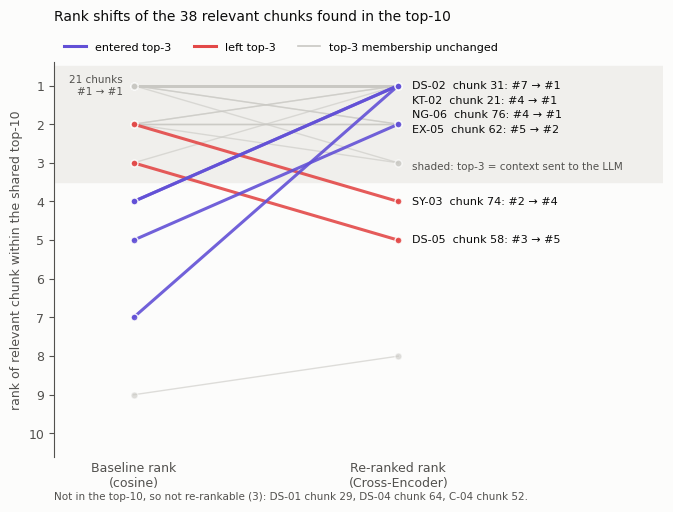

In [17]:
# ---- figure style, shared by all figures below ------------------------------------------------
# pipelines: baseline blue / re-ranked orange; entered / left the top-3: violet / red (colour-blind-safe pairs)
BASE, RR = "#2a78d6", "#eb6834"
IMPROVED, UNCHANGED, WORSENED = "#6250d6", "#c9c8c3", "#e34948"
INK, INK2, GRID, SURF, MUTED = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb", "#d3d2cd"
CASE_ORDER = ["KT-02", "EX-05", "DS-02", "NG-06", "SY-03", "DS-05"]     # the 4 rescues and 2 regressions
plt.rcParams.update({"font.size": 9, "axes.edgecolor": INK2, "axes.labelcolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "figure.facecolor": SURF,
                     "axes.facecolor": SURF, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titlecolor": INK, "axes.titlesize": 10, "axes.titlelocation": "left"})

def show_fig(fig, name):
    # display a figure in the notebook and, with WRITE_RESULTS, save it to results/figures/
    if WRITE_RESULTS:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(FIGURES_DIR / name, dpi=160)
    plt.show()

# ---- Figure: slope chart of each relevant chunk's rank, baseline (left) vs re-ranked (right) ----
def fig_rank_shifts(shifts):
    s = shifts[shifts.baseline_rank != "not in top-10"].copy()
    s["b"], s["r"] = s.baseline_rank.astype(int), s.reranked_rank.astype(int)
    fig, ax = plt.subplots(figsize=(6.8, 5.2))
    ax.axhspan(0.5, 3.5, color="#f0efec", zorder=0)                  # shaded band = top-3 sent to the LLM
    ax.text(1.05, 3.1, "shaded: top-3 = context sent to the LLM", ha="left", va="center", fontsize=7.5, color=INK2)
    seen, labels = {}, []
    for _, r in s.sort_values(["entered_top3", "left_top3"]).iterrows():
        color = IMPROVED if r.entered_top3 else WORSENED if r.left_top3 else UNCHANGED
        lw, z = (2.2, 3) if color != UNCHANGED else (1.0, 2)
        seen[(r.b, r.r)] = seen.get((r.b, r.r), 0) + 1
        ax.plot([0, 1], [r.b, r.r], color=color, linewidth=lw, zorder=z, alpha=0.9 if z == 3 else 0.6,
                marker="o", markersize=5, markeredgecolor=SURF, markeredgewidth=1)
        if color != UNCHANGED:                                         # label only the moves that matter
            labels.append((r.r, f"{r.query_id}  chunk {r.relevant_chunk}: #{r.b} → #{r.r}"))
    same = seen.get((1, 1), 0)                                         # identical paths overlap exactly
    if same:
        ax.text(-0.04, 1, f"{same} chunks\n#1 → #1", ha="right", va="center", fontsize=7.5, color=INK2)
    last = -9
    for y, text in sorted(labels):                                     # nudge labels apart when ranks coincide
        y = max(y, last + 0.38)
        ax.text(1.05, y, text, va="center", fontsize=8, color=INK)
        last = y
    ax.set_xlim(-0.3, 2.0)
    ax.set_ylim(10.6, 0.4)
    ax.set_yticks(range(1, 11))
    ax.set_xticks([0, 1], ["Baseline rank\n(cosine)", "Re-ranked rank\n(Cross-Encoder)"])
    ax.set_ylabel("rank of relevant chunk within the shared top-10")
    ax.spines["bottom"].set_visible(False)
    ax.tick_params(axis="x", length=0)
    ax.set_title(f"Rank shifts of the {len(s)} relevant chunks found in the top-10", pad=30)
    handles = [plt.Line2D([], [], color=IMPROVED, linewidth=2.2, label="entered top-3"),
               plt.Line2D([], [], color=WORSENED, linewidth=2.2, label="left top-3"),
               plt.Line2D([], [], color=UNCHANGED, linewidth=1.2, label="top-3 membership unchanged")]
    ax.legend(handles=handles, frameon=False, fontsize=8, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
    out = shifts[shifts.baseline_rank == "not in top-10"]
    note = ", ".join(f"{r.query_id} chunk {r.relevant_chunk}" for r in out.itertuples())
    ax.text(0, -0.11, f"Not in the top-10, so not re-rankable ({len(out)}): {note}.",
            transform=ax.transAxes, fontsize=7.5, color=INK2)
    fig.tight_layout()
    show_fig(fig, "rank_shifts_relevant_chunks.png")

fig_rank_shifts(shifts)

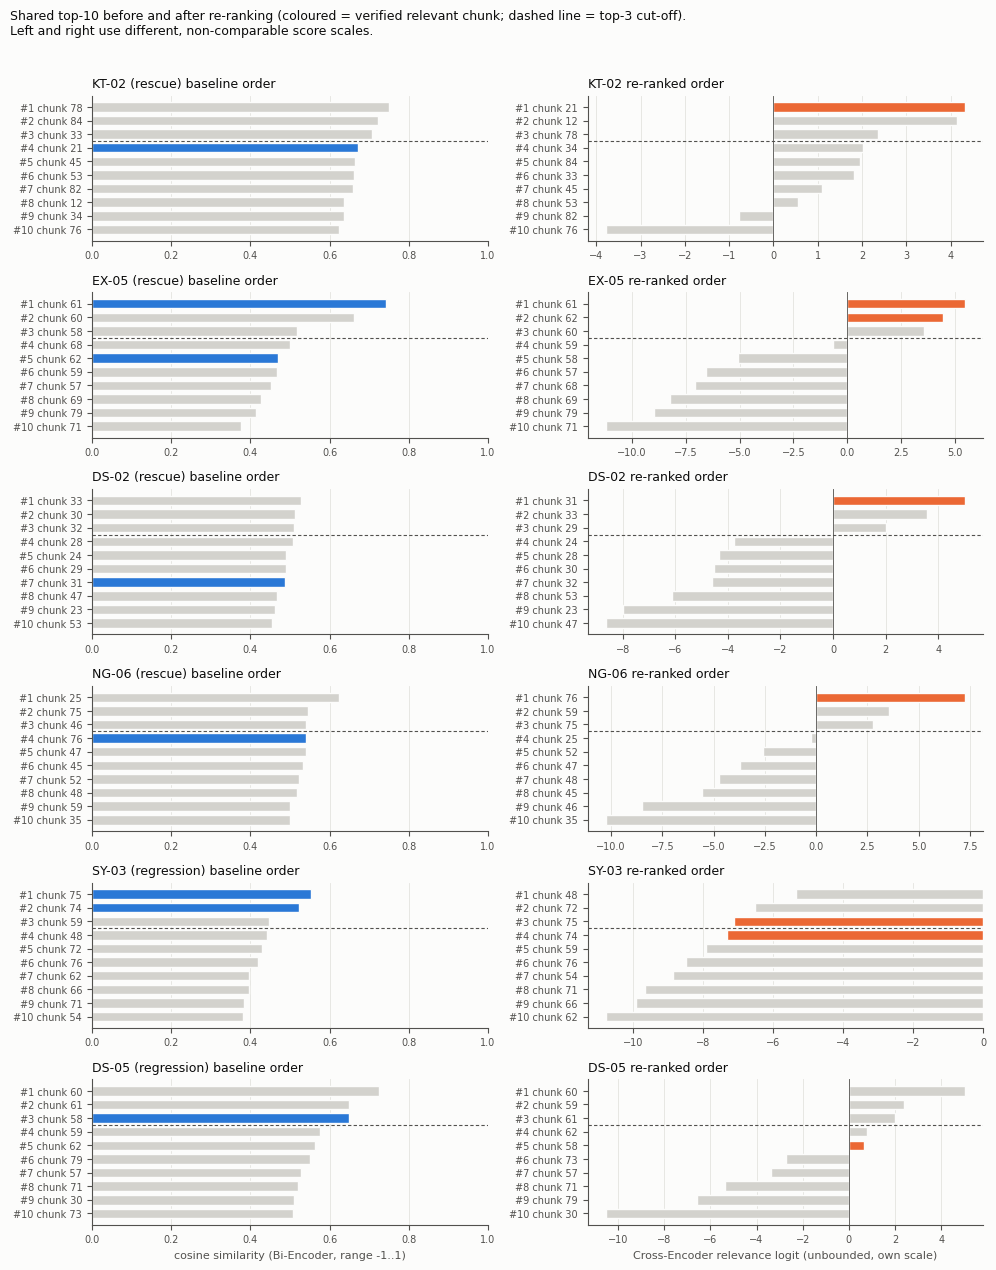

In [18]:
# Figure: the shared top-10 before and after re-ranking for the rescues and regressions;
# left = cosine similarity, right = Cross-Encoder logit (different scales, never compared directly)
def fig_top10(rows):
    by_q = {r["query_id"]: r for r in rows}
    fig, axes = plt.subplots(len(CASE_ORDER), 2, figsize=(10, 2.15 * len(CASE_ORDER)))
    for i, qid in enumerate(CASE_ORDER):
        c = pd.DataFrame(by_q[qid]["candidates"])
        tag = "rescue" if by_q[qid]["rescue"] else "regression"
        for j, (order, score, color, xlabel) in enumerate((
                ("baseline_rank", "cosine_score", BASE, "cosine similarity (Bi-Encoder, range -1..1)"),
                ("reranked_rank", "ce_score", RR, "Cross-Encoder relevance logit (unbounded, own scale)"))):
            ax = axes[i, j]
            cc = c.sort_values(order)
            y = np.arange(10)
            # relevant chunks are coloured, the rest grey
            ax.barh(y, cc[score], color=[color if rel else MUTED for rel in cc.relevant],
                    height=0.7, edgecolor=SURF, linewidth=1)
            ax.set_yticks(y, [f"#{r} chunk {cid}" for r, cid in zip(cc[order], cc.chunk_id)], fontsize=7)
            ax.invert_yaxis()
            ax.axhline(2.5, color=INK2, linewidth=0.8, linestyle=(0, (3, 2)))   # top-3 cut-off
            ax.axvline(0, color=INK2, linewidth=0.6)
            ax.grid(axis="x", color=GRID, linewidth=0.6)
            ax.set_axisbelow(True)
            ax.tick_params(axis="x", labelsize=7)
            if j == 0:
                ax.set_title(f"{qid} ({tag}) baseline order", fontsize=9)
                ax.set_xlim(0, 1)
            else:
                ax.set_title(f"{qid} re-ranked order", fontsize=9)
            if i == len(CASE_ORDER) - 1:
                ax.set_xlabel(xlabel, fontsize=8)
    fig.suptitle("Shared top-10 before and after re-ranking (coloured = verified relevant chunk; "
                 "dashed line = top-3 cut-off).\nLeft and right use different, non-comparable score scales.",
                 x=0.01, ha="left", fontsize=9, color=INK)
    fig.tight_layout(rect=(0, 0, 1, 0.97))
    show_fig(fig, "top10_before_after.png")

fig_top10(rows)

### Gemini answers for the rescues and regressions (5 runs per case)

For the six cases where re-ranking changed the evidence in the top-3 (4 rescues, 2 regressions), both pipelines generate an answer with `compare_pipelines`: one shared retrieval, the same prompt and settings, only the 3 context chunks differ.

Gemini's wording varies between identical calls even at `temperature=0`, so each case is answered **5 times by both pipelines** (60 calls). That separates differences caused by the context from run-to-run noise. All runs use one backend (Vertex AI, the same as the latency benchmark). Run 1 of each case is the "primary" answer pair that is reviewed in detail.

**Key-fact check.** `KEY_FACTS` lists, for every case, the facts a correct answer must state (taken from the reference answer), each as a few alternative regular expressions. It is an automatic cross-check of the manual verdicts below.

By default the 60 saved answers are loaded; `RERUN_STRESS_GENERATION = True` generates them again and saves them.

In [19]:
# The facts an answer must state to be judged correct, taken from the verified reference answers.
# Each fact is a list of alternative regexes (case-insensitive).
KEY_FACTS = {
    "KT-02": {"CGPA 8.5": [r"8\.5"],
              "measured at the end of the 3rd semester": [r"(third|3rd) semester"],
              "opt during the 4th semester": [r"(fourth|4th) semester"]},
    "EX-05": {"actual attendance above 40%": [r"40\s?%"],
              "notional attendance must reach 85%": [r"notional"]},
    "DS-02": {"HPF = 4 credits": [r"HPF[^.\n]{0,120}?\b(4|four)\b", r"\b(4|four)\b[^.\n]{0,60}HPF"]},
    "NG-06": {"successfully completed courses cannot be repeated": [r"successfully completed"],
              "2014-15 exception (CGPA below 5)": [r"2014"]},
    "SY-03": {"within three weeks": [r"(three|3) weeks"]},
    "DS-05": {"attendance code G": [r"[\"'“‘*]G[\"'”’*]", r"\bG\b\s*\(", r"\(G\)", r"code\s+(is\s+)?G\b"]},
}

CASES = CASE_ORDER                     # KT-02, EX-05, DS-02, NG-06 (rescues); SY-03, DS-05 (regressions)
N_RUNS = 5
REPEATS_JSON, ANSWERS_JSON = STRESS_DIR / "generation_repeats.json", STRESS_DIR / "generation_results.json"

def score(qid, answer):
    # which key facts of the reference answer does an answer state?
    found = {name: any(re.search(p, answer or "", re.I) for p in pats) for name, pats in KEY_FACTS[qid].items()}
    return {"facts_found": found, "n_found": sum(found.values()), "n_facts": len(found), "all_facts": all(found.values())}

def run_stress_generation():
    # N_RUNS answer pairs per case, round-robin (run 1 of every case, then run 2, ...); saved after every pair
    assert client is not None and "Vertex AI" in LLM_BACKEND, \
        "the reviewed answers must come from Vertex AI, the backend of the latency runs (see .env)"
    qs = {q["query_id"]: q for q in questions}
    data = {"runs": {}, "metadata": {"llm_model": GEMINI_MODEL, "llm_backend": LLM_BACKEND,
                                     "generation_settings": GENERATION_SETTINGS, "n_runs_per_case": N_RUNS,
                                     "cases": CASES, "key_facts": KEY_FACTS}}
    failures = 0
    for run in range(1, N_RUNS + 1):
        for qid in CASES:
            cmp = compare_pipelines(qs[qid]["question"])
            failures = 0 if (cmp["answer_1"] and cmp["answer_2"]) else failures + 1
            data["runs"][f"{qid}#{run}"] = {"query_id": qid, "run": run, **{k: cmp[k] for k in (
                "baseline_top3", "reranked_top3", "rank_changes", "answer_1", "answer_1_error", "answer_2",
                "answer_2_error", "prompt_1", "prompt_2", "llm_model")}, "llm_backend": LLM_BACKEND,
                "checks": cmp["checks"], "generated_utc": now_utc()}
            write_json(REPEATS_JSON, data)
            print(f"{qid}#{run}: answer_1 {'ok' if cmp['answer_1'] else 'ERROR'} | "
                  f"answer_2 {'ok' if cmp['answer_2'] else 'ERROR'}", flush=True)
            assert failures < 3, "3 consecutive failed cases; stopping"
            time.sleep(2)
    return data

def primary_answers(data):
    # run 1 of every case becomes the primary answer pair (generation_results.json)
    qs = {q["query_id"]: q for q in questions}
    cases = {}
    for qid in CASES:
        r, q = data["runs"][f"{qid}#1"], qs[qid]
        cases[qid] = {"query_id": qid, "category": q["category"], "question": q["question"],
                      "reference_answer": q["reference_answer"], "evidence": q["evidence"],
                      "relevant_chunk_ids": q["relevant_chunk_ids"],
                      **{k: r[k] for k in ("baseline_top3", "reranked_top3", "rank_changes", "answer_1",
                                           "answer_1_error", "answer_2", "answer_2_error", "prompt_1",
                                           "prompt_2", "llm_model", "llm_backend", "checks", "generated_utc")},
                      "generation_settings": data["metadata"]["generation_settings"],
                      "source": f"run 1 of {N_RUNS} in generation_repeats.json"}
    return cases

if RERUN_STRESS_GENERATION:
    repeats = run_stress_generation()
    gen_cases = primary_answers(repeats)
    write_json(ANSWERS_JSON, {"cases": gen_cases})
else:
    repeats = read_json(REPEATS_JSON)
    gen_cases = read_json(ANSWERS_JSON)["cases"]
    assert gen_cases == primary_answers(repeats), "generation_results.json is not run 1 of generation_repeats.json"

# every saved run must have used the same retrieval as the evaluation above, and passed the controls
by_q = {r["query_id"]: r for r in rows}
for run in repeats["runs"].values():
    q = by_q[run["query_id"]]
    assert run["baseline_top3"] == q["baseline"]["top3"] and run["reranked_top3"] == q["reranked"]["top3"]
    assert all(v for v in run["checks"].values() if isinstance(v, bool))
print(f"{len(repeats['runs'])} answer pairs ({len(CASES)} cases x {N_RUNS} runs) | backend:",
      sorted({r['llm_backend'] for r in repeats['runs'].values()}), "| same top-3 as the evaluation: True")

30 answer pairs (6 cases x 5 runs) | backend: ['Vertex AI (project=lma-ass1, location=global)'] | same top-3 as the evaluation: True


### Manual review of the answers

The verdicts below were written by hand after reading each answer and comparing it with the reference answer and with the chunks that were actually in its prompt. Scale: `correct`, `partially_correct` (a condition is missing), `insufficient_context` (the model said the context does not answer the question; no fabrication) and `incorrect`.

- `MANUAL_REVIEW` reviews run 1 of each case in detail: missing clauses, unsupported claims, citation problems.
- `REPEAT_REVIEW` gives the verdict of every one of the 5 runs.

The cell then merges the review with the retrieval metrics into the stress-test report and checks that every verdict agrees with the automatic key-fact check (a run judged `correct` must contain all key facts, and vice versa). If the answers are regenerated, the review has to be re-read against the new answers; the key-fact check shows where it no longer agrees.

In [20]:
# ---- manual review (written by hand after reading the answers) ----------------------------------
# verdict scale: correct | partially_correct | insufficient_context (model declined;
# no fabrication) | incorrect
# The detailed review is of run 1 (the primary answers in generation_results.json, Vertex AI).
MANUAL_REVIEW = {
    "KT-02": {
        "retrieval_change": "strict rescue: relevant chunk 21 (R.1.12) moved from baseline #4 to #1; the baseline top-3 [78, 84, 33] contained no relevant chunk, chunk 84 (R.30.1, the 'maintain CGPA 8.5 for award' distractor) was #2",
        "answer_1_verdict": "insufficient_context",
        "answer_1_notes": "Answered the distractor (average CGPA 8.5 to be AWARDED Honours, R.30.1) and stated that the context does not say when a student can opt, nor give a CGPA for opting. No fabrication, but the question is not answered.",
        "answer_2_verdict": "correct",
        "answer_2_notes": "8.5 and above at the end of the 3rd semester, opting during the 4th semester, first-attempt clearance and U/W ineligibility, all from chunk 21. Run 1 does not mention O.5 ('at the end of the fourth semester', chunk 12), which was also in the context; runs 2-3 do.",
        "missing_clauses": {"answer_1": ["CGPA 8.5 at end of 3rd semester", "opt during 4th semester", "cleared all courses in first attempt"], "answer_2": []},
        "unsupported_claims": {"answer_1": [], "answer_2": []},
        "citation_issues": {"answer_1": [], "answer_2": []},
        "answer_change": "improved",
    },
    "EX-05": {
        "retrieval_change": "partial rescue: chunk 61 stayed #1, chunk 62 (notional-attendance formula and the >= 85% condition) moved from #5 to #2; evidence coverage of the top-3 rose from 3/5 to 5/5 quotes",
        "answer_1_verdict": "partially_correct",
        "answer_1_notes": "Correct 'yes' with the medical-certificate and >40% conditions, but omits the second, decisive condition that notional attendance must reach 85%; as written it implies >40% attendance alone suffices.",
        "answer_2_verdict": "correct",
        "answer_2_notes": "Gives both conditions (>40% actual attendance, then notional attendance >= 85%, with the formula) and the casual-absenteeism / minor-illness exclusion.",
        "missing_clauses": {"answer_1": ["notional attendance must be >= 85% (formula excluding illness days)"], "answer_2": []},
        "unsupported_claims": {"answer_1": [], "answer_2": []},
        "citation_issues": {"answer_1": [], "answer_2": []},
        "answer_change": "improved",
    },
    "DS-02": {
        "retrieval_change": "strict rescue: chunk 31 (2013-onwards table, contains the HPF row) moved from #7 to #1; the baseline top-3 [33, 30, 32] held only the text paragraph and the two table tails without the HPF row",
        "answer_1_verdict": "insufficient_context",
        "answer_1_notes": "Correctly reports that the given excerpts do not mention HPF; quotes the 7-13 Pass/Fail total and the PPF (0-6) / PIL (1) rows accurately. No fabrication.",
        "answer_2_verdict": "correct",
        "answer_2_notes": "4 non-CGPA HPF credits from the 2013-onwards table (chunk 31). Chunk 29 (2011-2012 table, HPF = 2) was also in the context and was not confused with it.",
        "missing_clauses": {"answer_1": ["HPF = 4 credits"], "answer_2": []},
        "unsupported_claims": {"answer_1": [], "answer_2": []},
        "citation_issues": {"answer_1": [], "answer_2": []},
        "answer_change": "improved",
    },
    "NG-06": {
        "retrieval_change": "strict rescue: chunk 76 (R.25.1 tail, 'A course successfully completed cannot be repeated' + the 2014-15 exception) moved from #4 to #1; the baseline top-3 [25, 75, 46] held the 'No withdrawal ... will be allowed' registration clause (distractor), the U/W repetition rules and the n-4 registration rule",
        "answer_1_verdict": "insufficient_context",
        "answer_1_notes": "Lists only the U/W repetition rules from chunk 75 and concludes that 'there are no courses explicitly stated as non-repeatable'. True for its context and no fabrication, but a reader would take it to mean there is no restriction, which is the opposite of the rule.",
        "answer_2_verdict": "correct",
        "answer_2_notes": "Successfully completed courses cannot be repeated, plus the 2014-15 exception for students with all courses taken and CGPA below 5.",
        "missing_clauses": {"answer_1": ["a successfully completed course cannot be repeated", "2014-15 exception for CGPA below 5"], "answer_2": []},
        "unsupported_claims": {"answer_1": [], "answer_2": []},
        "citation_issues": {"answer_1": [], "answer_2": ["prohibition cited as [Chunk 76, p. 22]; the clause is on PDF page 23 (chunk 76 spans pp. 22-23)"]},
        "answer_change": "improved",
    },
    "SY-03": {
        "retrieval_change": "worsened: chunk 74 (the 'within three weeks' clause) fell from #2 to #4, out of the top-3; chunk 75 (re-examination procedure) went from #1 to #3; chunks 48 (dropping courses) and 72 (grade definitions) were promoted to #1 and #2",
        "answer_1_verdict": "correct",
        "answer_1_notes": "Three weeks from the commencement of the next semester after results (R.24.1), plus access to answer papers from chunk 75.",
        "answer_2_verdict": "insufficient_context",
        "answer_2_notes": "States that no time limit is given in the context and describes the answer-paper access and re-examination procedure from chunk 75; true for its context, but the answer to the question is lost. No fabrication.",
        "missing_clauses": {"answer_1": [], "answer_2": ["within three weeks from the commencement of the following semester"]},
        "unsupported_claims": {"answer_1": [], "answer_2": []},
        "citation_issues": {"answer_1": [], "answer_2": []},
        "answer_change": "worsened",
    },
    "DS-05": {
        "retrieval_change": "worsened: chunk 58 (attendance-code table) fell from #3 to #5, out of the top-3; replaced by chunk 59 (R.14.2 shortfall rule)",
        "answer_1_verdict": "correct",
        "answer_1_notes": "'G' for 90% attendance, from the table in chunk 58.",
        "answer_2_verdict": "insufficient_context",
        "answer_2_notes": "Reports only the <85% case (W grade with code P) and says codes for students at or above 85% are not described; true for its context. No fabrication.",
        "missing_clauses": {"answer_1": [], "answer_2": ["85-94% -> G (Good)"]},
        "unsupported_claims": {"answer_1": [], "answer_2": []},
        "citation_issues": {"answer_1": [], "answer_2": []},
        "answer_change": "worsened",
    },
}

# Verdicts for all 5 runs per case (generation_repeats.json), assigned after reading
# every answer; the automatic key-fact check (KEY_FACTS above) is reported
# next to them as a cross-check.
REPEAT_REVIEW = {
    "KT-02": {"answer_1": ["insufficient_context"] * 5, "answer_2": ["correct"] * 5,
              "notes": "Answer 1 always answers the award rule (R.30.1) and says the opt-in rule is missing. Answer 2 always gives 8.5 / end of 3rd semester / during 4th semester; runs 2-3 also quote O.5 ('end of the fourth semester'), runs 1, 4 and 5 do not."},
    "EX-05": {"answer_1": ["partially_correct"] * 5, "answer_2": ["correct"] * 5,
              "notes": "Answer 1 never mentions the notional-attendance condition; Answer 2 always does (runs 1 and 5 also give the formulas)."},
    "DS-02": {"answer_1": ["insufficient_context"] * 5, "answer_2": ["correct"] * 5,
              "notes": "Answer 1 always says HPF is not in the context; Answer 2 is always '4 HPF credits [Chunk 31]'."},
    "NG-06": {"answer_1": ["insufficient_context"] * 5, "answer_2": ["correct"] * 5,
              "notes": "Answer 1 lists the U/W repetition rules every time; runs 1 and 3 add 'no courses explicitly stated as non-repeatable', run 5 says the evidence is insufficient. Answer 2 always gives the prohibition and the 2014-15 exception (run 4 cites pp. 22-23 correctly; the other runs cite p. 22 only)."},
    "SY-03": {"answer_1": ["correct"] * 5, "answer_2": ["insufficient_context"] * 5,
              "notes": "Answer 1 always gives 'within three weeks'; Answer 2 always says no time limit is given."},
    "DS-05": {"answer_1": ["correct"] * 5, "answer_2": ["insufficient_context"] * 5,
              "notes": "Answer 1 always gives 'G'; Answer 2 always says the code for 90% is not specified."},
}

LIMITATIONS = [
    "33 questions, one PDF, one retrieval run per pipeline: the counts are indicative, not statistically significant. NG-06 was added after a retrieval-only screen of 24 negation phrasings (results/stress_test/negation_screen.json); 1 of the 3 screen hits survived checking, so the negation rescue was searched for, not found by chance.",
    "Answers were generated 5 times per pipeline for the six reviewed cases (60 Gemini calls, all on Vertex AI, the same backend as the latency benchmark). The verdict was the same in all 5 runs for every case; only the wording changed. Five runs show the pattern is stable, but cannot rule out rarer outcomes.",
    "Earlier single-run answers from the Gemini Developer API (a different backend) showed the same verdict pattern; they are not used in the results.",
    "Answer verdicts are a single reviewer's judgement against the verified reference answers, not an independent annotation. The automatic key-fact check (regexes stored in generation_repeats.json) agreed with every verdict, but it only tests whether key facts are mentioned.",
    "Relevance labels are the chunks containing the evidence quotes; a chunk that answers the question with different wording would not count as relevant.",
    "C-04 (control) failed for both pipelines: the 12-credit rule is the last sentence of chunk 52, which is mostly about contact courses, and chunk 52 is not in the top-10. Re-ranking cannot recover chunks outside the candidate pool (a chunking issue, not a ranking issue).",
    "DS-01 (free-elective credits, 2011-2012): the relevant table tail (chunk 30) stays at #8-#9; the table half without its batch caption is hard for both models. Recorded as 'improved (rank only)', which is not a meaningful gain.",
]

FURTHER_EVALUATION = [
    "Grow the question set (for example 2-3 paraphrases per question) so that improved / worsened counts per category become meaningful.",
    "Have a second person review the answers independently and report agreement.",
    "Measure the effect of the candidate-pool size (top-20 or top-30 before re-ranking) on misses like C-04 and DS-01, together with the extra Cross-Encoder latency.",
    "Repeat table headers / batch captions in every table chunk, or chunk tables row-wise, and re-measure DS-01, DS-02 and DS-05.",
]

def build_stress_report():
    # merge retrieval metrics, the primary answers and the manual review into one report
    cases = []
    for qid, review in MANUAL_REVIEW.items():
        a, r = gen_cases[qid], by_q[qid]
        cases.append({
            "query_id": qid, "category": a["category"], "question": a["question"],
            "reference_answer": a["reference_answer"], "evidence": a["evidence"],
            "relevant_chunk_ids": a["relevant_chunk_ids"], "relevant_rank_shifts": r["relevant_rank_shifts"],
            "baseline_top3": a["baseline_top3"], "reranked_top3": a["reranked_top3"],
            "metrics": {"baseline": r["baseline"], "reranked": r["reranked"]},
            "retrieval_outcome": r["outcome"], "rescue": r["rescue"], "strict_rescue": r["strict_rescue"],
            "answer_1": a["answer_1"], "answer_1_error": a["answer_1_error"],
            "answer_2": a["answer_2"], "answer_2_error": a["answer_2_error"],
            "llm_model": a["llm_model"], "llm_backend": a["llm_backend"],
            "controls_passed": all(v for v in a["checks"].values() if isinstance(v, bool)),
            "manual_review": review,
        })
    report = {
        "metadata": {**retrieval_out["metadata"], "manual_review_note": "answer verdicts are a manual assessment "
                     "against the verified reference answers and the exact prompt context"},
        "retrieval_overall": retrieval_out["overall"], "retrieval_by_category": retrieval_out["by_category"],
        "genuine_rescues_verified": [c["query_id"] for c in cases if c["rescue"]],
        "answer_level_summary": {
            **{k: [c["query_id"] for c in cases if c["manual_review"]["answer_change"] == k]
               for k in ("improved", "worsened", "unchanged")},
            "fabrications_found": 0},
        "generation_cases": cases, "limitations": LIMITATIONS, "further_evaluation": FURTHER_EVALUATION,
    }
    # repeated runs: manual verdicts next to the automatic key-fact check
    repeat_rows = []
    for qid in CASES:
        runs = [repeats["runs"][f"{qid}#{i}"] for i in range(1, N_RUNS + 1)]
        rv = REPEAT_REVIEW[qid]
        row = {"query_id": qid, "n_runs": len(runs), "llm_backend": sorted({r["llm_backend"] for r in runs}),
               "controls_passed_all_runs": all(all(v for v in r["checks"].values() if isinstance(v, bool)) for r in runs),
               "notes": rv["notes"]}
        for a in ("answer_1", "answer_2"):
            facts = [score(qid, r[a]) for r in runs]
            row[f"{a}_verdicts"] = {v: rv[a].count(v) for v in sorted(set(rv[a]))}
            row[f"{a}_all_key_facts"] = sum(f["all_facts"] for f in facts)
            # cross-check: a run judged 'correct' must contain all key facts, and vice versa
            row[f"{a}_fact_check_agrees"] = all((v == "correct") == f["all_facts"] for v, f in zip(rv[a], facts))
        repeat_rows.append(row)
    report["repeat_runs"] = {"description": f"{N_RUNS} generations per pipeline per case on one backend; verdicts "
                             "are manual, the key-fact check is automatic (patterns in generation_repeats.json)",
                             "key_facts": repeats["metadata"]["key_facts"], "cases": repeat_rows}
    return report

stress_report = build_stress_report()
review = {c["query_id"]: c["manual_review"] for c in stress_report["generation_cases"]}
saved_report = read_json(STRESS_DIR / "stress_test_report.json")
same = all(stress_report[k] == saved_report[k] for k in stress_report if k != "metadata")
print("identical to saved stress_test_report.json (apart from the run timestamp):", same)
print("genuine rescues:", stress_report["genuine_rescues_verified"], "| answer level:", stress_report["answer_level_summary"])
print("key-fact check agrees with every manual verdict:",
      all(r["answer_1_fact_check_agrees"] and r["answer_2_fact_check_agrees"] for r in stress_report["repeat_runs"]["cases"]))

if WRITE_RESULTS:
    write_json(STRESS_DIR / "stress_test_report.json", stress_report)
    with open(STRESS_DIR / "generation_repeats_summary.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["query_id", "n_runs", "answer_1_verdicts", "answer_2_verdicts", "answer_1_all_key_facts",
                    "answer_2_all_key_facts", "fact_check_agrees", "backend", "notes"])
        for r in stress_report["repeat_runs"]["cases"]:
            w.writerow([r["query_id"], r["n_runs"], r["answer_1_verdicts"], r["answer_2_verdicts"],
                        f"{r['answer_1_all_key_facts']}/{r['n_runs']}", f"{r['answer_2_all_key_facts']}/{r['n_runs']}",
                        r["answer_1_fact_check_agrees"] and r["answer_2_fact_check_agrees"],
                        "; ".join(r["llm_backend"]), r["notes"]])
    with open(STRESS_DIR / "generation_cases.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f)
        w.writerow(["query_id", "category", "question", "relevant_rank_shifts", "baseline_top3", "reranked_top3",
                    "base_evidence_cov@3", "rr_evidence_cov@3", "retrieval_outcome", "strict_rescue",
                    "answer_1_verdict", "answer_2_verdict", "answer_change", "answer_1_missing", "answer_2_missing",
                    "citation_issues", "reference_answer", "answer_1", "answer_2"])
        for c in stress_report["generation_cases"]:
            m = c["manual_review"]
            w.writerow([c["query_id"], c["category"], c["question"],
                        "; ".join(f"{s['chunk_id']}:{s['baseline_rank']}->{s['reranked_rank']}" for s in c["relevant_rank_shifts"]),
                        c["baseline_top3"], c["reranked_top3"], c["metrics"]["baseline"]["evidence_cov@3"],
                        c["metrics"]["reranked"]["evidence_cov@3"], c["retrieval_outcome"], c["strict_rescue"],
                        m["answer_1_verdict"], m["answer_2_verdict"], m["answer_change"],
                        " | ".join(m["missing_clauses"]["answer_1"]), " | ".join(m["missing_clauses"]["answer_2"]),
                        " | ".join(m["citation_issues"]["answer_1"] + m["citation_issues"]["answer_2"]),
                        c["reference_answer"], c["answer_1"], c["answer_2"]])

identical to saved stress_test_report.json (apart from the run timestamp): True
genuine rescues: ['KT-02', 'EX-05', 'DS-02', 'NG-06'] | answer level: {'improved': ['KT-02', 'EX-05', 'DS-02', 'NG-06'], 'worsened': ['SY-03', 'DS-05'], 'unchanged': [], 'fabrications_found': 0}
key-fact check agrees with every manual verdict: True


In [21]:
# Answer 1 vs Answer 2 for each case (run 1), with the manual verdicts.
qtext = {q["query_id"]: q for q in questions}
for qid in CASES:
    r, a, rv = ev.set_index("query_id").loc[qid], gen_cases[qid], review[qid]
    # one Markdown block per case: question, reference, rank shifts, both answers and their verdicts
    display(Markdown(
        f"### {qid} ({qtext[qid]['category']}): {qtext[qid]['question']}\n\n"
        f"**Reference:** {qtext[qid]['reference_answer']}\n\n"
        f"**Rank shifts:** " + ", ".join(f"chunk {c} #{b}→#{x}" for c, b, x in r.shifts) +
        f" | top-3 {r.base_top3} → {r.rr_top3} | evidence coverage {r['base_evcov@3']:.2f} → {r['rr_evcov@3']:.2f}\n\n"
        f"**Answer 1**, verdict *{rv['answer_1_verdict']}*:\n\n> " + (a["answer_1"] or "-").replace("\n", "\n> ") +
        f"\n\n**Answer 2**, verdict *{rv['answer_2_verdict']}*:\n\n> " + (a["answer_2"] or "-").replace("\n", "\n> ") +
        f"\n\n**Answer change: {rv['answer_change']}**. Missing in A1: {rv['missing_clauses']['answer_1'] or 'nothing'}; "
        f"missing in A2: {rv['missing_clauses']['answer_2'] or 'nothing'}"))

### KT-02 (keyword_trap): What CGPA does a student need in order to opt for the B.Tech (Honours) programme, and when can they opt?

**Reference:** A CGPA of 8.5 and above at the end of the third semester; the option is exercised during the fourth semester. The student must also have cleared all prescribed courses in the first attempt; students with a 'U' or 'W' grade in any course are not eligible.

**Rank shifts:** chunk 21 #4→#1 | top-3 [78, 84, 33] → [21, 12, 78] | evidence coverage 0.00 → 1.00

**Answer 1**, verdict *insufficient_context*:

> To be awarded the B.Tech (Honours) degree, students must maintain an average CGPA of 8.5 [Chunk 84, p. 25]. If this CGPA is not maintained, they will be awarded only a B.Tech Degree [Chunk 84, p. 25].
> 
> The provided context does not specify when a student can opt for the B.Tech (Honours) programme, nor does it state a CGPA requirement for *opting* into the programme itself, only for the *award* of the degree.

**Answer 2**, verdict *correct*:

> A student needs a CGPA of 8.5 and above at the end of their third semester to opt for the B.Tech (Honours) programme [Chunk 21, p. 8]. They can opt for this programme during the fourth semester [Chunk 21, p. 8].
> 
> Additionally, to be eligible, students must have cleared all prescribed courses in the curriculum in the first attempt and must not have obtained a "U" or "W" grade in any course [Chunk 21, p. 8].

**Answer change: improved**. Missing in A1: ['CGPA 8.5 at end of 3rd semester', 'opt during 4th semester', 'cleared all courses in first attempt']; missing in A2: nothing

### EX-05 (exception): Can attendance below 85% be condoned for a student who was hospitalised?

**Reference:** Yes, for prolonged illness and/or hospitalisation with a medical certificate: the student must have more than 40% actual attendance, and the notional attendance (classes attended x 100 / (classes held in the semester minus classes held during the prolonged illness/hospitalisation)) must be at least 85%. Casual absenteeism and minor illnesses are not condoned.

**Rank shifts:** chunk 61 #1→#1, chunk 62 #5→#2 | top-3 [61, 60, 58] → [61, 62, 60] | evidence coverage 0.60 → 1.00

**Answer 1**, verdict *partially_correct*:

> Yes, attendance below 85% can be condoned for a student who was hospitalized, provided they meet a specific condition. A student must have more than 40% attendance (calculated as per normal cases) to be eligible for condonation in cases of prolonged illness and/or hospitalization with a medical certificate [Chunk 61, p. 19].
> 
> This is in contrast to cases of minor illnesses and casual absenteeism, for which condonation of attendance is not permissible [Chunk 60, p. 19; Chunk 61, p. 19].

**Answer 2**, verdict *correct*:

> Yes, attendance below 85% can be condoned for a student who was hospitalized, provided they meet specific conditions.
> 
> For cases of prolonged illness and/or hospitalization with a medical certificate, a student must have more than 40% attendance, calculated based on the actual number of classes attended out of the total classes held till the date of compilation, to be eligible for condonation [Chunk 61, p. 19].
> 
> If eligible, a "Notional % of attendance" is calculated as:
> (Actual no. of classes attended x 100) / ((Total no. of classes held in the semester) - (No. of classes held during the days of prolonged illness and or hospitalization))
> This notional percentage must be ≥ 85% for condonation to be granted [Chunk 62, p. 19].
> 
> It is important to note that condonation is not permissible for cases of casual absenteeism or minor illnesses if attendance is below 85% [Chunk 60, p. 19; Chunk 61, p. 19].

**Answer change: improved**. Missing in A1: ['notional attendance must be >= 85% (formula excluding illness days)']; missing in A2: nothing

### DS-02 (document_specific): From the 2013 batch onwards, how many Humanities Pass/Fail (HPF) credits are required?

**Reference:** 4 non-CGPA credits under the Humanities Pass/Fail option (HPF) in the table for the 2013 batch onwards (the 2010 and 2011-2012 tables specify 2).

**Rank shifts:** chunk 31 #7→#1 | top-3 [33, 30, 32] → [31, 33, 29] | evidence coverage 0.00 → 1.00

**Answer 1**, verdict *insufficient_context*:

> The provided context does not explicitly state the number of Humanities Pass/Fail (HPF) credits required for students from the 2013 batch onwards.
> 
> The context indicates that for the 2013 batch onwards, 7-13 credits of coursework done under the Pass/Fail option are not counted towards CGPA calculation [Chunk 33, p. 12]. Chunk 32, which applies to this batch, lists "Pass/ Fail Electives" (PPF) as 0-6 credits and "Industrial Lecture (Pass/Fail)" (PIL) as 1 credit under the Pass/Fail category [Chunk 32, p. 12]. However, "Humanities Pass/Fail" (HPF) is not mentioned.

**Answer 2**, verdict *correct*:

> For the 2013 batch onwards, 4 Humanities Pass/Fail (HPF) credits are required, which are non-CGPA credits [Chunk 31, p. 12].

**Answer change: improved**. Missing in A1: ['HPF = 4 credits']; missing in A2: nothing

### NG-06 (negation_constraint): Which courses is a student not allowed to repeat?

**Reference:** A course that has been successfully completed cannot be repeated. Exception: from academic year 2014-15, students who have taken all core and elective courses but still fail to reach the minimum CGPA of 5 (and so are not eligible for the degree) may repeat core or elective courses to earn the minimum CGPA.

**Rank shifts:** chunk 76 #4→#1 | top-3 [25, 75, 46] → [76, 59, 75] | evidence coverage 0.00 → 1.00

**Answer 1**, verdict *insufficient_context*:

> The provided context does not state which courses a student is *not allowed* to repeat. It only specifies conditions under which courses *must* or *may* be repeated:
> *   A student who earns a U or W grade in a core course has to repeat it compulsorily when the course is offered next [Chunk 75, p. 22].
> *   A student securing a U or W grade in an elective course may repeat it if they desire to get a successful grade [Chunk 75, p. 22].
> 
> Therefore, based on the provided information, there are no courses explicitly stated as non-repeatable.

**Answer 2**, verdict *correct*:

> A student is generally not allowed to repeat a course that has been successfully completed [Chunk 76, p. 22].
> 
> However, for students from the academic year 2014-15 onwards, if they have completed all core and elective courses but fail to achieve a minimum CGPA of 5 and are thus ineligible for a degree, they are permitted to repeat core or elective courses to meet the minimum CGPA requirement [Chunk 76, p. 22].

**Answer change: improved**. Missing in A1: ['a successfully completed course cannot be repeated', '2014-15 exception for CGPA below 5']; missing in A2: nothing

### SY-03 (synonym_mismatch): How much time does a student have to dispute a grade they think is unfair?

**Reference:** The student can contact the teacher concerned within three weeks from the commencement of the semester immediately following the announcement of results; if the teacher finds the case genuine, he/she may re-examine and forward a revised grade to the Dean of Academic Courses through the Chairman of the Class Committee.

**Rank shifts:** chunk 74 #2→#4, chunk 75 #1→#3 | top-3 [75, 74, 59] → [48, 72, 75] | evidence coverage 1.00 → 0.50

**Answer 1**, verdict *correct*:

> A student has three weeks from the commencement of the semester immediately following the announcement of the results to contact the teacher concerned if they feel aggrieved about a grade [Chunk 74, p. 22]. The student can access their answer paper(s) in the end semester examination, which may be shown to them by the teachers [Chunk 75, p. 22]. If the teacher finds the case genuine, they may re-examine it and forward a revised grade, if any, to the Dean of Academic Courses through the Chairman of the Class Committee with justification [Chunk 75, p. 22].

**Answer 2**, verdict *insufficient_context*:

> The provided context does not specify a time limit for a student to dispute a grade they think is unfair.
> 
> The ordinances state that a student shall have access to their end-semester examination answer paper(s) which may be shown by the teachers concerned. If the teacher deems the case genuine, they may re-examine it and forward a revised grade with justification [Chunk 75, p. 22]. However, no deadline for initiating this process is mentioned.

**Answer change: worsened**. Missing in A1: nothing; missing in A2: ['within three weeks from the commencement of the following semester']

### DS-05 (document_specific): What attendance code does a student with 90% attendance in a course receive?

**Reference:** 'G' (Good), which covers attendance of 85 to 94%.

**Rank shifts:** chunk 58 #3→#5 | top-3 [60, 61, 58] → [60, 59, 61] | evidence coverage 1.00 → 0.00

**Answer 1**, verdict *correct*:

> A student with 90% attendance in a course receives an attendance code of "G" [Chunk 58, p. 18].

**Answer 2**, verdict *insufficient_context*:

> The provided context does not explicitly state what attendance code a student with 90% attendance in a course receives. The regulations only specify that if a student has less than 85% attendance, they should be assigned a "W" grade in that subject along with "P" as the attendance code [Chunk 60, p. 18]. For attendance not ≥ 85%, a "W" grade shall be awarded [Chunk 61, p. 19]. The context does not describe attendance codes for students meeting or exceeding the 85% minimum requirement.

**Answer change: worsened**. Missing in A1: nothing; missing in A2: ['85-94% -> G (Good)']

**Is the difference stable across runs?** The table compares the manual verdicts of all 5 runs with the automatic key-fact check for every case.

In [22]:
# 5 runs per pipeline per case: automatic key-fact check next to the manual verdicts.
display(pd.DataFrame([{
    "case": r["query_id"], "runs": r["n_runs"], "backend": r["llm_backend"][0].split(" (")[0],
    "A1 all key facts": f"{r['answer_1_all_key_facts']}/{r['n_runs']}",
    "A2 all key facts": f"{r['answer_2_all_key_facts']}/{r['n_runs']}",
    "A1 verdicts (manual)": r["answer_1_verdicts"], "A2 verdicts (manual)": r["answer_2_verdicts"],
    "agree": r["answer_1_fact_check_agrees"] and r["answer_2_fact_check_agrees"]}
    for r in stress_report["repeat_runs"]["cases"]]))
print("key facts checked:", {q: list(f) for q, f in KEY_FACTS.items()})

,case,runs,backend,A1 all key facts,A2 all key facts,A1 verdicts (manual),A2 verdicts (manual),agree
0,KT-02,5,Vertex AI,0/5,5/5,{'insufficient_context': 5},{'correct': 5},True
1,EX-05,5,Vertex AI,0/5,5/5,{'partially_correct': 5},{'correct': 5},True
2,DS-02,5,Vertex AI,0/5,5/5,{'insufficient_context': 5},{'correct': 5},True
3,NG-06,5,Vertex AI,0/5,5/5,{'insufficient_context': 5},{'correct': 5},True
4,SY-03,5,Vertex AI,5/5,0/5,{'correct': 5},{'insufficient_context': 5},True
5,DS-05,5,Vertex AI,5/5,0/5,{'correct': 5},{'insufficient_context': 5},True


key facts checked: {'KT-02': ['CGPA 8.5', 'measured at the end of the 3rd semester', 'opt during the 4th semester'], 'EX-05': ['actual attendance above 40%', 'notional attendance must reach 85%'], 'DS-02': ['HPF = 4 credits'], 'NG-06': ['successfully completed courses cannot be repeated', '2014-15 exception (CGPA below 5)'], 'SY-03': ['within three weeks'], 'DS-05': ['attendance code G']}


## 8. Latency profiling and scaling

**Timing rules**

- Models are loaded and the index is built before timing, and a few warm-up queries run first, so initialisation is never timed.
- Every duration comes from `time.perf_counter()` around exactly one step.
- Per repetition the vector search runs **once** and both pipelines share its candidates, so the only extra work in Pipeline 2 is Cross-Encoder scoring plus sorting.
- Repetitions are interleaved (round-robin over the questions) to spread CPU-frequency and background-load drift over all questions.

**Three measurements**

1. Retrieval side, no LLM: all 33 questions × 5 repeats.
2. End-to-end with Gemini: 3 questions (a rescue, a partial rescue, a control) × 5 paired runs; every API attempt is logged, and failed attempts are never counted as measurements.
3. Scaling: Cross-Encoder time vs number of (query, chunk) pairs up to the whole corpus, and FAISS search time vs index size (synthetic vectors above 85, since search cost depends only on the number and dimension of the vectors).

By default the saved raw timings are loaded (a quick live retrieval timing is still run as a check); the `RERUN_LATENCY_*` flags measure everything again.

In [23]:
REPEATS = 5
RAW_RETRIEVAL, RAW_GENERATION = LAT_DIR / "raw_retrieval_timings.csv", LAT_DIR / "raw_generation_timings.csv"
RAW_GEN_ATTEMPTS, SCALING_JSON = LAT_DIR / "raw_generation_attempts.csv", LAT_DIR / "scaling_measurements.json"

def timed_query(query):
    # One timed pass: shared retrieval, Pipeline 1 selection, Pipeline 2 re-ranking. Each step is one
    # contiguous perf_counter segment, so the totals are measured, not summed guesses.
    t0 = time.perf_counter()
    q = embed([query])                                                         # query embedding
    t1 = time.perf_counter()
    scores, rows_ = index.search(q, TOP_K_RETRIEVE)                            # FAISS top-10
    t2 = time.perf_counter()
    cands = [chunks_by_id[id_map[int(r)]] for r in rows_[0]]                   # row -> chunk lookup
    t3 = time.perf_counter()
    p1_top3 = cands[:K]                                                        # Pipeline 1 selection
    t4 = time.perf_counter()
    pairs = [(query, c["text"]) for c in cands]
    ce = cross_encoder.predict(pairs, show_progress_bar=False)                 # CE scoring, 10 pairs
    t5 = time.perf_counter()
    order = sorted(range(len(cands)), key=lambda i: -float(ce[i]))             # sort + top-3
    p2_top3 = [cands[i] for i in order[:K]]
    t6 = time.perf_counter()
    ms = lambda a, b: (b - a) * 1000
    return {"query_embed_ms": ms(t0, t1), "faiss_search_ms": ms(t1, t2), "id_lookup_ms": ms(t2, t3),
            "p1_select_ms": ms(t3, t4), "ce_score_ms": ms(t4, t5), "sort_select_ms": ms(t5, t6),
            "shared_retrieval_ms": ms(t0, t3),
            "p1_retrieval_ms": ms(t0, t4),                     # embed + search + lookup + top-3
            "p2_retrieval_ms": ms(t0, t3) + ms(t4, t6),         # same shared part + CE + sort
            "rerank_overhead_ms": ms(t4, t6),
            "p1_top3": [c["chunk_id"] for c in p1_top3], "p2_top3": [c["chunk_id"] for c in p2_top3],
            "n_pairs": len(pairs)}

def warm_up():
    for _ in range(3):
        timed_query("warm-up query about attendance and grades")   # exclude one-off initialisation

def run_retrieval_benchmark(repeats):
    # all questions x repeats, round-robin
    warm_up()
    out = []
    for rep in range(1, repeats + 1):
        for q in questions:
            r = timed_query(q["question"])
            out.append({"repeat": rep, "query_id": q["query_id"], "category": q["category"],
                        **{k: (round(v, 4) if isinstance(v, float) else ";".join(map(str, v)) if isinstance(v, list) else v)
                           for k, v in r.items()}})
    return pd.DataFrame(out)

stats_df = lambda df: df.agg(["count", "mean", "median", "std"]).T.round(3)
TIME_COLS = ["query_embed_ms", "faiss_search_ms", "ce_score_ms", "sort_select_ms", "p1_retrieval_ms", "p2_retrieval_ms"]
if RERUN_LATENCY_BENCHMARK:
    lat_ret = run_retrieval_benchmark(REPEATS)
    LAT_DIR.mkdir(parents=True, exist_ok=True)
    lat_ret.to_csv(RAW_RETRIEVAL, index=False)
    print(f"measured and saved {len(lat_ret)} timed queries ({len(questions)} questions x {REPEATS} repeats)")
else:
    live = run_retrieval_benchmark(1)                    # quick live check, 1 repeat
    print(f"live check, {len(live)} queries (ms):")
    display(stats_df(live[TIME_COLS]))
    lat_ret = pd.read_csv(RAW_RETRIEVAL)
    print(f"saved benchmark: {len(lat_ret)} runs = {lat_ret.query_id.nunique()} questions x {REPEATS} repeats (ms):")
display(stats_df(lat_ret[TIME_COLS]))
print(f"additional re-ranking time (CE + sort): {lat_ret.rerank_overhead_ms.mean():.1f} ms (mean) | "
      f"slowdown P2/P1: {lat_ret.p2_retrieval_ms.mean() / lat_ret.p1_retrieval_ms.mean():.1f}x (mean)")

live check, 33 queries (ms):


,count,mean,median,std
query_embed_ms,33.0,8.671,8.599,2.028
faiss_search_ms,33.0,0.063,0.068,0.011
ce_score_ms,33.0,223.892,210.931,38.821
sort_select_ms,33.0,0.017,0.016,0.006
p1_retrieval_ms,33.0,8.746,8.680,2.034
p2_retrieval_ms,33.0,232.654,218.564,39.594


saved benchmark: 165 runs = 33 questions x 5 repeats (ms):


,count,mean,median,std
query_embed_ms,165.0,10.217,9.959,1.880
faiss_search_ms,165.0,0.068,0.069,0.020
ce_score_ms,165.0,265.037,253.340,50.413
sort_select_ms,165.0,0.018,0.017,0.006
p1_retrieval_ms,165.0,10.298,10.039,1.886
p2_retrieval_ms,165.0,275.352,263.994,50.690


additional re-ranking time (CE + sort): 265.1 ms (mean) | slowdown P2/P1: 26.7x (mean)


In [24]:
GEN_QUERIES = ["KT-02", "EX-05", "C-01"]   # a rescue, a partial rescue, a control
GEN_TIMEOUT_MS = 60_000                    # per-request HTTP timeout
GEN_MAX_ATTEMPTS = 3                       # 1 try + 2 retries per answer
GEN_RETRY_WAITS_S = (2, 5)                 # short, bounded back-off
GEN_MAX_CONSECUTIVE_FAILURES = 3           # stop the run instead of waiting on a dead quota
# Gemini 2.5 Flash list prices (USD per 1M tokens, text, standard tier); thinking tokens are billed as
# output. Check the current pricing page before relying on the estimate.
PRICE_PER_M = {"input": 0.30, "output": 2.50}

def timed_generate(query, ctx, attempt_log, label):
    # One Gemini answer with bounded retries; returns its latency + token counts, or None.
    # Every attempt (ok or failed) goes to attempt_log; the latency is the successful request only.
    from google.genai import types
    prompt = build_prompt(query, ctx)
    cfg = types.GenerateContentConfig(**GENERATION_SETTINGS, http_options=types.HttpOptions(timeout=GEN_TIMEOUT_MS))
    for attempt in range(1, GEN_MAX_ATTEMPTS + 1):
        t0 = time.perf_counter()
        try:
            resp = client.models.generate_content(model=GEMINI_MODEL, contents=prompt, config=cfg)
            ms = (time.perf_counter() - t0) * 1000
            if not (resp.text or "").strip():
                raise RuntimeError(f"empty response (finish reason: {resp.candidates[0].finish_reason})")
            u = resp.usage_metadata
            attempt_log.append({**label, "attempt": attempt, "status": "ok", "ms": round(ms, 1), "error": ""})
            return {"ms": ms, "attempt": attempt, "input_tokens": u.prompt_token_count or 0,
                    "output_tokens": u.candidates_token_count or 0, "thinking_tokens": u.thoughts_token_count or 0}
        except Exception as exc:
            ms = (time.perf_counter() - t0) * 1000
            code = getattr(exc, "code", None)
            attempt_log.append({**label, "attempt": attempt, "status": "failed", "ms": round(ms, 1),
                                "error": f"{type(exc).__name__} {code or ''}: {str(exc)[:160]}"})
            if (isinstance(code, int) and 400 <= code < 500 and code != 429) or attempt == GEN_MAX_ATTEMPTS:
                return None
            time.sleep(GEN_RETRY_WAITS_S[attempt - 1])
    return None

def run_generation_benchmark():
    # GEN_QUERIES x REPEATS paired runs: Answer 1 + Answer 2 on one shared retrieval. A pair counts as a
    # measurement only if BOTH answers succeeded; results are saved after every pair.
    assert client is not None, f"no Gemini client ({LLM_BACKEND})"
    qs = {q["query_id"]: q for q in questions}
    warm_up()
    out, attempts, consecutive_failures = [], [], 0
    for rep in range(1, REPEATS + 1):
        for qid in GEN_QUERIES:
            query = qs[qid]["question"]
            r = timed_query(query)                                 # shared retrieval + re-ranking
            ctx = {1: [chunks_by_id[i] for i in r["p1_top3"]], 2: [chunks_by_id[i] for i in r["p2_top3"]]}
            gen = {}
            for n in (1, 2):                                        # identical prompt template + settings
                label = {"query_id": qid, "repeat": rep, "answer": n, "backend": LLM_BACKEND}
                gen[n] = timed_generate(query, ctx[n], attempts, label)
                consecutive_failures = 0 if gen[n] else consecutive_failures + 1
                write_rows(RAW_GEN_ATTEMPTS, attempts)
                assert consecutive_failures < GEN_MAX_CONSECUTIVE_FAILURES, attempts[-1]["error"]
            if gen[1] and gen[2]:
                row = {"query_id": qid, "repeat": rep, "backend": LLM_BACKEND, "model": GEMINI_MODEL,
                       "settings": json.dumps(GENERATION_SETTINGS, sort_keys=True),
                       "p1_top3": ";".join(map(str, r["p1_top3"])), "p2_top3": ";".join(map(str, r["p2_top3"]))}
                row.update({k: round(v, 4) for k, v in r.items() if isinstance(v, float)})
                for n in (1, 2):
                    row.update({f"gen{n}_ms": round(gen[n]["ms"], 1), f"gen{n}_attempt": gen[n]["attempt"],
                                f"gen{n}_input_tokens": gen[n]["input_tokens"],
                                f"gen{n}_output_tokens": gen[n]["output_tokens"],
                                f"gen{n}_thinking_tokens": gen[n]["thinking_tokens"]})
                row["p1_end_to_end_ms"] = round(r["p1_retrieval_ms"] + gen[1]["ms"], 1)
                row["p2_end_to_end_ms"] = round(r["p2_retrieval_ms"] + gen[2]["ms"], 1)
                out.append(row)
                write_rows(RAW_GENERATION, out)
                print(f"{qid} rep {rep}: gen1 {gen[1]['ms']:.0f} ms, gen2 {gen[2]['ms']:.0f} ms", flush=True)
            else:
                print(f"{qid} rep {rep}: NOT completed (see attempts log)", flush=True)

if RERUN_LATENCY_GENERATION:
    run_generation_benchmark()
lat_gen = pd.read_csv(RAW_GENERATION)           # completed pairs
lat_att = pd.read_csv(RAW_GEN_ATTEMPTS)         # every API attempt incl. failures
print(f"{len(lat_gen)} completed paired runs | backend: {lat_gen.backend.unique()[0]} | "
      f"identical settings: {lat_gen.settings.nunique() == 1}")
print(f"API attempts: {len(lat_att)} ({(lat_att.status == 'ok').sum()} ok, {(lat_att.status != 'ok').sum()} failed; "
      "failures excluded)")
display(stats_df(lat_gen[["gen1_ms", "gen2_ms", "p1_end_to_end_ms", "p2_end_to_end_ms"]]))
print(f"end-to-end P2/P1: {lat_gen.p2_end_to_end_ms.median() / lat_gen.p1_end_to_end_ms.median():.2f}x (median), "
      f"{lat_gen.p2_end_to_end_ms.mean() / lat_gen.p1_end_to_end_ms.mean():.2f}x (mean)")

15 completed paired runs | backend: Vertex AI (project=lma-ass1, location=global) | identical settings: True
API attempts: 37 (31 ok, 6 failed; failures excluded)


,count,mean,median,std
gen1_ms,15.0,4465.213,4473.5,2217.392
gen2_ms,15.0,5745.780,3256.3,6600.380
p1_end_to_end_ms,15.0,4495.860,4510.4,2214.414
p2_end_to_end_ms,15.0,6034.640,3504.7,6591.336


end-to-end P2/P1: 0.78x (median), 1.34x (mean)


In [25]:
def run_scaling():
    # (a) Cross-Encoder cost vs number of (query, chunk) pairs; n = 85 is "run it on the whole corpus"
    # (b) one-time (offline) cost of embedding the whole corpus with the Bi-Encoder
    # (c) FAISS exact search vs index size; sizes above the real corpus use SYNTHETIC random unit
    #     vectors (same dimension and index type): search cost depends on N and d, not on the contents
    warm_up()
    probe = [q["question"] for q in questions[::7]][:5]      # 5 spread-out questions
    res = {"probe_queries": probe}
    ce = []
    for n in (1, 5, 10, 20, 40, len(chunks)):
        for rep in range(REPEATS):
            for query in probe:
                full = baseline_retrieve(query, k=len(chunks))
                pairs = [(query, c["text"]) for c in full[:n]]
                t0 = time.perf_counter()
                cross_encoder.predict(pairs, show_progress_bar=False)
                ce.append({"n_pairs": n, "repeat": rep + 1, "ms": (time.perf_counter() - t0) * 1000})
    res["cross_encoder_vs_pairs"] = ce

    texts = [c["text"] for c in chunks]
    corpus = []
    for rep in range(3):
        t0 = time.perf_counter()
        embed(texts)
        corpus.append((time.perf_counter() - t0) * 1000)
    res["bi_encoder_corpus_embedding_ms"] = {"n_chunks": len(texts), "runs_ms": corpus}

    rng = np.random.default_rng(SEED)
    qv = embed(probe)
    faiss_rows = []
    for n in (len(chunks), 1_000, 10_000, 100_000, 500_000):
        if n == len(chunks):
            idx, synthetic = index, False                     # the real index
        else:
            x = rng.standard_normal((n, index.d), dtype=np.float32)
            x /= np.linalg.norm(x, axis=1, keepdims=True)     # random unit vectors
            idx, synthetic = faiss.IndexFlatIP(index.d), True
            idx.add(x)
        idx.search(qv[:1], TOP_K_RETRIEVE)                    # warm-up
        for rep in range(REPEATS):
            for i in range(len(probe)):
                t0 = time.perf_counter()
                idx.search(qv[i:i + 1], TOP_K_RETRIEVE)
                faiss_rows.append({"n_vectors": n, "synthetic": synthetic, "repeat": rep + 1,
                                   "ms": (time.perf_counter() - t0) * 1000})
        if synthetic:
            del idx, x
    res["faiss_vs_index_size"] = faiss_rows
    return res

if RERUN_LATENCY_BENCHMARK:
    scaling = run_scaling()
    write_json(SCALING_JSON, scaling)
else:
    scaling = read_json(SCALING_JSON)
print(f"scaling runs: {len(scaling['cross_encoder_vs_pairs'])} Cross-Encoder timings, "
      f"{len(scaling['faiss_vs_index_size'])} FAISS timings ({'measured now' if RERUN_LATENCY_BENCHMARK else 'saved'})")

scaling runs: 150 Cross-Encoder timings, 125 FAISS timings (saved)


In [26]:
def lat_stats(values):
    v = [float(x) for x in pd.Series(values).dropna()]
    return {"n": len(v), "mean": statistics.fmean(v), "median": statistics.median(v),
            "std": statistics.stdev(v) if len(v) > 1 else 0.0, "min": min(v), "max": max(v),
            "p95": float(np.percentile(v, 95))}

def hardware():
    # the machine the timings come from
    cpu = "unknown"
    try:
        cpu = next(l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name"))
    except (OSError, StopIteration):
        pass
    try:
        mem_gb = round(int(open("/proc/meminfo").readline().split()[1]) / 1024**2, 1)
    except (OSError, ValueError):
        mem_gb = None
    import sentence_transformers
    return {"cpu": cpu, "logical_cpus": os.cpu_count(), "torch_threads": torch.get_num_threads(), "ram_gb": mem_gb,
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none (CPU only)",
            "os": platform.platform(), "python": platform.python_version(), "torch": torch.__version__,
            "faiss": faiss.__version__, "sentence_transformers": sentence_transformers.__version__}

def latency_summary():
    # the latency table + slowdown ratios, token cost and scaling fit, all computed from the raw timings
    comp = [("query_embed_ms", "Query embedding (Bi-Encoder, 1 query)"),
            ("faiss_search_ms", "FAISS top-10 search (85 vectors)"),
            ("id_lookup_ms", "FAISS id -> chunk lookup"),
            ("p1_select_ms", "Pipeline 1: take top-3"),
            ("ce_score_ms", "Cross-Encoder scoring (10 pairs)"),
            ("sort_select_ms", "Pipeline 2: sort by CE score + top-3"),
            ("shared_retrieval_ms", "Shared retrieval (embed + search + lookup)"),
            ("p1_retrieval_ms", "Pipeline 1 retrieval side (total)"),
            ("p2_retrieval_ms", "Pipeline 2 retrieval side (total)"),
            ("rerank_overhead_ms", "Additional re-ranking time (CE + sort)")]
    n_ret_q = lat_ret.query_id.nunique()
    table = [{"scope": f"retrieval ({n_ret_q} questions x {REPEATS} repeats)", "component": label, "key": key,
              **lat_stats(lat_ret[key])} for key, label in comp]
    n_q = lat_gen.query_id.nunique()
    for key, label in (("gen1_ms", "Gemini generation, Answer 1 (P1 context)"),
                       ("gen2_ms", "Gemini generation, Answer 2 (P2 context)"),
                       ("p1_end_to_end_ms", "Pipeline 1 end-to-end"), ("p2_end_to_end_ms", "Pipeline 2 end-to-end")):
        table.append({"scope": f"with generation ({n_q} questions x {REPEATS} repeats)", "component": label,
                      "key": key, **lat_stats(lat_gen[key])})
    by = {t["key"]: t for t in table}
    failed = lat_att[lat_att.status != "ok"]
    tot_in = int(lat_gen[["gen1_input_tokens", "gen2_input_tokens"]].values.sum())
    tot_out = int(lat_gen[["gen1_output_tokens", "gen2_output_tokens", "gen1_thinking_tokens",
                           "gen2_thinking_tokens"]].values.sum())
    cost = tot_in / 1e6 * PRICE_PER_M["input"] + tot_out / 1e6 * PRICE_PER_M["output"]
    # Cross-Encoder: linear fit of median time vs number of pairs -> extrapolation to big collections
    ce_by_n = pd.DataFrame(scaling["cross_encoder_vs_pairs"]).groupby("n_pairs").ms.apply(list)
    ce_stats = {n: lat_stats(v) for n, v in ce_by_n.items()}
    ns = np.array(sorted(ce_stats))
    slope, intercept = np.polyfit(ns, np.array([ce_stats[n]["median"] for n in ns]), 1)
    faiss_by_n = pd.DataFrame(scaling["faiss_vs_index_size"]).groupby(["n_vectors", "synthetic"]).ms.apply(list)
    emb = scaling["bi_encoder_corpus_embedding_ms"]
    return {
        "created_utc": now_utc(),
        "hardware": hardware() if RERUN_LATENCY_BENCHMARK else read_json(LAT_DIR / "latency_summary.json")["hardware"],
        "units": "milliseconds (ms)", "repeats": REPEATS, "llm_model": GEMINI_MODEL,
        "retrieval_questions": n_ret_q, "table": table,
        "rerank_overhead_mean_ms": by["rerank_overhead_ms"]["mean"],
        "retrieval_slowdown_mean_ratio": by["p2_retrieval_ms"]["mean"] / by["p1_retrieval_ms"]["mean"],
        "retrieval_slowdown_median_ratio": by["p2_retrieval_ms"]["median"] / by["p1_retrieval_ms"]["median"],
        "end_to_end_slowdown_mean_ratio": by["p2_end_to_end_ms"]["mean"] / by["p1_end_to_end_ms"]["mean"],
        "end_to_end_slowdown_median_ratio": by["p2_end_to_end_ms"]["median"] / by["p1_end_to_end_ms"]["median"],
        "rerank_share_of_p2_end_to_end": by["rerank_overhead_ms"]["mean"] / by["p2_end_to_end_ms"]["mean"],
        "generation_attempts": {
            "completed_paired_runs": len(lat_gen), "planned_paired_runs": len(GEN_QUERIES) * REPEATS,
            "api_attempts_total": len(lat_att), "api_attempts_ok": len(lat_att) - len(failed),
            "api_attempts_failed": len(failed),
            "failed_attempts": failed[["query_id", "repeat", "answer", "attempt", "error"]].to_dict("records"),
            "backend": sorted(lat_gen.backend.unique()),
            "settings_identical_across_pipelines": lat_gen.settings.nunique() == 1,
            "note": "failed attempts are never counted as measurements; latency = successful request only"},
        "tokens": {f"answer{n}_{kind}": lat_stats(lat_gen[f"gen{n}_{kind}_tokens"])
                   for n in (1, 2) for kind in ("input", "output", "thinking")},
        "cost_estimate_usd": {"successful_calls": 2 * len(lat_gen), "input_tokens": tot_in,
                              "output_plus_thinking_tokens": tot_out, "prices_per_1M_usd": PRICE_PER_M,
                              "estimated_cost_usd": round(cost, 5), "per_answer_usd": round(cost / (2 * len(lat_gen)), 6),
                              "note": "estimate from recorded token counts x list prices; excludes failed attempts "
                                      "(normally not billed) and the single test requests"},
        "scaling": {
            "cross_encoder_vs_pairs_ms": {str(n): s for n, s in ce_stats.items()},
            "cross_encoder_linear_fit_ms": {"per_pair": slope, "intercept": intercept,
                                            "fit_on": "median ms vs n_pairs, measured n = 1..85"},
            "cross_encoder_full_corpus_extrapolation_ms": {str(n): slope * n + intercept
                                                           for n in (1_000, 10_000, 100_000, 1_000_000)},
            "faiss_vs_index_size_ms": {f"{n}{' (synthetic)' if syn else ''}": lat_stats(v)
                                       for (n, syn), v in faiss_by_n.items()},
            "bi_encoder_corpus_embedding": {"n_chunks": emb["n_chunks"], **lat_stats(emb["runs_ms"]),
                                            "per_chunk_ms": statistics.median(emb["runs_ms"]) / emb["n_chunks"]}},
    }

lat_summary = latency_summary()
saved_ls = read_json(LAT_DIR / "latency_summary.json")
print("latency table identical to saved latency_summary.json:",
      all(abs(a[k] - b[k]) < 1e-6 for a, b in zip(lat_summary["table"], saved_ls["table"])
          for k in ("n", "mean", "median", "std", "p95")))

# the latency table as Markdown (also written to results/latency/)
md_lines = ["| Component | n | mean (ms) | median (ms) | std (ms) | p95 (ms) |", "|---|---|---|---|---|---|"]
scope = None
for t in lat_summary["table"]:
    if t["scope"] != scope:
        scope = t["scope"]
        md_lines.append(f"| **{scope}** | | | | | |")
    md_lines.append(f"| {t['component']} | {t['n']} | {t['mean']:.3f} | {t['median']:.3f} | {t['std']:.3f} | {t['p95']:.3f} |")
display(Markdown("\n".join(md_lines)))
s = lat_summary["scaling"]
print(f"re-ranking adds {lat_summary['rerank_overhead_mean_ms']:.1f} ms/query (mean); retrieval side "
      f"{lat_summary['retrieval_slowdown_mean_ratio']:.1f}x slower | re-ranking = "
      f"{lat_summary['rerank_share_of_p2_end_to_end']:.1%} of P2 end-to-end")
print("Cross-Encoder ms vs pairs (median):", {n: round(v["median"], 1) for n, v in s["cross_encoder_vs_pairs_ms"].items()})
print(f"linear fit {s['cross_encoder_linear_fit_ms']['per_pair']:.1f} ms/pair -> extrapolated Cross-Encoder over every chunk "
      "(NOT measured):", {n: f"{v / 1000:,.0f} s" for n, v in s["cross_encoder_full_corpus_extrapolation_ms"].items()})
print("FAISS top-10 ms vs index size (median):", {n: round(v["median"], 3) for n, v in s["faiss_vs_index_size_ms"].items()})
print(f"cost: ~${lat_summary['cost_estimate_usd']['estimated_cost_usd']:.3f} for "
      f"{lat_summary['cost_estimate_usd']['successful_calls']} answers (assumed list prices)")

if WRITE_RESULTS:
    write_json(LAT_DIR / "latency_summary.json", lat_summary)
    with open(LAT_DIR / "latency_table.csv", "w", newline="") as f:
        w = csv.writer(f)
        w.writerow(["scope", "component", "n", "mean_ms", "median_ms", "std_ms", "min_ms", "p95_ms", "max_ms"])
        for t in lat_summary["table"]:
            w.writerow([t["scope"], t["component"], t["n"]] + [f"{t[k]:.3f}" for k in ("mean", "median", "std", "min", "p95", "max")])
    (LAT_DIR / "latency_table.md").write_text("\n".join(md_lines) + "\n")

latency table identical to saved latency_summary.json: True


| Component | n | mean (ms) | median (ms) | std (ms) | p95 (ms) |
|---|---|---|---|---|---|
| **retrieval (33 questions x 5 repeats)** | | | | | |
| Query embedding (Bi-Encoder, 1 query) | 165 | 10.217 | 9.959 | 1.880 | 13.859 |
| FAISS top-10 search (85 vectors) | 165 | 0.068 | 0.069 | 0.020 | 0.096 |
| FAISS id -> chunk lookup | 165 | 0.012 | 0.011 | 0.003 | 0.015 |
| Pipeline 1: take top-3 | 165 | 0.001 | 0.001 | 0.000 | 0.001 |
| Cross-Encoder scoring (10 pairs) | 165 | 265.037 | 253.340 | 50.413 | 341.887 |
| Pipeline 2: sort by CE score + top-3 | 165 | 0.018 | 0.017 | 0.006 | 0.030 |
| Shared retrieval (embed + search + lookup) | 165 | 10.297 | 10.038 | 1.886 | 13.935 |
| Pipeline 1 retrieval side (total) | 165 | 10.298 | 10.039 | 1.886 | 13.936 |
| Pipeline 2 retrieval side (total) | 165 | 275.352 | 263.994 | 50.690 | 355.117 |
| Additional re-ranking time (CE + sort) | 165 | 265.055 | 253.357 | 50.413 | 341.904 |
| **with generation (3 questions x 5 repeats)** | | | | | |
| Gemini generation, Answer 1 (P1 context) | 15 | 4465.213 | 4473.500 | 2217.392 | 8387.500 |
| Gemini generation, Answer 2 (P2 context) | 15 | 5745.780 | 3256.300 | 6600.380 | 17132.490 |
| Pipeline 1 end-to-end | 15 | 4495.860 | 4510.400 | 2214.414 | 8401.250 |
| Pipeline 2 end-to-end | 15 | 6034.640 | 3504.700 | 6591.336 | 17369.190 |

re-ranking adds 265.1 ms/query (mean); retrieval side 26.7x slower | re-ranking = 4.4% of P2 end-to-end
Cross-Encoder ms vs pairs (median): {'1': 30.8, '5': 101.7, '10': 232.0, '20': 544.6, '40': 1197.0, '85': 2676.8}
linear fit 32.0 ms/pair -> extrapolated Cross-Encoder over every chunk (NOT measured): {'1000': '32 s', '10000': '320 s', '100000': '3,197 s', '1000000': '31,966 s'}
FAISS top-10 ms vs index size (median): {'85': 0.037, '1000 (synthetic)': 0.053, '10000 (synthetic)': 0.571, '100000 (synthetic)': 9.802, '500000 (synthetic)': 51.865}
cost: ~$0.046 for 30 answers (assumed list prices)


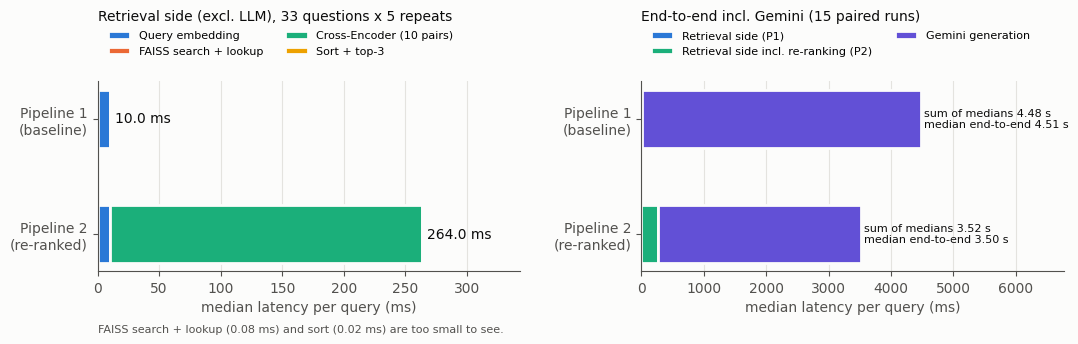

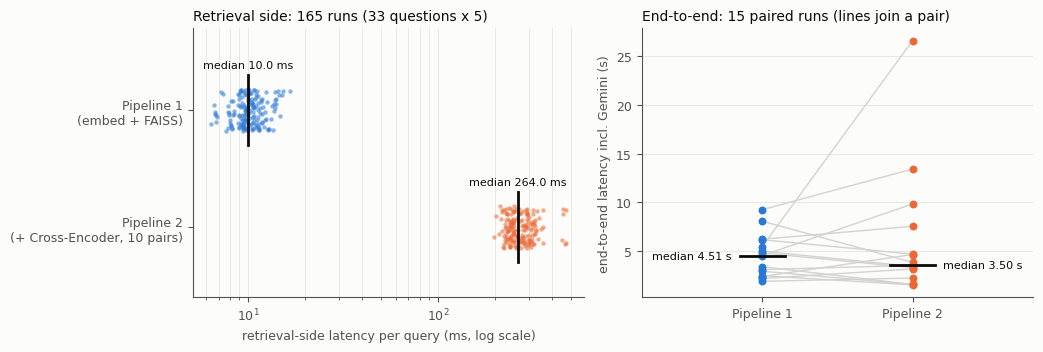

In [27]:
# ---- Figure: where the time goes (retrieval-side breakdown) and end-to-end with Gemini ---------
C = {"embed": "#2a78d6", "search": "#eb6834", "ce": "#1baf7a", "sort": "#eda100", "gen": "#6250d6"}
by = {t["key"]: t for t in lat_summary["table"]}
plt.rcParams["font.size"] = 10                    # the latency charts use a slightly larger font
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
ax = axes[0]
segs = [("query_embed_ms", "Query embedding", C["embed"]), ("faiss_search_ms", "FAISS search + lookup", C["search"]),
        ("ce_score_ms", "Cross-Encoder (10 pairs)", C["ce"]), ("sort_select_ms", "Sort + top-3", C["sort"])]
bars = {"Pipeline 1\n(baseline)": ["query_embed_ms", "faiss_search_ms"],
        "Pipeline 2\n(re-ranked)": ["query_embed_ms", "faiss_search_ms", "ce_score_ms", "sort_select_ms"]}
for y, (name, keys) in enumerate(bars.items()):
    left = 0
    for key, label, color in segs:                         # stacked median of each step
        if key not in keys:
            continue
        w = by[key]["median"] + (by["id_lookup_ms"]["median"] if key == "faiss_search_ms" else 0)
        ax.barh(y, w, left=left, color=color, height=0.5, edgecolor=SURF, linewidth=2, label=label if y == 1 else None)
        left += w
    total = by["p1_retrieval_ms" if y == 0 else "p2_retrieval_ms"]["median"]
    ax.text(left + 4, y, f"{total:.1f} ms", va="center", color=INK)
ax.set_yticks(range(len(bars)), list(bars))
ax.invert_yaxis()
ax.set_xlabel("median latency per query (ms)")
ax.set_title(f"Retrieval side (excl. LLM), {lat_summary['retrieval_questions']} questions x {REPEATS} repeats", pad=44)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlim(0, by["p2_retrieval_ms"]["median"] * 1.3)
ax.legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.08), ncol=2)
ax.text(0, -0.32, f"FAISS search + lookup ({by['faiss_search_ms']['median'] + by['id_lookup_ms']['median']:.2f} ms) "
        f"and sort ({by['sort_select_ms']['median']:.2f} ms) are too small to see.", transform=ax.transAxes, fontsize=8, color=INK2)
ax = axes[1]
for y, (ret_key, gen_key) in enumerate((("p1_retrieval_ms", "gen1_ms"), ("p2_retrieval_ms", "gen2_ms"))):
    r, g = by[ret_key]["median"], by[gen_key]["median"]
    ax.barh(y, r, color=C["ce"] if y else C["embed"], height=0.5, edgecolor=SURF, linewidth=2,
            label=("Retrieval side (P1)" if y == 0 else "Retrieval side incl. re-ranking (P2)"))
    ax.barh(y, g, left=r, color=C["gen"], height=0.5, edgecolor=SURF, linewidth=2, label="Gemini generation" if y == 1 else None)
    e2e = by["p1_end_to_end_ms" if y == 0 else "p2_end_to_end_ms"]["median"]
    ax.text(r + g + 40, y, f"sum of medians {(r + g) / 1000:.2f} s\nmedian end-to-end {e2e / 1000:.2f} s",
            va="center", color=INK, fontsize=8)
ax.set_yticks([0, 1], ["Pipeline 1\n(baseline)", "Pipeline 2\n(re-ranked)"])
ax.invert_yaxis()
ax.set_xlabel("median latency per query (ms)")
ax.set_title(f"End-to-end incl. Gemini ({by['gen1_ms']['n']} paired runs)", pad=44)
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_xlim(0, max(by["p1_end_to_end_ms"]["median"], by["p2_end_to_end_ms"]["median"]) * 1.5)
ax.legend(frameon=False, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.08), ncol=2)
fig.tight_layout()
show_fig(fig, "latency_breakdown.png")
plt.rcParams["font.size"] = 9

# ---- Figure: every timed run, retrieval side (left, log scale) and end-to-end pairs (right) ----
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10.5, 3.6))
rng = np.random.default_rng(0)
for k, (col, color) in enumerate((("p1_retrieval_ms", BASE), ("p2_retrieval_ms", RR))):
    v = lat_ret[col].values
    a1.scatter(v, k + rng.uniform(-0.18, 0.18, len(v)), s=10, color=color, alpha=0.55, linewidths=0)
    a1.plot([np.median(v)] * 2, [k - 0.3, k + 0.3], color=INK, linewidth=2)
    a1.text(np.median(v), k - 0.36, f"median {np.median(v):.1f} ms", ha="center", fontsize=8, color=INK)
a1.set_xscale("log")
a1.set_yticks([0, 1], ["Pipeline 1\n(embed + FAISS)", "Pipeline 2\n(+ Cross-Encoder, 10 pairs)"])
a1.set_ylim(1.6, -0.7)
a1.set_xlabel("retrieval-side latency per query (ms, log scale)")
a1.set_title(f"Retrieval side: {len(lat_ret)} runs ({lat_ret.query_id.nunique()} questions x 5)")
a1.grid(axis="x", color=GRID, linewidth=0.6, which="both")
a1.set_axisbelow(True)
for _, r in lat_gen.iterrows():                             # one grey line joins each pair
    a2.plot([0, 1], [r.p1_end_to_end_ms / 1000, r.p2_end_to_end_ms / 1000], color=MUTED, linewidth=1, zorder=1)
a2.scatter(np.zeros(len(lat_gen)), lat_gen.p1_end_to_end_ms / 1000, color=BASE, s=22, zorder=2, label="Pipeline 1")
a2.scatter(np.ones(len(lat_gen)), lat_gen.p2_end_to_end_ms / 1000, color=RR, s=22, zorder=2, label="Pipeline 2")
for k, col in enumerate(("p1_end_to_end_ms", "p2_end_to_end_ms")):
    m = lat_gen[col].median() / 1000
    a2.plot([k - 0.15, k + 0.15], [m, m], color=INK, linewidth=2, zorder=3)
    a2.text(k + (0.2 if k else -0.2), m, f"median {m:.2f} s", va="center", ha="left" if k else "right", fontsize=8, color=INK)
a2.set_xticks([0, 1], ["Pipeline 1", "Pipeline 2"])
a2.set_xlim(-0.8, 1.8)
a2.set_ylabel("end-to-end latency incl. Gemini (s)")
a2.set_title(f"End-to-end: {len(lat_gen)} paired runs (lines join a pair)")
a2.grid(axis="y", color=GRID, linewidth=0.6)
a2.set_axisbelow(True)
fig.tight_layout()
show_fig(fig, "latency_comparison.png")

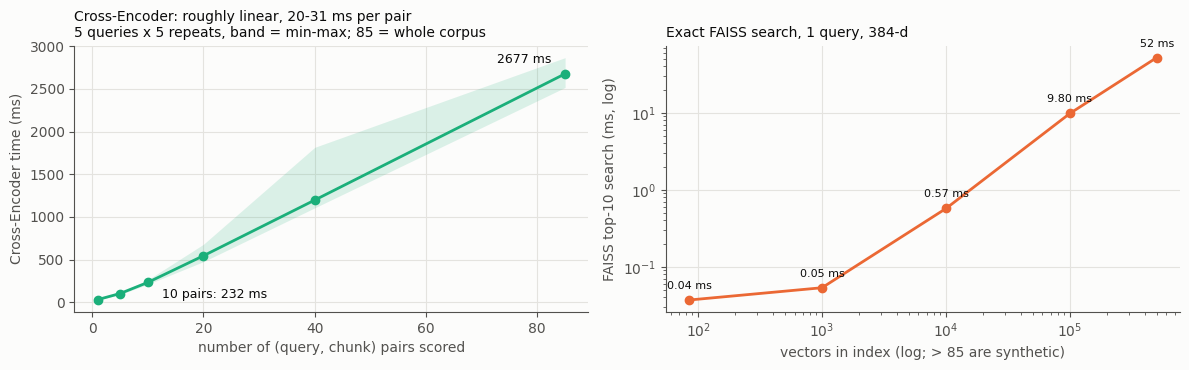

In [28]:
# ---- Figure: the scaling question -----------------------------------------------------------
# Left: Cross-Encoder time grows linearly with the number of pairs scored (85 = the whole corpus).
# Right: exact FAISS search stays in milliseconds even for 500,000 vectors.
plt.rcParams["font.size"] = 10
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 3.8))
ce = s["cross_encoder_vs_pairs_ms"]
ns = [int(n) for n in ce]
a1.plot(ns, [ce[str(n)]["median"] for n in ns], color=C["ce"], linewidth=2, marker="o", markersize=6)
a1.fill_between(ns, [ce[str(n)]["min"] for n in ns], [ce[str(n)]["max"] for n in ns], color=C["ce"], alpha=0.15, linewidth=0)
a1.annotate(f"10 pairs: {ce['10']['median']:.0f} ms", (10, ce["10"]["median"]), textcoords="offset points",
            xytext=(10, -4), color=INK, fontsize=9, ha="left", va="top")
a1.annotate(f"{ce[str(ns[-1])]['median']:.0f} ms", (ns[-1], ce[str(ns[-1])]["median"]),
            textcoords="offset points", xytext=(-10, 8), color=INK, fontsize=9, ha="right")
per_pair = [ce[str(n)]["median"] / n for n in ns if n >= 5]
a1.set_xlabel("number of (query, chunk) pairs scored")
a1.set_ylabel("Cross-Encoder time (ms)")
a1.set_title(f"Cross-Encoder: roughly linear, {min(per_pair):.0f}-{max(per_pair):.0f} ms per pair\n"
             f"5 queries x 5 repeats, band = min-max; 85 = whole corpus")
a1.grid(color=GRID, linewidth=0.8)
a1.set_axisbelow(True)
fz = s["faiss_vs_index_size_ms"]
xs, ys = [int(k.split()[0]) for k in fz], [fz[k]["median"] for k in fz]
a2.plot(xs, ys, color=C["search"], linewidth=2, marker="o", markersize=6)
a2.set_xscale("log")
a2.set_yscale("log")
for x, y in zip(xs, ys):
    a2.annotate(f"{y:.2f} ms" if y < 10 else f"{y:.0f} ms", (x, y), textcoords="offset points",
                xytext=(0, 8), ha="center", color=INK, fontsize=8)
a2.set_xlabel("vectors in index (log; > 85 are synthetic)")
a2.set_ylabel("FAISS top-10 search (ms, log)")
a2.set_title("Exact FAISS search, 1 query, 384-d")
a2.grid(color=GRID, linewidth=0.8, which="major")
a2.set_axisbelow(True)
fig.tight_layout()
show_fig(fig, "latency_scaling.png")
plt.rcParams["font.size"] = 9

## 9. Validation, result tables, figures and summary

Before any table or figure is produced, 19 checks run on everything computed or loaded above: no missing or duplicate values, valid chunk IDs and relevance labels, the retrieval metrics recomputed from the stored candidate lists, answers and reviews consistent with the retrieval run, one LLM backend throughout, and the latency means recomputed from the raw timings. If a check fails, nothing is written.

With `WRITE_RESULTS = True` the cells below write `results/tables/` (CSV + Markdown), the figures in `results/figures/` and `results/results_summary.md`.

In [29]:
def validate():
    checks = []
    add = lambda name, ok, detail="": checks.append({"check": name, "passed": bool(ok), "detail": detail})
    chunk_ids = set(chunks_by_id)
    q = pd.DataFrame(questions)

    # questions / relevance labels
    add("33 questions, unique query IDs", len(q) == 33 and q.query_id.is_unique, f"n={len(q)}")
    add("no duplicate question texts", q.question.str.strip().str.lower().is_unique)
    req = ["query_id", "category", "question", "reference_answer", "supporting_pages", "relevant_chunk_ids", "evidence"]
    missing = [f"{r.query_id}:{c}" for _, r in q.iterrows() for c in req
               if r[c] is None or (hasattr(r[c], "__len__") and len(r[c]) == 0)]
    add("no missing values in question fields", not missing, ", ".join(missing))
    bad = [(r.query_id, c) for _, r in q.iterrows()
           for c in list(r.relevant_chunk_ids) + list(r.distractor_chunk_ids) if c not in chunk_ids]
    add("all relevant/distractor chunk IDs exist in chunks.json", not bad, str(bad))
    overlap = [r.query_id for _, r in q.iterrows() if set(r.relevant_chunk_ids) & set(r.distractor_chunk_ids)]
    add("relevant and distractor labels disjoint", not overlap, str(overlap))
    add("all questions verified against the PDF (Task 4 flag)", q.verified.all())
    add("categories are the six defined ones", set(q.category) == set(CATS))

    # retrieval results vs labels; recompute the metrics from the stored candidate lists
    add("one retrieval row per question", set(by_q) == set(q.query_id) and len(rows) == len(q))
    add("retrieval run used the current chunk corpus (fingerprint)",
        retrieval_out["metadata"]["corpus_fingerprint"] == fingerprint(chunks))
    mism = []
    for _, qq in q.iterrows():
        r, rel = by_q[qq.query_id], set(qq.relevant_chunk_ids)
        c = pd.DataFrame(r["candidates"])
        if sorted(r["relevant_chunk_ids"]) != sorted(rel):
            mism.append(f"{qq.query_id}: labels differ")
        if len(c) != 10 or not c.chunk_id.is_unique or not set(c.chunk_id) <= chunk_ids:
            mism.append(f"{qq.query_id}: candidate list invalid")
        if sorted(c.baseline_rank) != list(range(1, 11)) or sorted(c.reranked_rank) != list(range(1, 11)):
            mism.append(f"{qq.query_id}: ranks not a permutation of 1..10")
        b_ids = list(c.sort_values("baseline_rank").chunk_id)
        r_ids = list(c.sort_values("reranked_rank").chunk_id)
        # re-ranked order must be the CE-score order; baseline order the cosine order
        if list(c.sort_values("ce_score", ascending=False, kind="stable").chunk_id) != r_ids:
            mism.append(f"{qq.query_id}: re-ranked order != CE score order")
        if list(c.sort_values("cosine_score", ascending=False, kind="stable").chunk_id) != b_ids:
            mism.append(f"{qq.query_id}: baseline order != cosine order")
        for name, ids in (("baseline", b_ids), ("reranked", r_ids)):
            m = r[name]
            rec3 = len(set(ids[:3]) & rel) / len(rel)
            mrr = next((1 / i for i, x in enumerate(ids, 1) if x in rel), 0.0)
            cov = np.mean([bool(set(ids[:3]) & set(e["chunk_ids"])) for e in qq.evidence])
            if m["top3"] != ids[:3] or abs(m["recall@3"] - rec3) > 1e-9 or abs(m["mrr@10"] - mrr) > 1e-9 \
                    or abs(m["evidence_cov@3"] - cov) > 1e-9:
                mism.append(f"{qq.query_id}: stored {name} metrics differ from recomputation")
    add("retrieval candidates, ranks and Recall@3/MRR@10/evidence coverage recomputed and match", not mism, "; ".join(mism))

    # generated answers and their review
    gen_bad = []
    for qid, g in gen_cases.items():
        if g["baseline_top3"] != by_q[qid]["baseline"]["top3"] or g["reranked_top3"] != by_q[qid]["reranked"]["top3"]:
            gen_bad.append(f"{qid}: top-3 differs from retrieval run")
        if not g["answer_1"] or not g["answer_2"]:
            gen_bad.append(f"{qid}: missing answer")
        if not all(v for v in g["checks"].values() if isinstance(v, bool)):
            gen_bad.append(f"{qid}: fairness checks failed")
    add("generated answers: present, same top-3 as retrieval run, fairness checks passed", not gen_bad, "; ".join(gen_bad))
    add("every generated case has a manual review", set(review) == set(gen_cases))
    rr_ = stress_report["repeat_runs"]["cases"]
    backends = {g["llm_backend"] for g in gen_cases.values()} | {b for r in rr_ for b in r["llm_backend"]}
    add("repeat runs: 5 per case, fairness checks passed, verdicts agree with the key-fact check",
        {r["query_id"] for r in rr_} == set(gen_cases) and all(r["n_runs"] == 5 and r["controls_passed_all_runs"]
        and r["answer_1_fact_check_agrees"] and r["answer_2_fact_check_agrees"] for r in rr_))
    add("all reviewed answers and the Gemini latency runs used one backend",
        len(backends) == 1 and backends == set(lat_gen.backend), "; ".join(sorted(backends | set(lat_gen.backend))))

    # latency
    tcols = ["query_embed_ms", "faiss_search_ms", "ce_score_ms", "sort_select_ms", "p1_retrieval_ms", "p2_retrieval_ms"]
    add(f"retrieval timings: {len(lat_ret)} rows = {len(q)} questions x 5 repeats, no missing values",
        len(lat_ret) == 5 * len(q) and set(lat_ret.query_id) == set(q.query_id)
        and lat_ret.groupby("query_id").size().eq(5).all() and lat_ret[tcols].notna().all().all()
        and not lat_ret.duplicated(["query_id", "repeat"]).any())
    gcols = ["gen1_ms", "gen2_ms", "p1_end_to_end_ms", "p2_end_to_end_ms"]
    add("generation timings: 15 completed pairs, unique (query, repeat), no missing values",
        len(lat_gen) == 15 and not lat_gen.duplicated(["query_id", "repeat"]).any() and lat_gen[gcols].notna().all().all())
    add("generation settings identical in every completed pair", lat_gen.settings.nunique() == 1)
    tab = {t["key"]: t for t in lat_summary["table"]}
    lat_bad = [k for k in tcols if abs(lat_ret[k].mean() - tab[k]["mean"]) > 1e-6] + \
              [k for k in gcols if abs(lat_gen[k].mean() - tab[k]["mean"]) > 1e-6]
    add("latency summary means recomputed from raw files and match", not lat_bad, str(lat_bad))
    ok_att = (lat_att.status == "ok").sum()
    add("attempt log consistent (successful calls >= 2 x completed pairs)", ok_att >= 2 * len(lat_gen),
        f"{ok_att} ok attempts for {len(lat_gen)} pairs")
    return checks

checks = validate()
n_pass = sum(c["passed"] for c in checks)
print(f"=== Validation: {n_pass}/{len(checks)} checks passed ===")
for c in checks:
    print(f"  {'PASS' if c['passed'] else 'FAIL'}  {c['check']}" + (f"  -> {c['detail']}" if not c["passed"] else ""))
assert n_pass == len(checks), "validation failed; no results are written"

=== Validation: 19/19 checks passed ===
  PASS  33 questions, unique query IDs
  PASS  no duplicate question texts
  PASS  no missing values in question fields
  PASS  all relevant/distractor chunk IDs exist in chunks.json
  PASS  relevant and distractor labels disjoint
  PASS  all questions verified against the PDF (Task 4 flag)
  PASS  categories are the six defined ones
  PASS  one retrieval row per question
  PASS  retrieval run used the current chunk corpus (fingerprint)
  PASS  retrieval candidates, ranks and Recall@3/MRR@10/evidence coverage recomputed and match
  PASS  generated answers: present, same top-3 as retrieval run, fairness checks passed
  PASS  every generated case has a manual review
  PASS  repeat runs: 5 per case, fairness checks passed, verdicts agree with the key-fact check
  PASS  all reviewed answers and the Gemini latency runs used one backend
  PASS  retrieval timings: 165 rows = 33 questions x 5 repeats, no missing values
  PASS  generation timings: 15 comp

In [30]:
def md_table(df, floatfmt=3):
    # a DataFrame as a Markdown table
    fmt = lambda v: f"{v:.{floatfmt}f}" if isinstance(v, float) else str(v)
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    lines += ["| " + " | ".join(fmt(v) for v in row) + " |" for row in df.itertuples(index=False)]
    return "\n".join(lines)

def save_table(df, name, floatfmt=3):
    if WRITE_RESULTS:
        TABLES_DIR.mkdir(parents=True, exist_ok=True)
        df.to_csv(TABLES_DIR / f"{name}.csv", index=False)
        (TABLES_DIR / f"{name}.md").write_text(md_table(df, floatfmt) + "\n")

# 1) Recall@3 / Hit@3 / MRR@10 / evidence coverage per category and overall
metric_cols = ["base_recall@3", "rr_recall@3", "base_hit@3", "rr_hit@3", "base_mrr@10", "rr_mrr@10",
               "base_evcov@3", "rr_evcov@3", "recall@10"]
g = ev.groupby("category")[metric_cols].mean().reindex(CATS)
g.insert(0, "n", ev.groupby("category").size().reindex(CATS))
overall = ev[metric_cols].mean().to_frame().T
overall.insert(0, "n", len(ev))
overall.index = ["ALL"]
recall_table = pd.concat([g, overall]).reset_index().rename(columns={"index": "category"})
save_table(recall_table, "recall_summary")

# 2) improved / unchanged / worsened per category (and how many changed the top-3 evidence)
oc = (ev.assign(n=1).pivot_table(index="category", columns="outcome", values="n", aggfunc="sum", fill_value=0)
      .reindex(index=CATS, columns=["improved", "unchanged", "worsened"], fill_value=0))
for o_ in ("improved", "worsened"):
    oc[f"{o_}_top3"] = ev[(ev.outcome == o_) & (ev.outcome_basis == "evidence_cov@3")] \
        .groupby("category").size().reindex(CATS, fill_value=0)
oc.loc["ALL"] = oc.sum()
outcome_table = oc.reset_index()
save_table(outcome_table, "outcome_counts", 0)

# 3) rank shift of every relevant chunk (built in section 7)
save_table(shifts, "rank_shifts_relevant_chunks", 4)

# 4) the rescues and regressions with the answer verdicts
resc = ev[ev.rescue | ((ev.outcome == "worsened") & (ev.outcome_basis == "evidence_cov@3"))].copy()
resc["relevant_rank_shifts"] = resc.shifts.map(lambda s: "; ".join(f"chunk {c}: #{b} -> #{r}" for c, b, r in s))
resc["baseline_top3"] = resc.query_id.map(lambda q: gen_cases[q]["baseline_top3"])
resc["reranked_top3"] = resc.query_id.map(lambda q: gen_cases[q]["reranked_top3"])
for col in ("answer_1_verdict", "answer_2_verdict", "answer_change"):
    resc[col] = resc.query_id.map(lambda q: review[q][col])
resc = resc[["query_id", "category", "relevant_rank_shifts", "baseline_top3", "reranked_top3", "base_evcov@3",
             "rr_evcov@3", "rescue", "strict_rescue", "answer_1_verdict", "answer_2_verdict", "answer_change"]]
rescue_table = resc.set_index("query_id").loc[[c for c in CASE_ORDER if c in set(resc.query_id)]].reset_index()
save_table(rescue_table, "rescues_and_regressions", 2)

# 5) the latency table
lat_table = pd.DataFrame(lat_summary["table"])[["scope", "component", "n", "mean", "median", "std", "p95"]]
lat_table.columns = ["scope", "component", "n", "mean_ms", "median_ms", "std_ms", "p95_ms"]
save_table(lat_table, "latency_comparison", 3)

# 6) all answers side by side, with the review
md = ["# Generated answers: baseline (Answer 1) vs re-ranked (Answer 2)", "",
      "Actual Gemini 2.5 Flash outputs from Stage 5 (`results/stress_test/generation_results.json`), same prompt "
      "template and settings for both answers; only the 3 context chunks differ. Verdicts are a manual review against "
      "the verified reference answer and the exact context (`MANUAL_REVIEW` in the notebook, section 7).", ""]
for qid in CASE_ORDER:
    gc, rv = gen_cases[qid], review[qid]
    md += [f"## {qid} ({gc['category']}): {gc['question']}", "",
           f"**Reference answer:** {gc['reference_answer']}", "", f"**Retrieval:** {rv['retrieval_change']}", "",
           f"**Context:** baseline top-3 {gc['baseline_top3']}, re-ranked top-3 {gc['reranked_top3']}, "
           f"relevant {gc['relevant_chunk_ids']}", "",
           "| | Answer 1 (baseline top-3) | Answer 2 (re-ranked top-3) |", "|---|---|---|",
           "| Answer | " + gc["answer_1"].replace("\n", "<br>").replace("|", "\\|") + " | "
           + gc["answer_2"].replace("\n", "<br>").replace("|", "\\|") + " |",
           f"| Verdict | {rv['answer_1_verdict']} | {rv['answer_2_verdict']} |",
           f"| Missing clauses | {'; '.join(rv['missing_clauses']['answer_1']) or '-'} | "
           f"{'; '.join(rv['missing_clauses']['answer_2']) or '-'} |",
           f"| Unsupported claims | {'; '.join(rv['unsupported_claims']['answer_1']) or 'none found'} | "
           f"{'; '.join(rv['unsupported_claims']['answer_2']) or 'none found'} |",
           f"| Citation issues | {'; '.join(rv['citation_issues']['answer_1']) or '-'} | "
           f"{'; '.join(rv['citation_issues']['answer_2']) or '-'} |",
           "", f"**Answer change:** {rv['answer_change']}", ""]
if WRITE_RESULTS:
    (TABLES_DIR / "answers_side_by_side.md").write_text("\n".join(md))

display(recall_table.round(3))
display(rescue_table)

,category,n,base_recall@3,rr_recall@3,base_hit@3,rr_hit@3,base_mrr@10,rr_mrr@10,base_evcov@3,rr_evcov@3,recall@10
0,keyword_trap,6,0.833,1.000,0.833,1.000,0.875,1.000,0.833,1.000,1.000
1,exception,6,0.917,1.000,1.000,1.000,0.917,0.889,0.933,1.000,1.000
2,negation_constraint,6,0.833,1.000,0.833,1.000,0.681,0.917,0.833,1.000,1.000
3,synonym_mismatch,6,1.000,0.917,1.000,1.000,1.000,0.889,1.000,0.917,1.000
4,document_specific,5,0.500,0.500,0.600,0.600,0.517,0.665,0.600,0.600,0.800
5,control,4,0.750,0.750,0.750,0.750,0.750,0.750,0.750,0.750,0.750
6,ALL,33,0.818,0.879,0.848,0.909,0.801,0.863,0.836,0.894,0.939


,query_id,category,relevant_rank_shifts,baseline_top3,reranked_top3,base_evcov@3,rr_evcov@3,rescue,strict_rescue,answer_1_verdict,answer_2_verdict,answer_change
0,KT-02,keyword_trap,chunk 21: #4 -> #1,"[78, 84, 33]","[21, 12, 78]",0.0,1.0,True,True,insufficient_context,correct,improved
1,EX-05,exception,chunk 61: #1 -> #1; chunk 62: #5 -> #2,"[61, 60, 58]","[61, 62, 60]",0.6,1.0,True,False,partially_correct,correct,improved
2,DS-02,document_specific,chunk 31: #7 -> #1,"[33, 30, 32]","[31, 33, 29]",0.0,1.0,True,True,insufficient_context,correct,improved
3,NG-06,negation_constraint,chunk 76: #4 -> #1,"[25, 75, 46]","[76, 59, 75]",0.0,1.0,True,True,insufficient_context,correct,improved
4,SY-03,synonym_mismatch,chunk 74: #2 -> #4; chunk 75: #1 -> #3,"[75, 74, 59]","[48, 72, 75]",1.0,0.5,False,False,correct,insufficient_context,worsened
5,DS-05,document_specific,chunk 58: #3 -> #5,"[60, 61, 58]","[60, 59, 61]",1.0,0.0,False,False,correct,insufficient_context,worsened


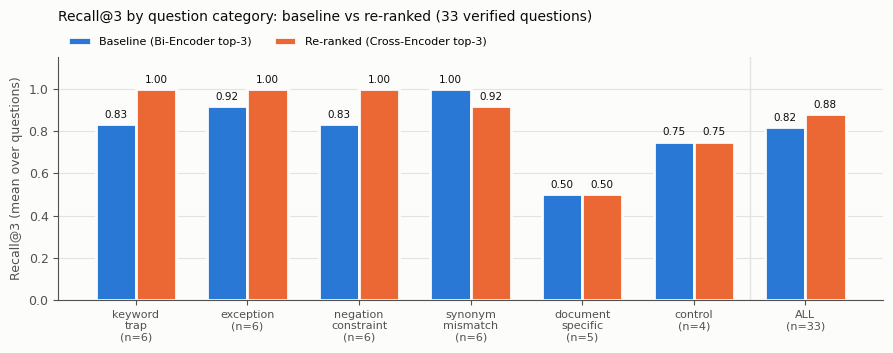

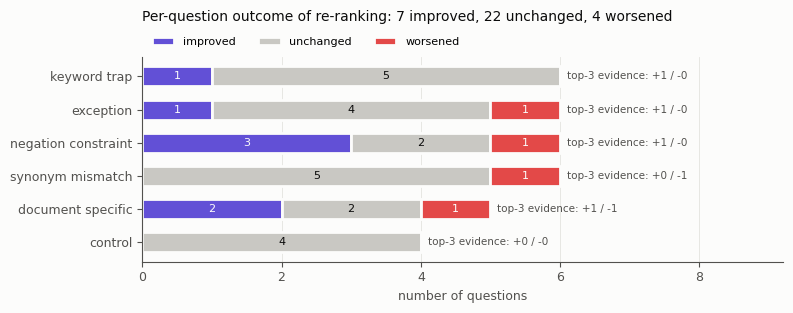

In [31]:
# ---- Figure: Recall@3 per category, baseline vs re-ranked ------------------------------------
rec = recall_table.set_index("category")
cats = CATS + ["ALL"]
x = np.arange(len(cats))
fig, ax = plt.subplots(figsize=(9, 3.6))
w = 0.36
for off, col, color, name in ((-w / 2, "base_recall@3", BASE, "Baseline (Bi-Encoder top-3)"),
                              (w / 2, "rr_recall@3", RR, "Re-ranked (Cross-Encoder top-3)")):
    vals = rec.loc[cats, col].values
    ax.bar(x + off, vals, w, color=color, edgecolor=SURF, linewidth=2, label=name)
    for xi, v in zip(x + off, vals):
        ax.text(xi, v + 0.02, f"{v:.2f}", ha="center", va="bottom", fontsize=7.5, color=INK)
ax.axvline(len(cats) - 1.5, color=GRID, linewidth=1)               # separates the overall average
ax.set_xticks(x, [c.replace("_", "\n") + f"\n(n={int(rec.loc[c, 'n'])})" for c in cats], fontsize=8)
ax.set_ylim(0, 1.15)
ax.set_ylabel("Recall@3 (mean over questions)")
ax.grid(axis="y", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.set_title(f"Recall@3 by question category: baseline vs re-ranked ({int(rec.loc['ALL', 'n'])} verified questions)", pad=26)
ax.legend(frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.0), fontsize=8)
fig.tight_layout()
show_fig(fig, "recall_at3_by_category.png")

# ---- Figure: per-question outcome of re-ranking, by category --------------------------------
ocs = outcome_table.set_index("category").loc[CATS]
fig, ax = plt.subplots(figsize=(8, 3.2))
y = np.arange(len(ocs))
left = np.zeros(len(ocs))
for col, color in (("improved", IMPROVED), ("unchanged", UNCHANGED), ("worsened", WORSENED)):
    v = ocs[col].values.astype(float)
    ax.barh(y, v, left=left, color=color, edgecolor=SURF, linewidth=2, height=0.6, label=col)
    for yi, l, vv in zip(y, left, v):
        if vv:
            ax.text(l + vv / 2, yi, f"{int(vv)}", ha="center", va="center", fontsize=8, color=SURF if color != UNCHANGED else INK)
    left += v
for yi, (cat, r) in zip(y, ocs.iterrows()):                         # how many changed the top-3 evidence
    ax.text(left[yi] + 0.1, yi, f"top-3 evidence: +{int(r.improved_top3)} / -{int(r.worsened_top3)}",
            va="center", fontsize=7.5, color=INK2)
ax.set_yticks(y, [c.replace("_", " ") for c in CATS])
ax.invert_yaxis()
ax.set_xlim(0, left.max() + 3.2)
ax.set_xlabel("number of questions")
tot = outcome_table.set_index("category").loc["ALL"]
ax.set_title(f"Per-question outcome of re-ranking: {int(tot.improved)} improved, {int(tot.unchanged)} "
             f"unchanged, {int(tot.worsened)} worsened", pad=26)
ax.legend(frameon=False, ncol=3, fontsize=8, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.grid(axis="x", color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
fig.tight_layout()
show_fig(fig, "outcome_counts_by_category.png")

In [32]:
# ---- results/results_summary.md: every number above in one Markdown file ---------------------
def results_summary():
    o, ls = retrieval_out["overall"], lat_summary
    tab = {x["key"]: x for x in ls["table"]}
    all_ = recall_table.set_index("category").loc["ALL"]   # unrounded means
    gen_meta = next(iter(gen_cases.values()))
    f3 = lambda x: f"{x:.3f}"
    lines = [
        "# Results summary: Baseline RAG vs Cross-Encoder re-ranking", "",
        "Every number, table and figure below was generated from the saved experiment outputs (Tasks 4-6), after "
        "the validation checks listed at the end. The answer verdicts (correct / partially correct / insufficient "
        "context) and the short interpretive sentences come from the manual review of the actual Gemini answers "
        "(`MANUAL_REVIEW` in the notebook).", "",
        "## Configuration", "",
        f"- **Source:** `{CHUNK_META['source_pdf']}`, IIT Madras B.Tech Ordinances & Regulations, {CHUNK_META['n_pages']} pages",
        f"- **Chunking:** RecursiveCharacterTextSplitter, {CHUNK_META['chunk_size']} chars, overlap "
        f"{CHUNK_META['chunk_overlap']} → {CHUNK_META['n_chunks']} chunks",
        f"- **Bi-Encoder:** `{BI_ENCODER_NAME}`; FAISS `IndexFlatIP` on L2-normalised vectors (= cosine similarity), top-10",
        f"- **Cross-Encoder:** `{CROSS_ENCODER_NAME}`. It re-scores exactly the same top-10; top-3 go to the LLM",
        f"- **LLM:** `{gen_meta['llm_model']}`. Settings {json.dumps(gen_meta['generation_settings'])}, "
        "and one prompt template shared by both pipelines",
        f"- **Evaluation set:** {o['n_questions']} questions, verified against the PDF, in 6 categories; "
        "relevance labels = chunks that contain the evidence quotes",
        f"- **Hardware:** {ls['hardware']['cpu']}, {ls['hardware']['ram_gb']} GB RAM, GPU: {ls['hardware']['gpu']}", "",
        f"## Retrieval metrics (all {o['n_questions']} questions)", "",
        "| | Recall@3 | Hit@3 | MRR@10 | Evidence coverage@3 |", "|---|---|---|---|---|",
        f"| Baseline | {f3(all_['base_recall@3'])} | {f3(all_['base_hit@3'])} | {f3(all_['base_mrr@10'])} | {f3(all_['base_evcov@3'])} |",
        f"| Re-ranked | {f3(all_['rr_recall@3'])} | {f3(all_['rr_hit@3'])} | {f3(all_['rr_mrr@10'])} | {f3(all_['rr_evcov@3'])} |", "",
        f"- **Shared candidate pool:** Recall@10 = {f3(all_['recall@10'])}, identical for both pipelines. "
        f"No relevant chunk reached the top-10 for: {', '.join(o['questions_with_no_relevant_in_top10']) or 'none'}.",
        f"- **Chunks moved:** {o['relevant_chunks_promoted_4to10_into_top3']} relevant chunks were promoted "
        f"from ranks 4-10 into the top-3, and {o['relevant_chunks_demoted_from_top3']} were demoted out of it.",
        f"- **Per-question outcome:** {len(o['improved'])} improved, {len(o['unchanged'])} unchanged, {len(o['worsened'])} worsened.",
        f"  - Only {len(o['improved_top3_coverage'])} improvements ({', '.join(o['improved_top3_coverage'])}) "
        f"and {len(o['worsened_top3_coverage'])} regressions ({', '.join(o['worsened_top3_coverage'])}) "
        "changed the evidence that reaches the LLM.",
        "  - The rest are rank moves only, e.g. a chunk moving within the top-3, or from #9 to #8.",
        "- **Metric definitions:**", "  - Recall@3 = |relevant ∩ top-3| / |relevant|.",
        "  - MRR@10 = 1/rank of the first relevant chunk (0 if none).",
        "  - Evidence coverage@3 = share of evidence quotes present in the top-3.", "",
        "### By category", "",
        md_table(recall_table[["category", "n", "base_recall@3", "rr_recall@3", "base_mrr@10", "rr_mrr@10",
                               "base_evcov@3", "rr_evcov@3"]]), "",
        "![Recall@3 by category](figures/recall_at3_by_category.png)", "",
        "![Outcome counts](figures/outcome_counts_by_category.png)", "",
        "## Confirmed rescues and regressions", "",
        "A **rescue** means: relevant evidence missing from the baseline top-3 was in the baseline top-10 and was "
        "promoted into the top-3 by the Cross-Encoder. Cosine similarities and Cross-Encoder logits are on different "
        "scales, so only ranks are compared across pipelines.", "",
    ]
    for qid in CASE_ORDER:
        r, rv = by_q[qid], review[qid]
        cands = {c["chunk_id"]: c for c in r["candidates"]}
        kind = ("strict rescue" if r["strict_rescue"] else "rescue") if r["rescue"] else "regression"
        lines += [f"- **{qid}** ({r['category']}, {kind}): " + ", ".join(
                      f"chunk {s['chunk_id']} #{s['baseline_rank']}→#{s['reranked_rank']}" for s in r["relevant_rank_shifts"]) + ".",
                  f"  - Top-3: {r['baseline']['top3']} → {r['reranked']['top3']}.",
                  f"  - Evidence coverage {r['baseline']['evidence_cov@3']:.2f} → {r['reranked']['evidence_cov@3']:.2f}.",
                  "  - Scores: " + "; ".join(f"chunk {s['chunk_id']}: cosine {cands[s['chunk_id']]['cosine_score']:.3f}, "
                                             f"CE logit {cands[s['chunk_id']]['ce_score']:.2f}" for s in r["relevant_rank_shifts"]) + ".",
                  f"  - Answer 1: *{rv['answer_1_verdict']}*. Answer 2: *{rv['answer_2_verdict']}*. "
                  f"Answer change: **{rv['answer_change']}**."]
    als = stress_report["answer_level_summary"]
    lines += ["", md_table(rescue_table, 2), "",
              "![Rank shifts](figures/rank_shifts_relevant_chunks.png)", "",
              "![Top-10 before/after](figures/top10_before_after.png)", "",
              "## Answer changes (manual review of actual Gemini outputs)", "",
              f"- **Answers improved: {', '.join(als['improved'])}.** In every rescue, the baseline either declined for "
              "lack of evidence (KT-02, DS-02, NG-06) or left out the decisive clause (EX-05). The re-ranked answer was correct.",
              "- **Negation case NG-06** was found by a retrieval-only screen of 24 negation phrasings "
              f"(`stress_test/negation_screen.json`): {neg_screen['n_screen_hits']} screen hits, "
              f"{neg_screen['n_screen_hits'] - neg_screen['n_accepted']} rejected on checking, {neg_screen['n_accepted']} kept.",
              f"- **Answers worsened: {', '.join(als['worsened'])}.** The key chunk dropped out of the top-3, and Answer 2 "
              "declined for lack of evidence.",
              f"- **Fabrications found:** {als['fabrications_found']}. When evidence was missing, the model said so instead of guessing.",
              "- **Citation errors:** one page-citation slip in the reviewed answers, a wrong page within a two-page chunk "
              "(NG-06 Answer 2).",
              "- **Retrieval vs answer quality:** in all six cases the answer moved in the same direction as the retrieval "
              "change, i.e. with whether the deciding chunk was in the context.",
              "- Full side-by-side answers: `tables/answers_side_by_side.md`.", "",
              "### Repeated generation (5 runs per pipeline per case)", "",
              "Each case was answered 5 times by both pipelines on the same backend (Vertex AI), with the same retrieval, "
              "prompt and settings. Verdicts were assigned after reading every answer. The key-fact column is an automatic "
              "regex check for the facts in the reference answer (patterns stored in `stress_test/generation_repeats.json`).", "",
              "| Case | Answer 1 verdicts | Answer 2 verdicts | A1 with all key facts | A2 with all key facts |",
              "|---|---|---|---|---|"]
    lines += [f"| {r['query_id']} | " + ", ".join(f"{k} ×{v}" for k, v in r["answer_1_verdicts"].items()) + " | "
              + ", ".join(f"{k} ×{v}" for k, v in r["answer_2_verdicts"].items())
              + f" | {r['answer_1_all_key_facts']}/{r['n_runs']} | {r['answer_2_all_key_facts']}/{r['n_runs']} |"
              for r in stress_report["repeat_runs"]["cases"]]
    sc = ls["scaling"]
    lines += ["", "- The verdict was identical in all 5 runs for every case; only the wording changed "
              "(e.g. KT-02 Answer 2 quotes the conflicting O.5 clause in runs 2-3 only).",
              "- Full runs: `stress_test/generation_repeats.json`; summary: `stress_test/generation_repeats_summary.csv`.", "",
              "## Latency (ms unless stated)", "", "| Component | n | mean | median | std |", "|---|---|---|---|---|"]
    lines += [f"| {tab[k]['component']} | {tab[k]['n']} | {tab[k]['mean']:.3f} | {tab[k]['median']:.3f} | {tab[k]['std']:.3f} |"
              for k in ("query_embed_ms", "faiss_search_ms", "ce_score_ms", "sort_select_ms", "p1_retrieval_ms",
                        "p2_retrieval_ms", "rerank_overhead_ms", "gen1_ms", "gen2_ms", "p1_end_to_end_ms", "p2_end_to_end_ms")]
    lines += ["",
              f"- **Re-ranking cost:** it adds **{ls['rerank_overhead_mean_ms']:.0f} ms** per query (mean), so the retrieval "
              f"side is {ls['retrieval_slowdown_mean_ratio']:.1f}x slower (mean) and {ls['retrieval_slowdown_median_ratio']:.1f}x slower (median).",
              f"- **End-to-end:** P2/P1 = {ls['end_to_end_slowdown_median_ratio']:.2f}x by median and "
              f"{ls['end_to_end_slowdown_mean_ratio']:.2f}x by mean.",
              f"  - Re-ranking is {ls['rerank_share_of_p2_end_to_end']:.1%} of P2's mean end-to-end time.",
              f"  - Gemini latency varies strongly between identical requests (Answer 1: {lat_gen.gen1_ms.min() / 1000:.1f}-"
              f"{lat_gen.gen1_ms.max() / 1000:.1f} s, Answer 2: {lat_gen.gen2_ms.min() / 1000:.1f}-{lat_gen.gen2_ms.max() / 1000:.1f} s), "
              f"far more than the {ls['rerank_overhead_mean_ms']:.0f} ms re-ranking step, so the end-to-end ratios reflect Gemini "
              f"variance. With {len(lat_gen)} pairs, the end-to-end difference is not statistically resolved.",
              f"- **Cross-Encoder scaling:** 10 pairs = {sc['cross_encoder_vs_pairs_ms']['10']['median']:.0f} ms; the whole "
              f"85-chunk corpus = {sc['cross_encoder_vs_pairs_ms']['85']['median']:.0f} ms per query.",
              f"  - Linear extrapolation: about {sc['cross_encoder_full_corpus_extrapolation_ms']['10000'] / 60000:.0f} min "
              "per query for 10k chunks.",
              f"- **FAISS scaling:** exact search over 100k vectors (synthetic) = "
              f"{sc['faiss_vs_index_size_ms']['100000 (synthetic)']['median']:.1f} ms.",
              f"- **Cost estimate:** ≈ ${ls['cost_estimate_usd']['estimated_cost_usd']:.3f} for "
              f"{ls['cost_estimate_usd']['successful_calls']} Gemini answers (assumed list prices).", "",
              "![Latency comparison](figures/latency_comparison.png)", "", "![Latency breakdown](figures/latency_breakdown.png)", "",
              "![Scaling](figures/latency_scaling.png)", "", "## Limitations", ""]
    lines += [f"- {x}" for x in stress_report["limitations"]]
    lines += ["- Latency was measured on one laptop CPU without a GPU. Gemini latency includes network and server queueing, "
              "and Vertex AI returned transient 429 errors, which were retried and are excluded from the measurements.",
              f"- All reviewed answers (and their 5-run repeats) and the Gemini latency runs used one backend: "
              f"{lat_gen.backend.iloc[0]}, model {gen_meta['llm_model']}, identical settings.",
              "- Retrieval metrics depend on the relevance labels (chunks containing the evidence quotes). "
              "Chunk overlap means some quotes occur in two chunks.", "",
              "## Validation of the inputs", "", f"{n_pass}/{len(checks)} checks passed.", ""]
    lines += [f"- {'PASS' if c['passed'] else 'FAIL'}: {c['check']}" for c in checks]
    lines += ["", "## Files", "", "- `tables/`:", "  - `recall_summary`", "  - `outcome_counts`",
              "  - `rank_shifts_relevant_chunks`", "  - `rescues_and_regressions`", "  - `latency_comparison` (.csv + .md)",
              "  - `answers_side_by_side.md`", "- `figures/`:", "  - `recall_at3_by_category.png`",
              "  - `outcome_counts_by_category.png`", "  - `rank_shifts_relevant_chunks.png`", "  - `top10_before_after.png`",
              "  - `latency_comparison.png`", "  - `latency_breakdown.png`", "  - `latency_scaling.png`",
              "- Raw sources: `stress_test/`, `latency/`, `../data/evaluation/questions.json`"]
    return "\n".join(lines) + "\n"

summary_md = results_summary()
saved_md = (RESULTS / "results_summary.md").read_text()
print("results_summary.md identical to the saved one:", summary_md == saved_md)
if WRITE_RESULTS:
    (RESULTS / "results_summary.md").write_text(summary_md)

results_summary.md identical to the saved one: True


### Summary of the measured results

- **Retrieval, 33 questions:** Recall@3 0.818 → 0.879 and MRR@10 0.801 → 0.863.
  - 4 verified rescues: KT-02 keyword trap (chunk 21 #4→#1), EX-05 exception (chunk 62 #5→#2), DS-02 near-identical tables (chunk 31 #7→#1) and NG-06 negation (chunk 76 #4→#1). Each turned a refusal or an incomplete Answer 1 into a correct Answer 2.
  - 2 regressions: SY-03 and DS-05, where the key chunk dropped out of the top-3 and Answer 2 lost the information.
  - 1 question (C-04) had no relevant chunk in the top-10, so re-ranking could not help.
- **Latency:** re-ranking adds ≈ 265 ms per query, making retrieval ≈ 27× slower. End-to-end, Gemini (≈ 3.3–4.5 s median, up to 26 s) dominates; its run-to-run variance is far larger than the re-ranking step, so the end-to-end ratios (0.78× median, 1.34× mean) do not resolve the re-ranking cost.
- **Scaling:** Cross-Encoder cost grows linearly with the number of chunks scored (≈ 2.7 s per query for this 85-chunk corpus). Bi-Encoder search over 100k vectors takes only milliseconds. That is why the Cross-Encoder re-ranks a small candidate set instead of the whole collection.

The numbers above come from the saved runs. The live cells in this notebook reproduce the retrieval results exactly; timings vary slightly from run to run.